# DS Kaggle MIT-WPU 2026
## Sensor Anomaly Classification

### Objective

The objective of this competition is to predict whether a sensor observation
corresponds to an anomaly.

The notebook follows a complete machine-learning workflow:

1. Dataset inspection
2. Exploratory Data Analysis
3. Missing-value analysis
4. Duplicate analysis
5. Class imbalance analysis
6. Train/Test distribution analysis
7. Data preprocessing
8. Feature engineering
9. Baseline modeling
10. Classical machine learning
11. Advanced tree-based models
12. Cross-validation
13. Hyperparameter tuning
14. Threshold optimization
15. Out-of-fold predictions
16. Ensemble testing
17. Feature importance
18. Final model selection
19. Full-data training
20. Kaggle submission generation

The main optimization target is **F1 score**, while also monitoring
accuracy and class-wise performance.

In [12]:
# ============================================================
# CELL 1 — IMPORTS & CONFIGURATION
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")
print(f"Random State: {RANDOM_STATE}")

Libraries imported successfully.
Random State: 42


In [14]:
# ============================================================
# CELL 2 — LOAD KAGGLE COMPETITION DATA
# ============================================================

TRAIN_PATH = "/kaggle/input/competitions/ds-kaggle-mit-wpu/train.parquet"
TEST_PATH = "/kaggle/input/competitions/ds-kaggle-mit-wpu/test.parquet"
SAMPLE_PATH = "/kaggle/input/competitions/ds-kaggle-mit-wpu/sample_submission.parquet"

# Load Parquet files
train = pd.read_parquet(TRAIN_PATH)
test = pd.read_parquet(TEST_PATH)
sample_submission = pd.read_parquet(SAMPLE_PATH)

print("=" * 70)
print("DATASETS LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Train shape             : {train.shape}")
print(f"Test shape              : {test.shape}")
print(f"Sample submission shape : {sample_submission.shape}")

DATASETS LOADED SUCCESSFULLY
Train shape             : (1639424, 7)
Test shape              : (409856, 7)
Sample submission shape : (50, 2)


In [15]:
# ============================================================
# CELL 3 — FIRST LOOK
# ============================================================

print("=" * 70)
print("TRAIN — FIRST 5 ROWS")
print("=" * 70)

display(train.head())

print("\n" + "=" * 70)
print("TEST — FIRST 5 ROWS")
print("=" * 70)

display(test.head())

print("\n" + "=" * 70)
print("SAMPLE SUBMISSION — FIRST 10 ROWS")
print("=" * 70)

display(sample_submission.head(10))

TRAIN — FIRST 5 ROWS


,Date,X1,X2,X3,X4,X5,target
0,2020-12-16,1.518921,5.463154,1.0,2.718282,2.890372,0
1,2020-12-16,1.546509,5.458010,1.0,2.718282,2.833213,1
2,2020-12-16,1.645427,5.456560,1.0,7.389056,2.890372,1
3,2020-12-16,1.652022,5.458479,1.0,2.718282,2.890372,1
4,2020-12-16,1.695538,5.466709,1.0,2.718282,2.890372,0



TEST — FIRST 5 ROWS


,ID,Date,X1,X2,X3,X4,X5
0,0,2020-12-16,1.685395,5.463917,1.0,7.389056,2.890372
1,1,2020-12-16,1.488844,5.454936,1.0,7.389056,2.890372
2,2,2020-12-16,1.164160,5.471136,1.0,1.000000,2.890372
3,3,2020-12-16,1.000000,5.467385,1.0,1.000000,2.890372
4,4,2020-12-16,1.000000,5.453995,1.0,1.000000,2.833213



SAMPLE SUBMISSION — FIRST 10 ROWS


,ID,target
0,409856,0
1,409857,0
2,409858,0
3,409859,0
4,409860,0
5,409861,0
6,409862,0
7,409863,0
8,409864,0
9,409865,0


In [16]:
# ============================================================
# CELL 4 — DATASET STRUCTURE
# ============================================================

print("=" * 70)
print("TRAIN DATA TYPES")
print("=" * 70)

display(train.dtypes.to_frame("Data Type"))

print("\n" + "=" * 70)
print("TEST DATA TYPES")
print("=" * 70)

display(test.dtypes.to_frame("Data Type"))

print("\n" + "=" * 70)
print("TRAIN MEMORY USAGE")
print("=" * 70)

train.info(memory_usage="deep")

print("\n" + "=" * 70)
print("TEST MEMORY USAGE")
print("=" * 70)

test.info(memory_usage="deep")

TRAIN DATA TYPES


,Data Type
Date,datetime64[ns]
X1,float64
X2,float64
X3,float64
X4,float64
X5,float64
target,object



TEST DATA TYPES


,Data Type
ID,int64
Date,datetime64[ns]
X1,float64
X2,float64
X3,float64
X4,float64
X5,float64



TRAIN MEMORY USAGE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1639424 entries, 0 to 1639423
Data columns (total 7 columns):
 #   Column  Non-Null Count    Dtype         
---  ------  --------------    -----         
 0   Date    1639424 non-null  datetime64[ns]
 1   X1      1639424 non-null  float64       
 2   X2      1639424 non-null  float64       
 3   X3      1639424 non-null  float64       
 4   X4      1639424 non-null  float64       
 5   X5      1639424 non-null  float64       
 6   target  1639424 non-null  object        
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 153.2 MB

TEST MEMORY USAGE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 409856 entries, 0 to 409855
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   ID      409856 non-null  int64         
 1   Date    409856 non-null  datetime64[ns]
 2   X1      409856 non-null  float64       
 3   X2      409856 non-null

In [17]:
# ============================================================
# CELL 5 — AUTOMATIC COLUMN IDENTIFICATION
# ============================================================

# Columns present in train but not test are potential target columns
train_only_columns = sorted(list(set(train.columns) - set(test.columns)))

# Columns present in both datasets
common_columns = sorted(list(set(train.columns) & set(test.columns)))

# Columns present in test but not train
test_only_columns = sorted(list(set(test.columns) - set(train.columns)))

# Potential target columns
potential_target_columns = [
    col for col in train_only_columns
    if col.lower() not in ["id", "index"]
]

# Potential ID columns
potential_id_columns = [
    col for col in test.columns
    if (
        col.lower() in ["id", "index"] 
        or col.lower().endswith("_id")
        or col.lower().startswith("id_")
    )
]

# Numerical and categorical columns
numerical_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("=" * 70)
print("AUTOMATIC COLUMN ANALYSIS")
print("=" * 70)

print("\nTrain-only columns:")
print(train_only_columns)

print("\nTest-only columns:")
print(test_only_columns)

print("\nCommon columns:")
print(common_columns)

print("\nPotential target columns:")
print(potential_target_columns)

print("\nPotential ID columns in test:")
print(potential_id_columns)

print("\nNumerical columns in train:")
print(numerical_columns)

print("\nCategorical/object columns in train:")
print(categorical_columns)

AUTOMATIC COLUMN ANALYSIS

Train-only columns:
['target']

Test-only columns:
['ID']

Common columns:
['Date', 'X1', 'X2', 'X3', 'X4', 'X5']

Potential target columns:
['target']

Potential ID columns in test:
['ID']

Numerical columns in train:
['X1', 'X2', 'X3', 'X4', 'X5']

Categorical/object columns in train:
['Date', 'target']


In [18]:
# ============================================================
# CELL 6 — MISSING VALUES & DUPLICATES
# ============================================================

def missing_report(df, name):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100,
        "dtype": df.dtypes.astype(str)
    })
    
    report = report.sort_values(
        "missing_percentage",
        ascending=False
    )
    
    print(f"\n{'=' * 70}")
    print(f"{name} — MISSING VALUE REPORT")
    print("=" * 70)
    
    display(report)

    
missing_report(train, "TRAIN")
missing_report(test, "TEST")

print("\n" + "=" * 70)
print("DUPLICATE ANALYSIS")
print("=" * 70)

train_duplicate_count = train.duplicated().sum()
test_duplicate_count = test.duplicated().sum()

print(f"Duplicate rows in train: {train_duplicate_count:,}")
print(f"Duplicate rows in test : {test_duplicate_count:,}")

print(f"\nTrain duplicate %: {train_duplicate_count / len(train) * 100:.4f}%")
print(f"Test duplicate % : {test_duplicate_count / len(test) * 100:.4f}%")


TRAIN — MISSING VALUE REPORT


,missing_count,missing_percentage,dtype
Date,0,0.0,datetime64[ns]
X1,0,0.0,float64
X2,0,0.0,float64
X3,0,0.0,float64
X4,0,0.0,float64
X5,0,0.0,float64
target,0,0.0,object



TEST — MISSING VALUE REPORT


,missing_count,missing_percentage,dtype
ID,0,0.0,int64
Date,0,0.0,datetime64[ns]
X1,0,0.0,float64
X2,0,0.0,float64
X3,0,0.0,float64
X4,0,0.0,float64
X5,0,0.0,float64



DUPLICATE ANALYSIS
Duplicate rows in train: 57,315
Duplicate rows in test : 0

Train duplicate %: 3.4960%
Test duplicate % : 0.0000%


In [21]:
# ============================================================
# CELL 7 — TARGET & UNIQUE VALUE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# Identify target
# ------------------------------------------------------------

if len(potential_target_columns) == 1:
    TARGET_COLUMN = potential_target_columns[0]
else:
    TARGET_COLUMN = None

print("=" * 70)
print("TARGET ANALYSIS")
print("=" * 70)

if TARGET_COLUMN is not None:
    
    print(f"Detected target column: {TARGET_COLUMN}")
    
    target_counts = train[TARGET_COLUMN].value_counts(dropna=False)
    target_percentages = train[TARGET_COLUMN].value_counts(
        normalize=True,
        dropna=False
    ) * 100
    
    target_report = pd.DataFrame({
        "count": target_counts,
        "percentage": target_percentages.round(4)
    })
    
    display(target_report)
    
    print("\nNumber of target classes:", train[TARGET_COLUMN].nunique())
    print("Target values:", train[TARGET_COLUMN].unique())
    
    if train[TARGET_COLUMN].nunique() > 1:
        imbalance_ratio = (
            target_counts.max() / target_counts.min()
        )
        print(f"Imbalance ratio: {imbalance_ratio:.4f}")
    
else:
    print("Target could not be automatically identified.")
    print("Potential target columns:", potential_target_columns)


# ------------------------------------------------------------
# Unique values for every column
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("UNIQUE VALUE ANALYSIS")
print("=" * 70)

unique_report = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique_values": train.nunique(dropna=False),
    "missing_values": train.isna().sum()
})

unique_report["unique_percentage"] = (
    unique_report["unique_values"] / len(train) * 100
)

display(unique_report.sort_values("unique_values"))


# ------------------------------------------------------------
# Descriptive statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL DESCRIPTIVE STATISTICS")
print("=" * 70)

display(
    train.describe(
        include="all"
    ).T
)

TARGET ANALYSIS
Detected target column: target


,count,percentage
target,,
0,1625386,99.1437
1,14038,0.8563



Number of target classes: 2
Target values: ['0' '1']
Imbalance ratio: 115.7847

UNIQUE VALUE ANALYSIS


,dtype,unique_values,missing_values,unique_percentage
target,object,2,0,0.000122
X5,float64,32,0,0.001952
X4,float64,81,0,0.004941
X3,float64,88,0,0.005368
X1,float64,526,0,0.032084
Date,datetime64[ns],1432,0,0.087348
X2,float64,2812,0,0.171524



NUMERICAL DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,1639424,NaN,NaN,NaN,2022-12-03 07:23:43.817145600,2020-12-16 00:00:00,2021-12-10 00:00:00,2022-11-30 00:00:00,2023-11-23 00:00:00,2024-12-11 00:00:00,NaN
X1,1639424.0,NaN,NaN,NaN,1.139258,1.0,1.049171,1.105171,1.214096,4.01485,0.139199
X2,1639424.0,NaN,NaN,NaN,5.488189,5.412539,5.480597,5.488979,5.496717,5.541852,0.013428
X3,1639424.0,NaN,NaN,NaN,411038848845335903677077532966912.0,1.0,1.0,1.0,1.0,165163625499400180986996598802797821952.0,234615574101624635452636899651354624.0
X4,1639424.0,NaN,NaN,NaN,270632260752154046441084420096.0,1.0,1.0,1.0,2.718282,55406223843935098344518031635382272.0,58129880139751736257085972676608.0
X5,1639424.0,NaN,NaN,NaN,1.187219,0.0,0.0,0.693147,2.890372,3.465736,1.304814
target,1639424,2,0,1625386,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Initial Dataset Findings

The initial inspection reveals a binary anomaly classification problem with a severe class imbalance.

### Dataset

- Training observations: 1,639,424
- Test observations: 409,856
- Sensor features: X1, X2, X3, X4, X5
- Temporal feature: Date
- Target: target
- Test identifier: ID

### Missing Values

No missing values are currently present in either training or test data.

Therefore, missing-value imputation is not required at this stage.

### Class Imbalance

The target contains two classes:

- Class 0: approximately 99.14%
- Class 1: approximately 0.86%

This represents an imbalance ratio of approximately 116:1.

Because the competition evaluates F1 score and class-wise performance, accuracy alone would be misleading. Particular attention will therefore be given to:

- Precision
- Recall
- F1-score
- Class-wise F1
- Confusion matrix

### Duplicate Rows

Approximately 3.5% of the training rows are exact duplicates, while the test set contains no duplicate rows.

These observations will NOT be removed automatically. We will first determine whether duplicated observations have consistent target labels. Removing them blindly could eliminate useful information.

### Temporal Structure

The dataset contains a Date column spanning multiple years. We will investigate whether the data has temporal ordering and whether anomalies are concentrated in particular periods.

This is important because a random train/validation split may not accurately represent the competition's test distribution if the test data corresponds to a later time period.

DATE ANALYSIS

TRAIN DATE RANGE
Minimum: 2020-12-16 00:00:00
Maximum: 2024-12-11 00:00:00

TEST DATE RANGE
Minimum: 2020-12-16 00:00:00
Maximum: 2024-12-11 00:00:00

Unique dates:
Train: 1432
Test : 1432

ANOMALY RATE BY YEAR


,total,anomalies,anomaly_rate_%
year,,,
2020,17622,429,2.434457
2021,417268,5246,1.257226
2022,421434,3614,0.857548
2023,417068,3058,0.733214
2024,366032,1691,0.461981



ANOMALY RATE BY MONTH


,total,anomalies,anomaly_rate_%
month,,,
1,139652,2179,1.560307
2,129225,1112,0.860515
3,140084,1252,0.893749
4,134292,950,0.707414
5,141832,875,0.616927
6,134452,645,0.479725
7,141437,512,0.361999
8,134974,691,0.511950
9,132620,838,0.631881


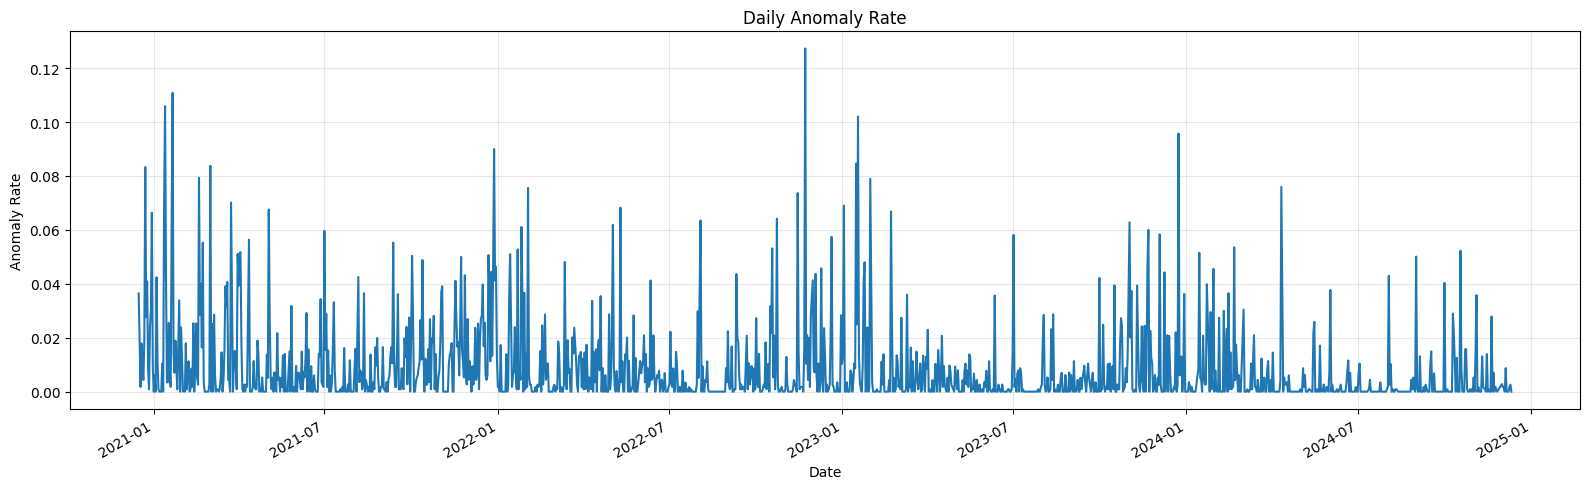

In [22]:
# ============================================================
# CELL 9 — TEMPORAL / DATE ANALYSIS
# ============================================================

print("=" * 70)
print("DATE ANALYSIS")
print("=" * 70)

print("\nTRAIN DATE RANGE")
print("Minimum:", train["Date"].min())
print("Maximum:", train["Date"].max())

print("\nTEST DATE RANGE")
print("Minimum:", test["Date"].min())
print("Maximum:", test["Date"].max())

print("\nUnique dates:")
print("Train:", train["Date"].nunique())
print("Test :", test["Date"].nunique())

# ------------------------------------------------------------
# Extract useful temporal components for EDA ONLY
# ------------------------------------------------------------

date_eda = train[["Date", "target"]].copy()

date_eda["year"] = date_eda["Date"].dt.year
date_eda["month"] = date_eda["Date"].dt.month
date_eda["day"] = date_eda["Date"].dt.day
date_eda["day_of_week"] = date_eda["Date"].dt.dayofweek
date_eda["hour"] = date_eda["Date"].dt.hour

# ------------------------------------------------------------
# Target rate by year
# ------------------------------------------------------------

year_summary = (
    date_eda
    .groupby("year")["target"]
    .agg(
        total="count",
        anomalies=lambda x: (x == "1").sum()
    )
)

year_summary["anomaly_rate_%"] = (
    year_summary["anomalies"] /
    year_summary["total"] * 100
)

print("\n" + "=" * 70)
print("ANOMALY RATE BY YEAR")
print("=" * 70)

display(year_summary)


# ------------------------------------------------------------
# Target rate by month
# ------------------------------------------------------------

month_summary = (
    date_eda
    .groupby("month")["target"]
    .agg(
        total="count",
        anomalies=lambda x: (x == "1").sum()
    )
)

month_summary["anomaly_rate_%"] = (
    month_summary["anomalies"] /
    month_summary["total"] * 100
)

print("\n" + "=" * 70)
print("ANOMALY RATE BY MONTH")
print("=" * 70)

display(month_summary)


# ------------------------------------------------------------
# Plot anomaly rate over time
# ------------------------------------------------------------

daily_anomaly_rate = (
    date_eda
    .assign(is_anomaly=(date_eda["target"] == "1").astype(int))
    .groupby("Date")["is_anomaly"]
    .mean()
)

plt.figure(figsize=(16, 5))

daily_anomaly_rate.plot()

plt.title("Daily Anomaly Rate")
plt.xlabel("Date")
plt.ylabel("Anomaly Rate")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# CELL 10 — ID & SAMPLE SUBMISSION ANALYSIS
# ============================================================

print("=" * 70)
print("TEST ID ANALYSIS")
print("=" * 70)

print("ID dtype:", test["ID"].dtype)
print("Number of unique IDs:", test["ID"].nunique())
print("Number of rows:", len(test))

print("\nFirst 10 IDs:")
display(test["ID"].head(10))

print("\nLast 10 IDs:")
display(test["ID"].tail(10))

print("\nID descriptive statistics:")
display(test["ID"].describe())


# ------------------------------------------------------------
# Sample submission
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE SUBMISSION")
print("=" * 70)

print("Shape:", sample_submission.shape)
print("Columns:", sample_submission.columns.tolist())

display(sample_submission.head(20))

print("\nSample submission dtypes:")
display(sample_submission.dtypes.to_frame("dtype"))

print("\nUnique values:")
for col in sample_submission.columns:
    print(f"\n{col}:")
    print(sample_submission[col].unique()[:20])


# ------------------------------------------------------------
# Check whether sample IDs exist in test
# ------------------------------------------------------------

if "ID" in sample_submission.columns and "ID" in test.columns:
    
    sample_ids_in_test = sample_submission["ID"].isin(test["ID"]).sum()
    
    print("\n" + "=" * 70)
    print("SAMPLE ID VALIDATION")
    print("=" * 70)
    
    print(
        f"Sample submission IDs found in test: "
        f"{sample_ids_in_test}/{len(sample_submission)}"
    )

TEST ID ANALYSIS
ID dtype: int64
Number of unique IDs: 409856
Number of rows: 409856

First 10 IDs:


0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: ID, dtype: int64


Last 10 IDs:


409846    409846
409847    409847
409848    409848
409849    409849
409850    409850
409851    409851
409852    409852
409853    409853
409854    409854
409855    409855
Name: ID, dtype: int64


ID descriptive statistics:


count    409856.000000
mean     204927.500000
std      118315.380301
min           0.000000
25%      102463.750000
50%      204927.500000
75%      307391.250000
max      409855.000000
Name: ID, dtype: float64


SAMPLE SUBMISSION
Shape: (50, 2)
Columns: ['ID', 'target']


,ID,target
0,409856,0
1,409857,0
2,409858,0
3,409859,0
4,409860,0
5,409861,0
6,409862,0
7,409863,0
8,409864,0
9,409865,0



Sample submission dtypes:


,dtype
ID,int64
target,object



Unique values:

ID:
[409856 409857 409858 409859 409860 409861 409862 409863 409864 409865
 409866 409867 409868 409869 409870 409871 409872 409873 409874 409875]

target:
['0' '1']

SAMPLE ID VALIDATION
Sample submission IDs found in test: 0/50


In [25]:
# ============================================================
# CELL 11 — DUPLICATE CONSISTENCY ANALYSIS
# ============================================================

feature_columns = ["Date", "X1", "X2", "X3", "X4", "X5"]

print("=" * 70)
print("DUPLICATE CONSISTENCY ANALYSIS")
print("=" * 70)

# Count duplicated feature combinations
duplicate_mask = train.duplicated(
    subset=feature_columns,
    keep=False
)

duplicate_feature_rows = train.loc[duplicate_mask].copy()

print("Rows involved in duplicated feature combinations:",
      f"{len(duplicate_feature_rows):,}")

print(
    "Percentage of training data:",
    f"{len(duplicate_feature_rows) / len(train) * 100:.3f}%"
)


# ------------------------------------------------------------
# Check whether duplicate feature combinations have
# conflicting targets
# ------------------------------------------------------------

duplicate_groups = (
    duplicate_feature_rows
    .groupby(feature_columns, dropna=False)["target"]
    .nunique()
)

conflicting_groups = duplicate_groups[
    duplicate_groups > 1
]

consistent_groups = duplicate_groups[
    duplicate_groups == 1
]

print("\nNumber of duplicated feature groups:", len(duplicate_groups))
print("Consistent duplicate groups:", len(consistent_groups))
print("Conflicting duplicate groups:", len(conflicting_groups))

print(
    "\nPercentage of duplicate groups with conflicting targets:",
    f"{len(conflicting_groups) / max(len(duplicate_groups), 1) * 100:.4f}%"
)


# ------------------------------------------------------------
# Show examples if conflicts exist
# ------------------------------------------------------------

if len(conflicting_groups) > 0:
    
    print("\n" + "=" * 70)
    print("EXAMPLES OF CONFLICTING DUPLICATES")
    print("=" * 70)
    
    conflicting_index = conflicting_groups.index
    
    examples = (
        train
        .set_index(feature_columns)
        .loc[conflicting_index]
        .reset_index()
    )
    
    display(examples.head(20))

else:
    
    print("\nNo conflicting duplicate feature combinations found.")

DUPLICATE CONSISTENCY ANALYSIS
Rows involved in duplicated feature combinations: 108,412
Percentage of training data: 6.613%

Number of duplicated feature groups: 51083
Consistent duplicate groups: 51069
Conflicting duplicate groups: 14

Percentage of duplicate groups with conflicting targets: 0.0274%

EXAMPLES OF CONFLICTING DUPLICATES


,Date,X1,X2,X3,X4,X5,target
0,2020-12-26,1.000000,5.471892,1.0,2.718282,2.890372,0
1,2020-12-26,1.000000,5.471892,1.0,2.718282,2.890372,1
2,2021-01-23,1.233678,5.478094,1.0,1.000000,0.000000,0
3,2021-01-23,1.233678,5.478094,1.0,1.000000,0.000000,1
4,2021-03-17,1.094174,5.466329,1.0,1.000000,2.890372,1
5,2021-03-17,1.094174,5.466329,1.0,1.000000,2.890372,0
6,2021-09-01,1.000000,5.474663,1.0,1.000000,2.890372,1
7,2021-09-01,1.000000,5.474663,1.0,1.000000,2.890372,0
8,2021-11-02,1.000000,5.474830,1.0,1.000000,0.000000,1
9,2021-11-02,1.000000,5.474830,1.0,1.000000,0.000000,0


SENSOR STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,IQR,skewness
X1,1639424.0,1.139258e+00,1.391992e-01,1.000000,1.049171,1.105171,1.214096,4.014850e+00,1.105171,0.164926,1.936289
X2,1639424.0,5.488189e+00,1.342811e-02,5.412539,5.480597,5.488979,5.496717,5.541852e+00,5.488979,0.016120,-0.380227
X3,1639424.0,4.110388e+32,2.346156e+35,1.000000,1.000000,1.000000,1.000000,1.651636e+38,1.000000,0.000000,660.657945
X4,1639424.0,2.706323e+29,5.812988e+31,1.000000,1.000000,1.000000,2.718282,5.540622e+34,1.000000,1.718282,664.876766
X5,1639424.0,1.187219e+00,1.304814e+00,0.000000,0.000000,0.693147,2.890372,3.465736e+00,0.693147,2.890372,0.512101


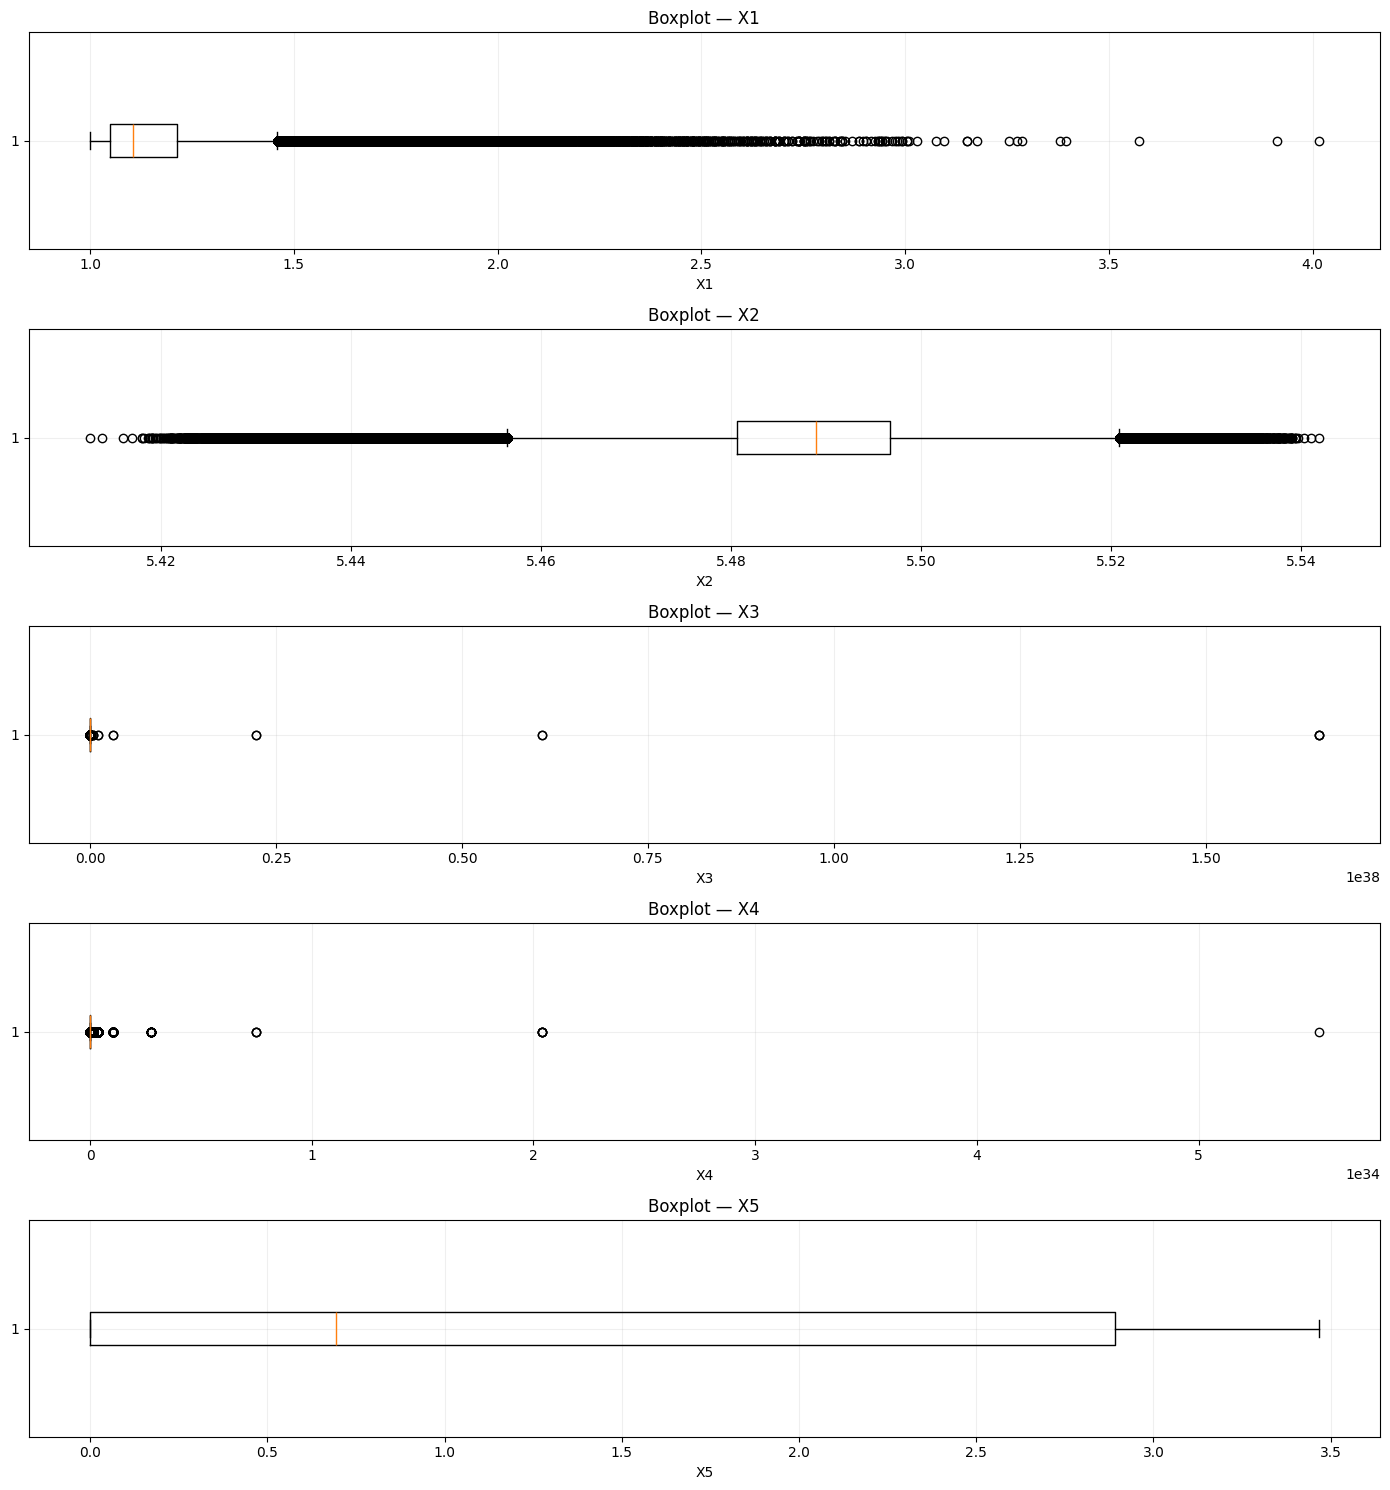

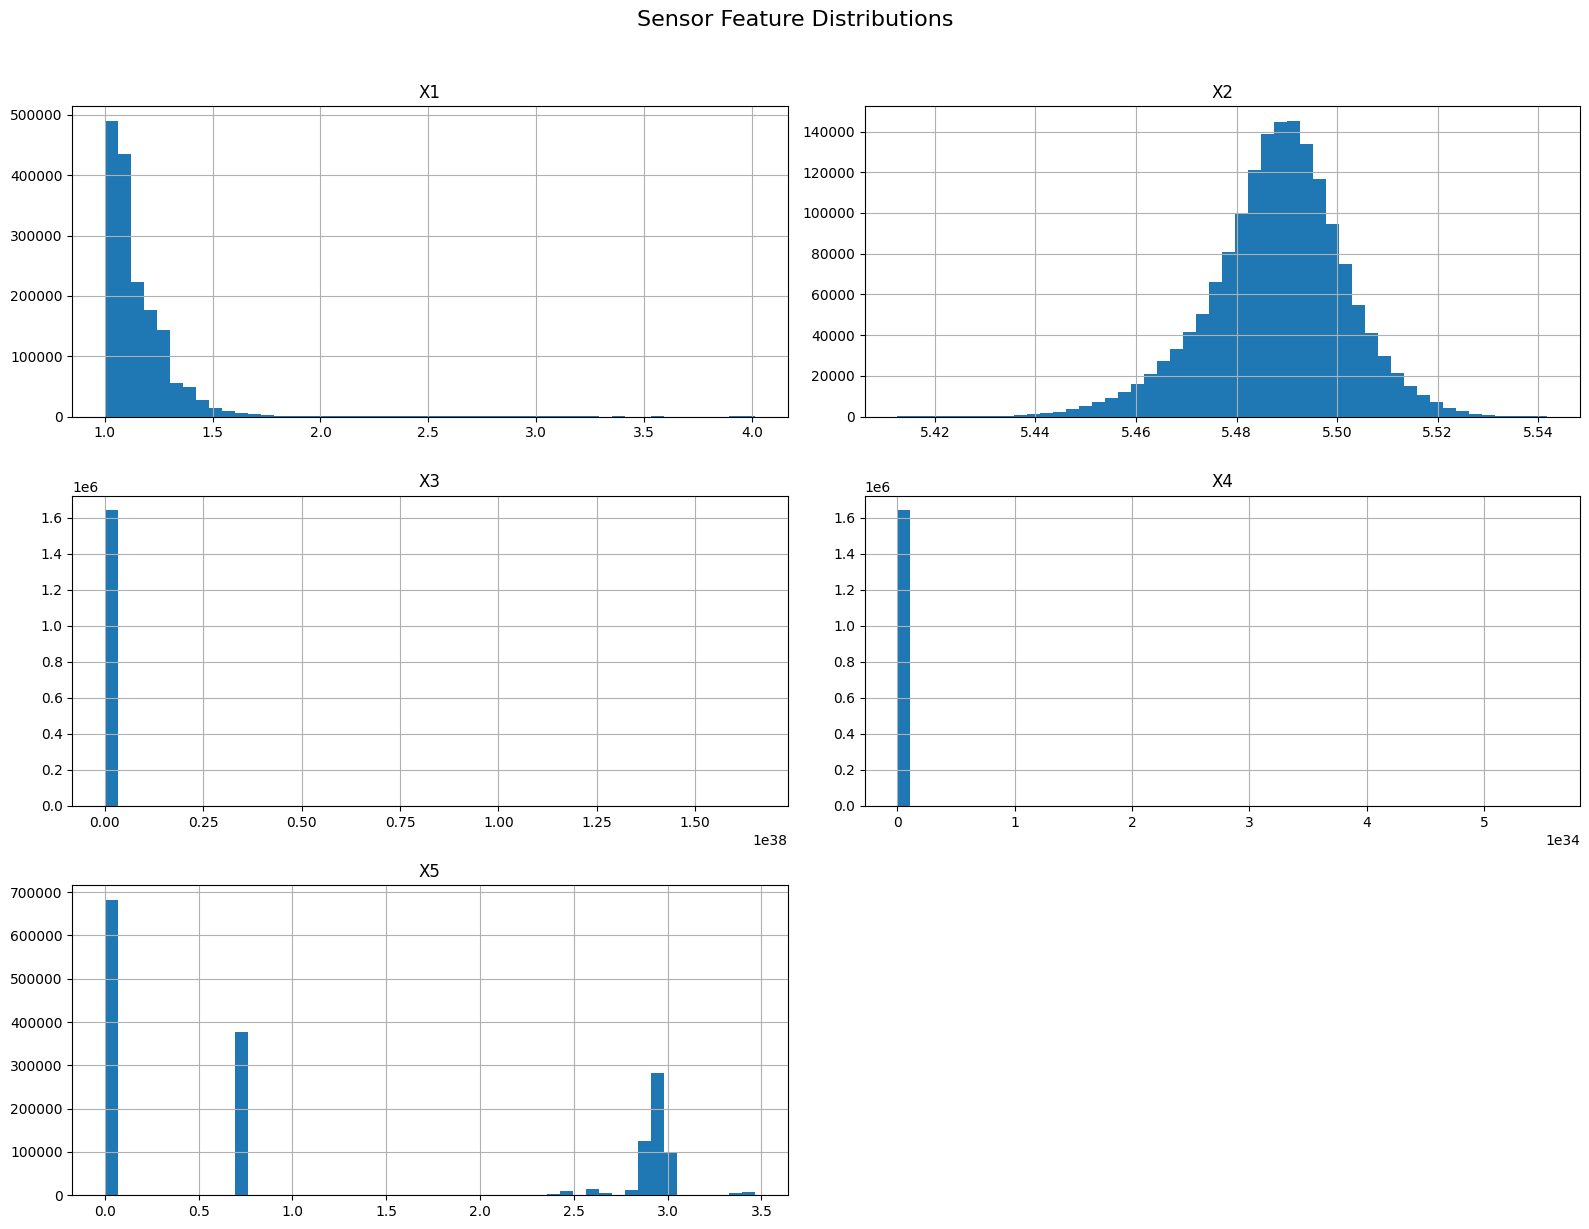

In [26]:
# ============================================================
# CELL 12 — SENSOR DISTRIBUTIONS & OUTLIER OVERVIEW
# ============================================================

sensor_columns = ["X1", "X2", "X3", "X4", "X5"]

print("=" * 70)
print("SENSOR STATISTICS")
print("=" * 70)

sensor_stats = train[sensor_columns].describe().T

# Additional robust statistics
sensor_stats["median"] = train[sensor_columns].median()
sensor_stats["IQR"] = (
    train[sensor_columns].quantile(0.75)
    - train[sensor_columns].quantile(0.25)
)

sensor_stats["skewness"] = train[sensor_columns].skew()

display(sensor_stats)


# ------------------------------------------------------------
# Boxplots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=len(sensor_columns),
    ncols=1,
    figsize=(14, 3 * len(sensor_columns))
)

for ax, col in zip(axes, sensor_columns):
    ax.boxplot(
        train[col].dropna(),
        vert=False
    )
    ax.set_title(f"Boxplot — {col}")
    ax.set_xlabel(col)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Histograms
# ------------------------------------------------------------

train[sensor_columns].hist(
    bins=50,
    figsize=(16, 12)
)

plt.suptitle(
    "Sensor Feature Distributions",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

SENSOR STATISTICS BY TARGET CLASS


X1                                           X2            \
            mean    median       std  min       max      mean    median   
target                                                                    
0       1.138015  1.105171  0.137469  1.0  3.575124  5.488392  5.489103   
1       1.283204  1.241102  0.232147  1.0  4.014850  5.464605  5.464806   

                                                X3                \
             std       min       max          mean        median   
target                                                             
0       0.013247  5.412539  5.541852  9.880565e+25  1.000000e+00   
1       0.013328  5.413831  5.515724  4.800305e+34  4.311232e+15   

                                                   X4                \
                 std  min           max          mean        median   
target                                                                
0       6.872742e+28  1.0  5.052394e+31  2.640088e+28  1.000000e+00   
1       2.535059e+36  1.0  1.651636e+38  2.854890e+31  7.200490e+10   

                                               X5                           \
                 std  min           max      mean    median       std  min   
target                                                                       
0       3.740500e+30  1.0  1.014800e+33  1.175330  0.693147  1.301316  0.0   
1       6.262798e+32  1.0  5.540622e+34  2.563847  2.890372  0.920160  0.0   

                  
             max  
target            
0       3.465736  
1       3.465736


MEDIAN SENSOR VALUES BY CLASS


target,0,1
X1,1.105171,1.241102e+00
X2,5.489103,5.464806e+00
X3,1.000000,4.311232e+15
X4,1.000000,7.200490e+10
X5,0.693147,2.890372e+00


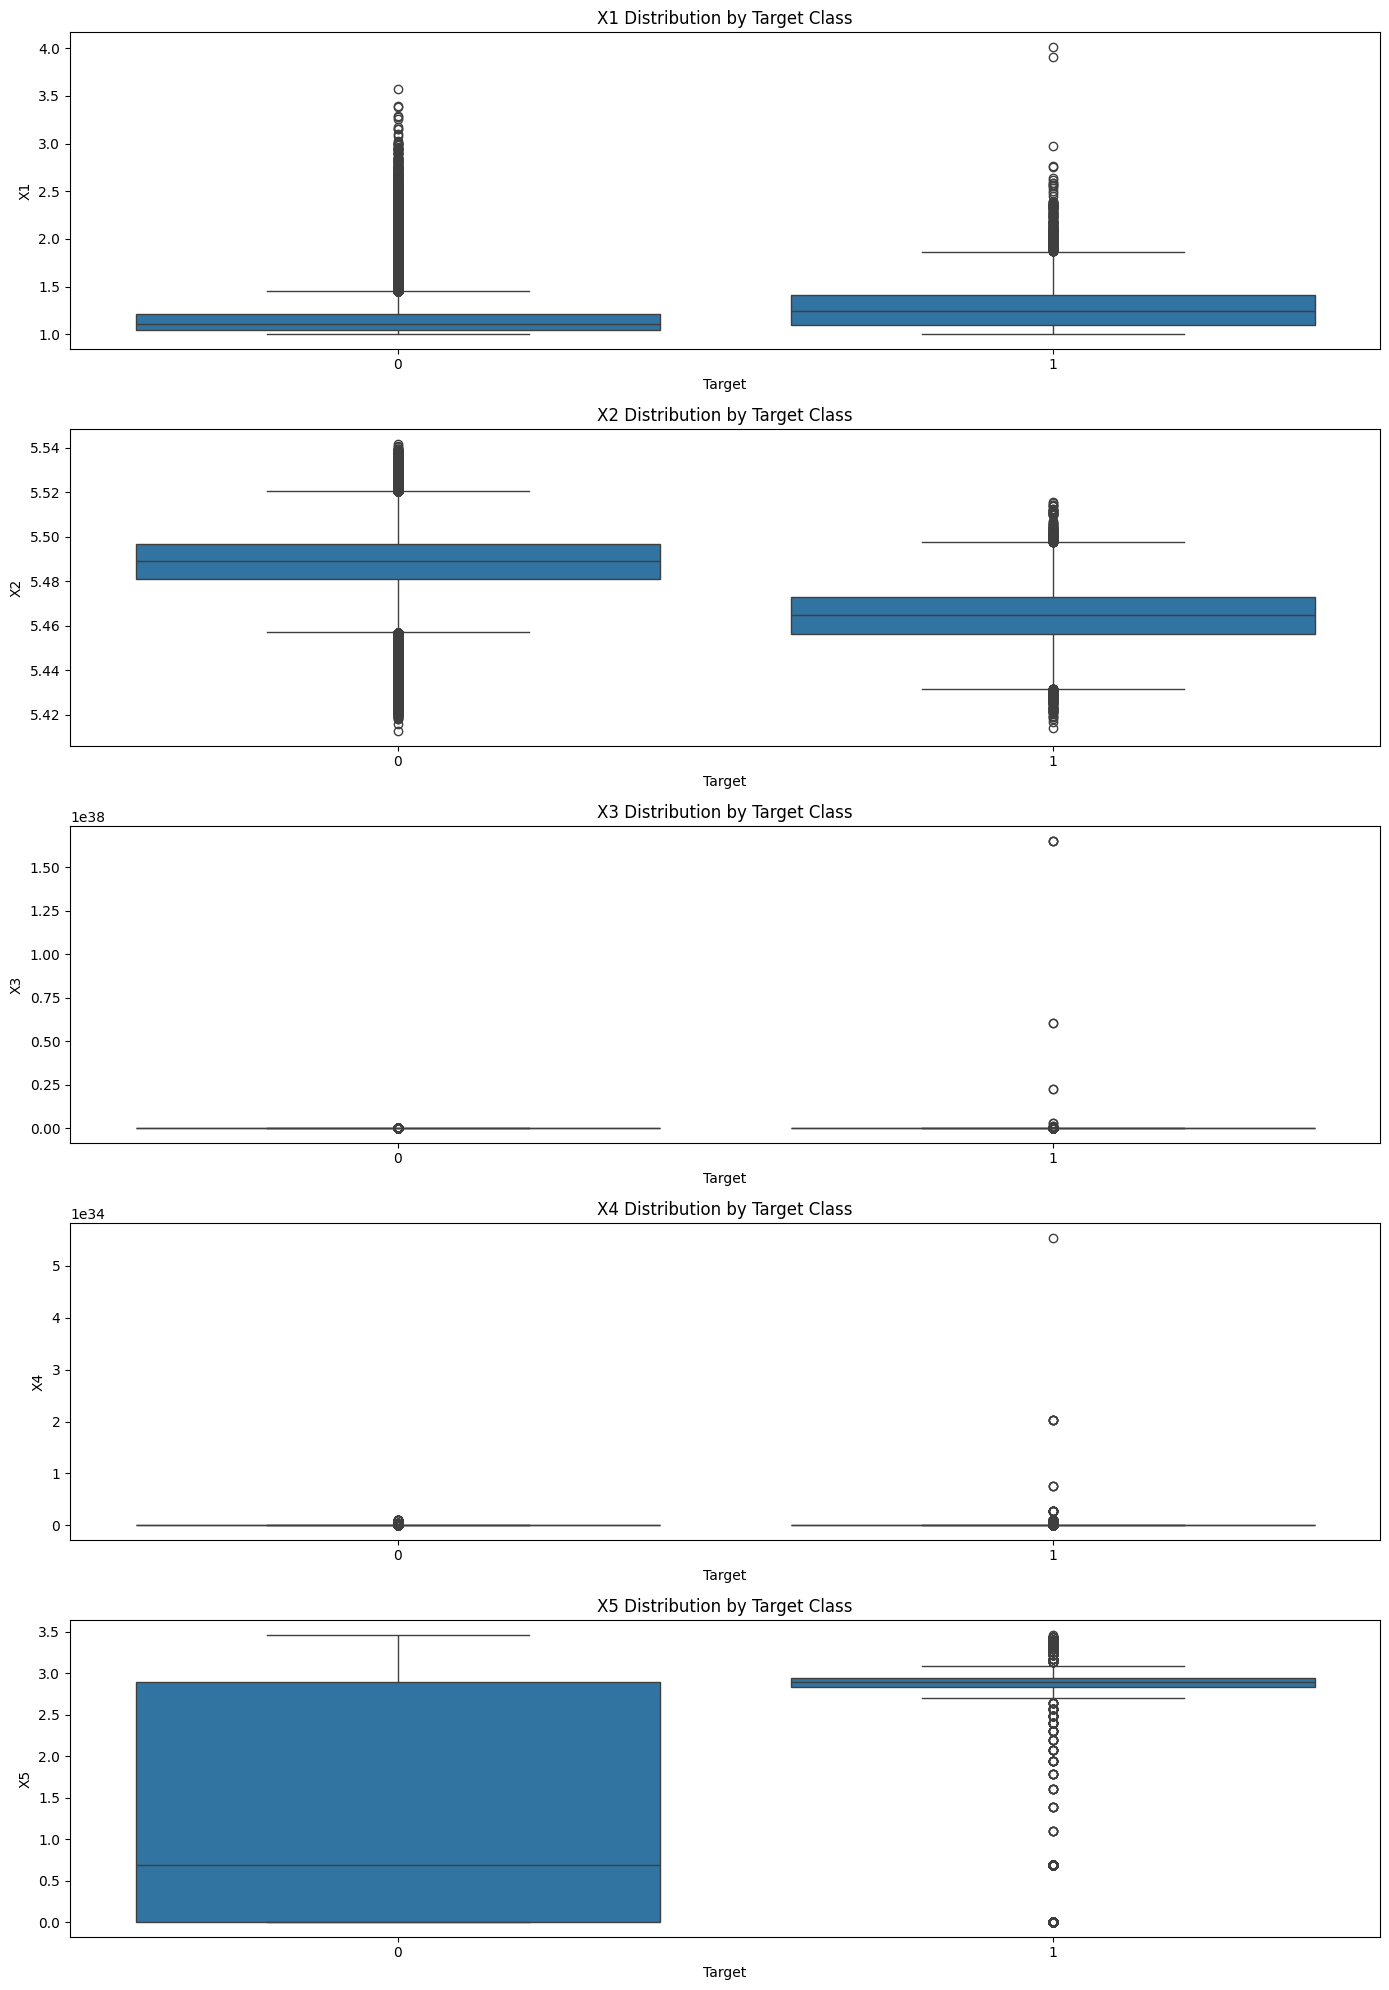

In [27]:
# ============================================================
# CELL 13 — SENSOR DISTRIBUTIONS BY TARGET CLASS
# ============================================================

print("=" * 70)
print("SENSOR STATISTICS BY TARGET CLASS")
print("=" * 70)

class_stats = (
    train
    .groupby("target")[sensor_columns]
    .agg(["mean", "median", "std", "min", "max"])
)

display(class_stats)


# ------------------------------------------------------------
# Median comparison
# ------------------------------------------------------------

median_comparison = (
    train
    .groupby("target")[sensor_columns]
    .median()
    .T
)

print("\n" + "=" * 70)
print("MEDIAN SENSOR VALUES BY CLASS")
print("=" * 70)

display(median_comparison)


# ------------------------------------------------------------
# Boxplots by target class
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=len(sensor_columns),
    ncols=1,
    figsize=(14, 4 * len(sensor_columns))
)

for ax, col in zip(axes, sensor_columns):
    
    sns.boxplot(
        data=train,
        x="target",
        y=col,
        ax=ax
    )
    
    ax.set_title(f"{col} Distribution by Target Class")
    ax.set_xlabel("Target")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

TRAIN / TEST DISTRIBUTION SHIFT


,feature,train_mean,test_mean,mean_difference_std,KS_statistic,KS_p_value
4,X5,1.187219e+00,1.190927e+00,0.002842,0.001507,0.445781
0,X1,1.139258e+00,1.139317e+00,0.000421,0.001505,0.446819
1,X2,5.488189e+00,5.488174e+00,-0.001061,0.001185,0.745955
3,X4,2.706323e+29,4.857705e+29,0.003701,0.000839,0.975045
2,X3,4.110388e+32,1.544527e+32,-0.001094,0.000362,1.000000


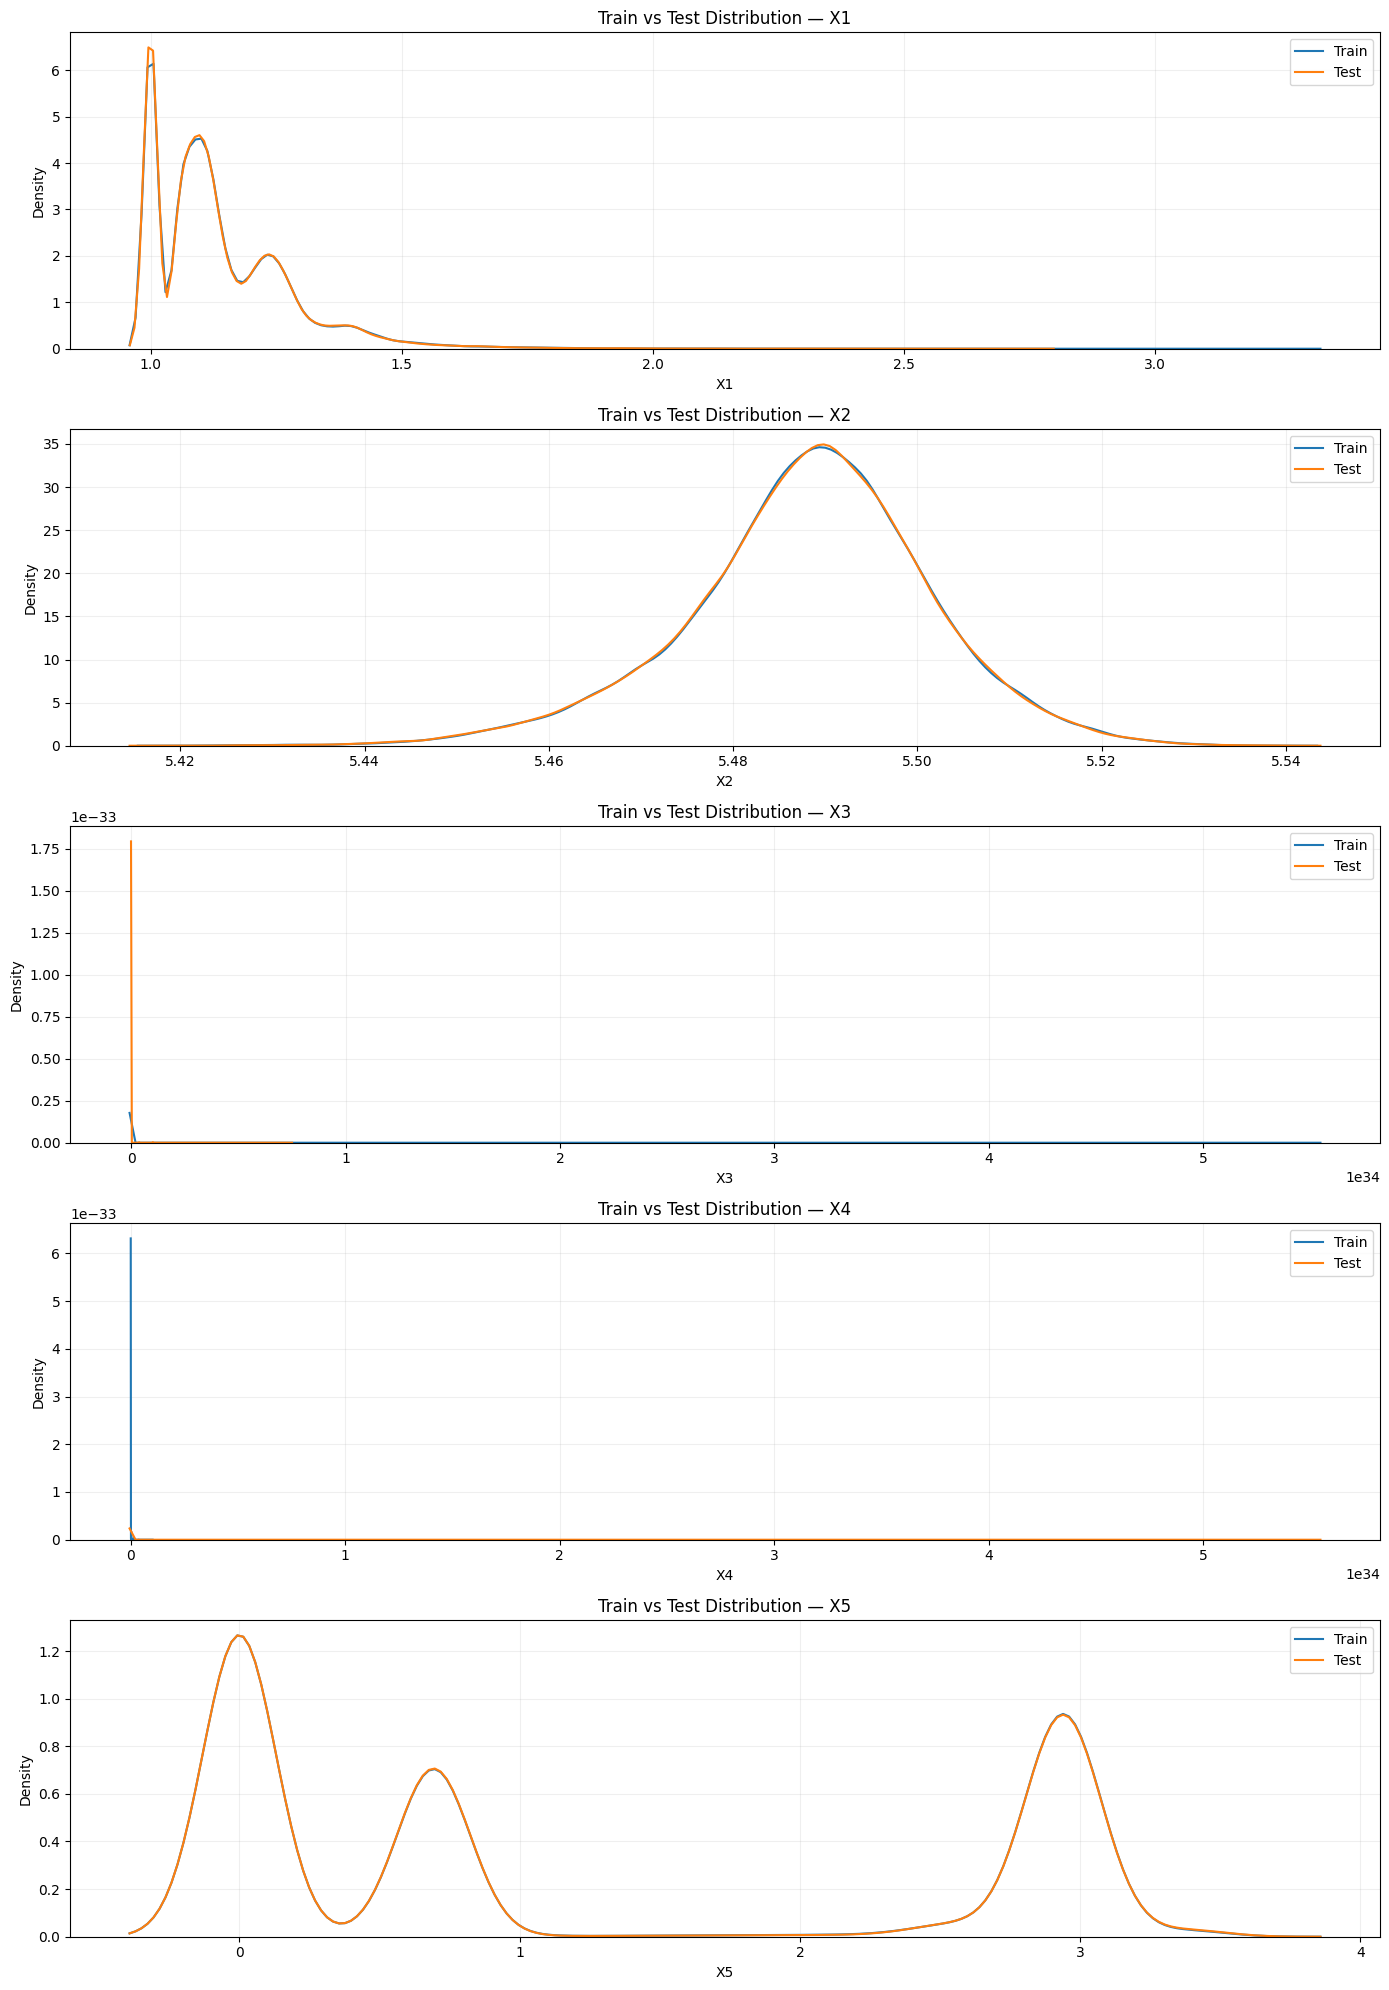

In [28]:
# ============================================================
# CELL 14 — TRAIN / TEST DISTRIBUTION SHIFT
# ============================================================

from scipy.stats import ks_2samp

print("=" * 70)
print("TRAIN / TEST DISTRIBUTION SHIFT")
print("=" * 70)

distribution_results = []

for col in sensor_columns:
    
    train_values = train[col].dropna()
    test_values = test[col].dropna()
    
    ks_stat, p_value = ks_2samp(
        train_values,
        test_values
    )
    
    train_mean = train_values.mean()
    test_mean = test_values.mean()
    
    train_std = train_values.std()
    
    # Standardized mean difference
    if train_std != 0:
        mean_difference_std = (
            test_mean - train_mean
        ) / train_std
    else:
        mean_difference_std = 0
    
    distribution_results.append({
        "feature": col,
        "train_mean": train_mean,
        "test_mean": test_mean,
        "mean_difference_std": mean_difference_std,
        "KS_statistic": ks_stat,
        "KS_p_value": p_value
    })


distribution_shift = pd.DataFrame(
    distribution_results
)

display(
    distribution_shift.sort_values(
        "KS_statistic",
        ascending=False
    )
)


# ------------------------------------------------------------
# Visual comparison using sampled data
# ------------------------------------------------------------

plot_sample_size = min(100000, len(train), len(test))

train_sample = train[sensor_columns].sample(
    n=plot_sample_size,
    random_state=RANDOM_STATE
)

test_sample = test[sensor_columns].sample(
    n=plot_sample_size,
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(
    nrows=len(sensor_columns),
    ncols=1,
    figsize=(14, 4 * len(sensor_columns))
)

for ax, col in zip(axes, sensor_columns):
    
    sns.kdeplot(
        train_sample[col],
        ax=ax,
        label="Train",
        fill=False
    )
    
    sns.kdeplot(
        test_sample[col],
        ax=ax,
        label="Test",
        fill=False
    )
    
    ax.set_title(f"Train vs Test Distribution — {col}")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

TRAIN / TEST ROW DISTRIBUTION BY DATE


,train_count,test_count,total,train_percentage,test_percentage
Date,,,,,
2020-12-16,302,94,396,76.262626,23.737374
2020-12-17,1125,315,1440,78.125000,21.875000
2020-12-18,1162,278,1440,80.694444,19.305556
2020-12-19,1174,266,1440,81.527778,18.472222
2020-12-20,1140,300,1440,79.166667,20.833333
2020-12-21,1156,282,1438,80.389430,19.610570
2020-12-22,1162,278,1440,80.694444,19.305556
2020-12-23,1153,287,1440,80.069444,19.930556
2020-12-24,1159,281,1440,80.486111,19.513889



Overall:
Train rows: 1,639,424
Test rows : 409,856

Train/Test percentage:
Train: 80.000%
Test : 20.000%

Train percentage statistics by date:


count    1432.000000
mean       79.998677
std         1.105725
min        75.609756
25%        79.266608
50%        80.000000
75%        80.694444
max        90.476190
Name: train_percentage, dtype: float64


Dates appearing in both train and test:
1432


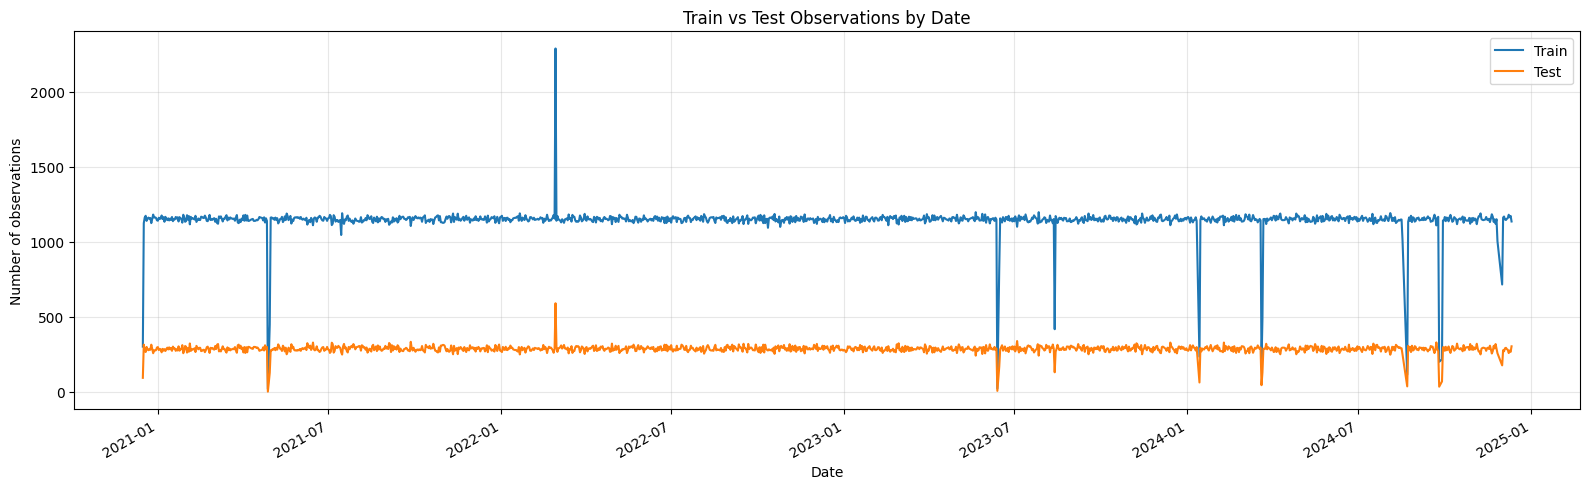

In [29]:
# ============================================================
# CELL 15 — TRAIN / TEST COMPOSITION BY DATE
# ============================================================

print("=" * 70)
print("TRAIN / TEST ROW DISTRIBUTION BY DATE")
print("=" * 70)

train_date_counts = (
    train.groupby("Date")
    .size()
    .rename("train_count")
)

test_date_counts = (
    test.groupby("Date")
    .size()
    .rename("test_count")
)

date_distribution = pd.concat(
    [train_date_counts, test_date_counts],
    axis=1
).fillna(0)

date_distribution["total"] = (
    date_distribution["train_count"]
    + date_distribution["test_count"]
)

date_distribution["train_percentage"] = (
    date_distribution["train_count"]
    / date_distribution["total"]
    * 100
)

date_distribution["test_percentage"] = (
    date_distribution["test_count"]
    / date_distribution["total"]
    * 100
)

display(date_distribution.head(20))

print("\nOverall:")
print(f"Train rows: {len(train):,}")
print(f"Test rows : {len(test):,}")

print("\nTrain/Test percentage:")
print(
    f"Train: {len(train)/(len(train)+len(test))*100:.3f}%"
)
print(
    f"Test : {len(test)/(len(train)+len(test))*100:.3f}%"
)

print("\nTrain percentage statistics by date:")
display(
    date_distribution["train_percentage"].describe()
)

print("\nDates appearing in both train and test:")
print(
    len(
        set(train["Date"].unique())
        &
        set(test["Date"].unique())
    )
)

# ------------------------------------------------------------
# Plot train/test observations by date
# ------------------------------------------------------------

plt.figure(figsize=(16, 5))

date_distribution["train_count"].plot(
    label="Train"
)

date_distribution["test_count"].plot(
    label="Test"
)

plt.title("Train vs Test Observations by Date")
plt.xlabel("Date")
plt.ylabel("Number of observations")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

DAILY ANOMALY STATISTICS


,observations,anomalies,anomaly_rate,anomaly_rate_%
count,1432.000000,1432.000000,1432.000000,1432.000000
mean,1144.849162,9.803073,0.008548,0.854833
std,88.762765,17.496700,0.015200,1.519991
min,19.000000,0.000000,0.000000,0.000000
25%,1141.000000,0.000000,0.000000,0.000000
50%,1152.000000,2.000000,0.001739,0.173913
75%,1162.000000,12.000000,0.010417,1.041667
max,2289.000000,147.000000,0.127273,12.727273



Highest anomaly-rate dates:


,observations,anomalies,anomaly_rate,anomaly_rate_%
Date,,,,
2022-11-23,1155,147,0.127273,12.727273
2021-01-21,1155,128,0.110823,11.082251
2021-01-13,1143,121,0.105862,10.586177
2023-01-18,1127,115,0.102041,10.204082
2023-12-24,1139,109,0.095698,9.569798
2021-12-28,1167,105,0.089974,8.997429
2023-01-16,1146,97,0.084642,8.464223
2021-03-02,1158,97,0.083765,8.376511
2020-12-23,1153,96,0.083261,8.326106



Lowest anomaly-rate dates:


,observations,anomalies,anomaly_rate,anomaly_rate_%
Date,,,,
2022-02-27,1155,0,0.0,0.0
2023-06-19,1165,0,0.0,0.0
2023-06-18,1129,0,0.0,0.0
2023-06-15,818,0,0.0,0.0
2023-06-13,23,0,0.0,0.0
2023-06-11,1161,0,0.0,0.0
2023-06-09,1157,0,0.0,0.0
2023-06-08,1157,0,0.0,0.0
2022-03-03,1149,0,0.0,0.0


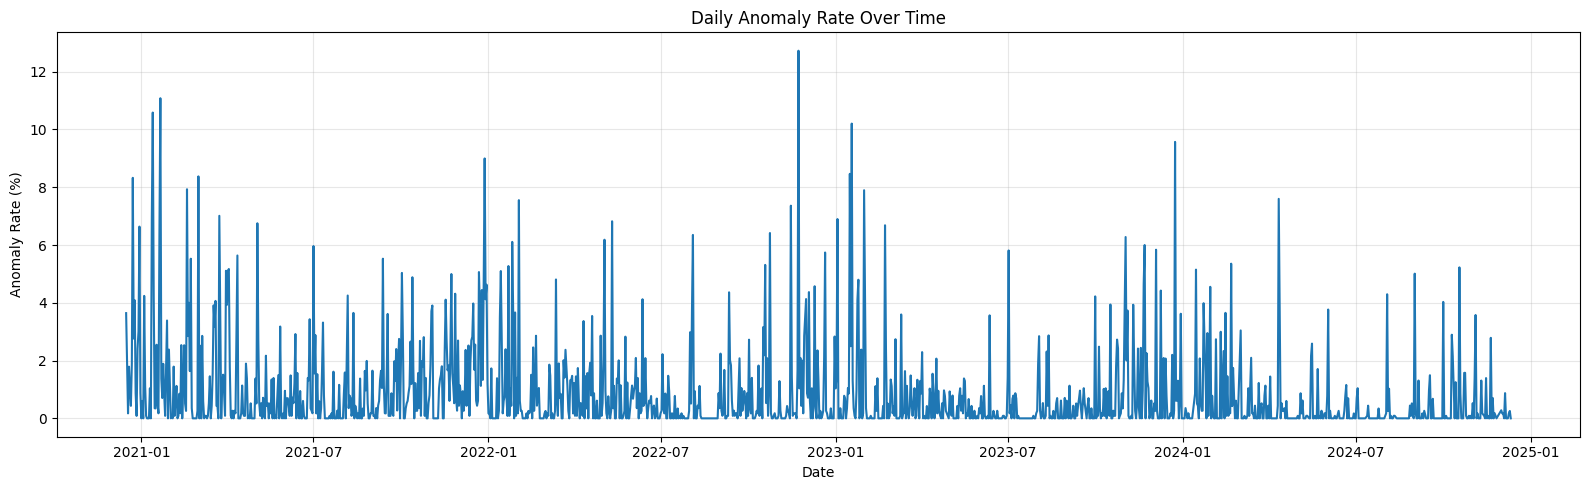

In [30]:
# ============================================================
# CELL 16 — DAILY / MONTHLY ANOMALY BEHAVIOR
# ============================================================

temp = train[["Date", "target"]].copy()

temp["is_anomaly"] = (
    temp["target"] == "1"
).astype(np.int8)

# Daily statistics
daily_stats = (
    temp.groupby("Date")
    .agg(
        observations=("is_anomaly", "size"),
        anomalies=("is_anomaly", "sum"),
        anomaly_rate=("is_anomaly", "mean")
    )
)

daily_stats["anomaly_rate_%"] = (
    daily_stats["anomaly_rate"] * 100
)

print("=" * 70)
print("DAILY ANOMALY STATISTICS")
print("=" * 70)

display(daily_stats.describe())

print("\nHighest anomaly-rate dates:")
display(
    daily_stats
    .sort_values("anomaly_rate", ascending=False)
    .head(15)
)

print("\nLowest anomaly-rate dates:")
display(
    daily_stats
    .sort_values("anomaly_rate")
    .head(15)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(16, 5))

plt.plot(
    daily_stats.index,
    daily_stats["anomaly_rate_%"]
)

plt.title("Daily Anomaly Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Anomaly Rate (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# CELL 17 — SENSOR CARDINALITY & VALUE FREQUENCIES
# ============================================================

sensor_columns = ["X1", "X2", "X3", "X4", "X5"]

print("=" * 70)
print("SENSOR CARDINALITY")
print("=" * 70)

cardinality = pd.DataFrame({
    "dtype": train[sensor_columns].dtypes.astype(str),
    "unique_values": train[sensor_columns].nunique(),
    "unique_percentage": (
        train[sensor_columns].nunique()
        / len(train) * 100
    )
})

display(cardinality)


# ------------------------------------------------------------
# Most frequent values
# ------------------------------------------------------------

for col in sensor_columns:
    
    print("\n" + "=" * 70)
    print(f"TOP VALUES — {col}")
    print("=" * 70)
    
    value_counts = (
        train[col]
        .value_counts(dropna=False)
        .head(15)
    )
    
    display(
        value_counts.to_frame("count")
    )


# ------------------------------------------------------------
# Number of exact repeated values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REPEATED VALUE ANALYSIS")
print("=" * 70)

for col in sensor_columns:
    
    unique_count = train[col].nunique()
    
    print(
        f"{col}: {unique_count:,} unique values "
        f"out of {len(train):,} rows"
    )

SENSOR CARDINALITY


,dtype,unique_values,unique_percentage
X1,float64,526,0.032084
X2,float64,2812,0.171524
X3,float64,88,0.005368
X4,float64,81,0.004941
X5,float64,32,0.001952



TOP VALUES — X1


,count
X1,
1.000000,385516
1.102963,17543
1.096365,17529
1.105171,17459
1.100759,17417
1.107383,17394
1.098560,17154
1.109600,17083
1.094174,16993



TOP VALUES — X2


,count
X2,
5.489681,2827
5.489020,2636
5.490259,2636
5.489433,2616
5.491002,2612
5.490218,2604
5.491125,2598
5.489062,2596
5.490631,2591


... (3 outputs left out)

,count
X4,
1.000000e+00,1149739
2.718282e+00,302165
7.389056e+00,125595
2.008554e+01,5777
1.171914e+16,5396
5.459815e+01,4563
4.311232e+15,4497
3.185593e+16,4095
1.484132e+02,3517



TOP VALUES — X5


,count
X5,
0.000000,681968
0.693147,377675
2.944439,282461
2.890372,125063
2.995732,97084
2.564949,13390
2.833213,12661
2.484907,8972
3.401197,5518



REPEATED VALUE ANALYSIS
X1: 526 unique values out of 1,639,424 rows
X2: 2,812 unique values out of 1,639,424 rows
X3: 88 unique values out of 1,639,424 rows
X4: 81 unique values out of 1,639,424 rows
X5: 32 unique values out of 1,639,424 rows


In [32]:
# ============================================================
# CELL 18 — ROBUST OUTLIER ANALYSIS
# ============================================================

outlier_summary = []

for col in sensor_columns:
    
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outlier_mask = (
        (train[col] < lower_bound)
        |
        (train[col] > upper_bound)
    )
    
    outlier_count = outlier_mask.sum()
    
    outlier_summary.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": (
            outlier_count / len(train) * 100
        ),
        "anomaly_rate_among_outliers": (
            train.loc[outlier_mask, "target"]
            .eq("1")
            .mean() * 100
        )
    })

outlier_summary = pd.DataFrame(
    outlier_summary
)

print("=" * 70)
print("IQR OUTLIER ANALYSIS")
print("=" * 70)

display(outlier_summary)

IQR OUTLIER ANALYSIS


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage,anomaly_rate_among_outliers
0,X1,1.049171,1.214096,0.164926,0.801782,1.461485,47192,2.878572,5.806069
1,X2,5.480597,5.496717,0.016120,5.456417,5.520897,41560,2.535037,8.421559
2,X3,1.000000,1.000000,0.000000,1.000000,1.000000,135274,8.251313,6.846105
3,X4,1.000000,2.718282,1.718282,-1.577423,5.295705,187520,11.438164,4.369134
4,X5,0.000000,2.890372,2.890372,-4.335558,7.225929,0,0.000000,NaN


SPEARMAN CORRELATION MATRIX


,X1,X2,X3,X4,X5,target_numeric
X1,1.000000,-0.094564,0.117110,0.432524,0.071307,0.065163
X2,-0.094564,1.000000,-0.182600,-0.093104,-0.183748,-0.127241
X3,0.117110,-0.182600,1.000000,0.056598,0.148356,0.204627
X4,0.432524,-0.093104,0.056598,1.000000,0.044177,0.103737
X5,0.071307,-0.183748,0.148356,0.044177,1.000000,0.066824
target_numeric,0.065163,-0.127241,0.204627,0.103737,0.066824,1.000000


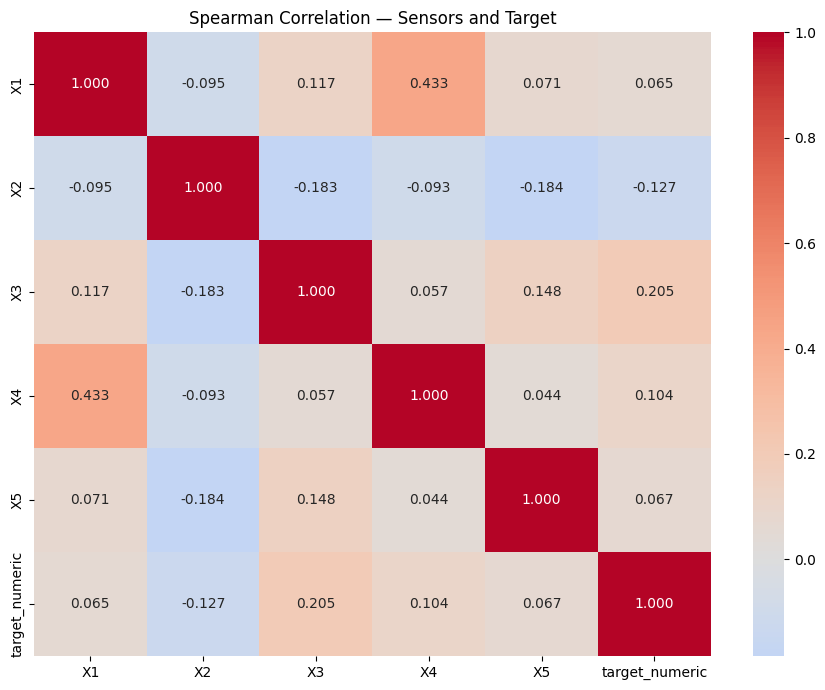


SENSOR CORRELATION WITH TARGET


,Spearman correlation
X3,0.204627
X2,-0.127241
X4,0.103737
X5,0.066824
X1,0.065163


In [33]:
# ============================================================
# CELL 19 — CORRELATION ANALYSIS
# ============================================================

correlation_data = train[sensor_columns].copy()

correlation_data["target_numeric"] = (
    train["target"]
    .astype(str)
    .eq("1")
    .astype(np.int8)
)

correlation_matrix = correlation_data.corr(
    method="spearman"
)

print("=" * 70)
print("SPEARMAN CORRELATION MATRIX")
print("=" * 70)

display(
    correlation_matrix
)

# ------------------------------------------------------------
# Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Spearman Correlation — Sensors and Target"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Correlation with target
# ------------------------------------------------------------

target_correlations = (
    correlation_matrix["target_numeric"]
    .drop("target_numeric")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("\n" + "=" * 70)
print("SENSOR CORRELATION WITH TARGET")
print("=" * 70)

display(
    target_correlations.to_frame(
        "Spearman correlation"
    )
)

In [34]:
# ============================================================
# CELL 20 — CLASS SEPARATION ANALYSIS
# ============================================================

from scipy.stats import mannwhitneyu

class_separation = []

normal_mask = train["target"].eq("0")
anomaly_mask = train["target"].eq("1")

for col in sensor_columns:
    
    normal_values = train.loc[
        normal_mask, col
    ]
    
    anomaly_values = train.loc[
        anomaly_mask, col
    ]
    
    statistic, p_value = mannwhitneyu(
        normal_values,
        anomaly_values,
        alternative="two-sided"
    )
    
    normal_median = normal_values.median()
    anomaly_median = anomaly_values.median()
    
    class_separation.append({
        "feature": col,
        "normal_median": normal_median,
        "anomaly_median": anomaly_median,
        "median_difference": (
            anomaly_median - normal_median
        ),
        "Mann_Whitney_U": statistic,
        "p_value": p_value
    })

class_separation = pd.DataFrame(
    class_separation
)

print("=" * 70)
print("CLASS SEPARATION")
print("=" * 70)

display(
    class_separation.sort_values(
        "p_value"
    )
)

CLASS SEPARATION


,feature,normal_median,anomaly_median,median_difference,Mann_Whitney_U,p_value
0,X1,1.105171,1.241102e+00,1.359315e-01,6.780710e+09,0.0
1,X2,5.489103,5.464806e+00,-2.429710e-02,2.050478e+10,0.0
2,X3,1.000000,4.311232e+15,4.311232e+15,4.429737e+09,0.0
3,X4,1.000000,7.200490e+10,7.200490e+10,5.437182e+09,0.0
4,X5,0.693147,2.890372e+00,2.197225e+00,6.851437e+09,0.0


In [35]:
# ============================================================
# CELL 21 — CONFLICTING DUPLICATE INVESTIGATION
# ============================================================

print("=" * 70)
print("CONFLICTING DUPLICATE INVESTIGATION")
print("=" * 70)

# Find feature combinations with conflicting targets
duplicate_feature_rows = train[
    train.duplicated(
        subset=sensor_columns + ["Date"],
        keep=False
    )
].copy()

conflict_counts = (
    duplicate_feature_rows
    .groupby(sensor_columns + ["Date"])["target"]
    .nunique()
)

conflict_groups = conflict_counts[
    conflict_counts > 1
]

print(
    "Conflicting feature/date groups:",
    len(conflict_groups)
)

# ------------------------------------------------------------
# Display all conflicting groups
# ------------------------------------------------------------

if len(conflict_groups) > 0:
    
    conflict_index = conflict_groups.index
    
    conflict_examples = (
        duplicate_feature_rows
        .set_index(sensor_columns + ["Date"])
        .loc[conflict_index]
        .reset_index()
        .sort_values(
            sensor_columns + ["Date"]
        )
    )
    
    print("\nConflicting observations:")
    display(
        conflict_examples
    )

    print("\nTarget distribution within conflicts:")
    display(
        conflict_examples["target"]
        .value_counts()
        .to_frame("count")
    )

else:
    
    print("No conflicting duplicates found.")

CONFLICTING DUPLICATE INVESTIGATION
Conflicting feature/date groups: 14

Conflicting observations:


,X1,X2,X3,X4,X5,Date,target
0,1.000000,5.471892,1.000000e+00,2.718282,2.890372,2020-12-26,0
1,1.000000,5.471892,1.000000e+00,2.718282,2.890372,2020-12-26,1
2,1.000000,5.472271,1.171914e+16,1.000000,2.944439,2023-11-25,0
3,1.000000,5.472271,1.171914e+16,1.000000,2.944439,2023-11-25,1
4,1.000000,5.474663,1.000000e+00,1.000000,2.890372,2021-09-01,1
5,1.000000,5.474663,1.000000e+00,1.000000,2.890372,2021-09-01,0
6,1.000000,5.474830,1.000000e+00,1.000000,0.000000,2021-11-02,1
7,1.000000,5.474830,1.000000e+00,1.000000,0.000000,2021-11-02,0
8,1.000000,5.477593,1.000000e+00,1.000000,0.000000,2023-07-04,1
9,1.000000,5.477593,1.000000e+00,1.000000,0.000000,2023-07-04,0



Target distribution within conflicts:


,count
target,
0,14
1,14


In [36]:
# ============================================================
# CELL 22 — TRAIN / TEST FEATURE OVERLAP
# ============================================================

feature_columns = [
    "Date", "X1", "X2", "X3", "X4", "X5"
]

print("=" * 70)
print("TRAIN / TEST FEATURE OVERLAP")
print("=" * 70)

# Create compact keys from all predictive columns
train_keys = pd.MultiIndex.from_frame(
    train[feature_columns]
)

test_keys = pd.MultiIndex.from_frame(
    test[feature_columns]
)

overlap_mask = test_keys.isin(
    train_keys
)

overlap_count = overlap_mask.sum()

print(
    f"Test rows whose complete feature/date combination "
    f"exists in train: {overlap_count:,}"
)

print(
    f"Percentage of test rows with train overlap: "
    f"{overlap_count / len(test) * 100:.4f}%"
)


# ------------------------------------------------------------
# Sensor-only overlap, excluding Date
# ------------------------------------------------------------

sensor_keys_train = pd.MultiIndex.from_frame(
    train[sensor_columns]
)

sensor_keys_test = pd.MultiIndex.from_frame(
    test[sensor_columns]
)

sensor_overlap_mask = sensor_keys_test.isin(
    sensor_keys_train
)

sensor_overlap_count = sensor_overlap_mask.sum()

print(
    f"\nTest rows whose sensor combination "
    f"exists in train: {sensor_overlap_count:,}"
)

print(
    f"Percentage of test rows with sensor overlap: "
    f"{sensor_overlap_count / len(test) * 100:.4f}%"
)

TRAIN / TEST FEATURE OVERLAP
Test rows whose complete feature/date combination exists in train: 27,183
Percentage of test rows with train overlap: 6.6323%

Test rows whose sensor combination exists in train: 253,018
Percentage of test rows with sensor overlap: 61.7334%


In [37]:
# ============================================================
# CELL 23 — SENSOR VALUE ANOMALY RATES
# ============================================================

print("=" * 70)
print("SENSOR VALUE → ANOMALY RATE")
print("=" * 70)

for col in sensor_columns:
    
    value_analysis = (
        train
        .groupby(col)["target"]
        .agg(
            observations="count",
            anomalies=lambda x: (x == "1").sum()
        )
    )
    
    value_analysis["anomaly_rate_%"] = (
        value_analysis["anomalies"]
        / value_analysis["observations"]
        * 100
    )
    
    value_analysis["anomaly_lift"] = (
        value_analysis["anomaly_rate_%"]
        / (
            train["target"].eq("1").mean() * 100
        )
    )
    
    print("\n" + "=" * 70)
    print(f"{col} — HIGHEST ANOMALY RATE VALUES")
    print("=" * 70)
    
    display(
        value_analysis
        .sort_values(
            "anomaly_rate_%",
            ascending=False
        )
        .head(15)
    )
    
    print(f"\n{col} — MOST FREQUENT VALUES")
    
    display(
        value_analysis
        .sort_values(
            "observations",
            ascending=False
        )
        .head(10)
    )

SENSOR VALUE → ANOMALY RATE

X1 — HIGHEST ANOMALY RATE VALUES


,observations,anomalies,anomaly_rate_%,anomaly_lift
X1,,,,
4.014850,1,1,100.000000,116.784727
3.911809,1,1,100.000000,116.784727
2.762124,1,1,100.000000,116.784727
2.585710,1,1,100.000000,116.784727
2.559981,1,1,100.000000,116.784727
2.974274,1,1,100.000000,116.784727
2.590886,2,1,50.000000,58.392364
2.565107,3,1,33.333333,38.928242
2.570242,3,1,33.333333,38.928242



X1 — MOST FREQUENT VALUES


,observations,anomalies,anomaly_rate_%,anomaly_lift
X1,,,,
1.000000,385516,1529,0.396611,0.463181
1.102963,17543,59,0.336316,0.392766
1.096365,17529,71,0.405043,0.473028
1.105171,17459,67,0.383756,0.448169
1.100759,17417,77,0.442097,0.516302
1.107383,17394,69,0.396689,0.463272
1.098560,17154,63,0.367261,0.428905
1.109600,17083,44,0.257566,0.300798
1.094174,16993,85,0.500206,0.584164



X2 — HIGHEST ANOMALY RATE VALUES


,observations,anomalies,anomaly_rate_%,anomaly_lift
X2,,,,
5.413831,1,1,100.0,116.784727
5.416944,1,1,100.0,116.784727
5.418231,1,1,100.0,116.784727
5.421287,2,2,100.0,116.784727
5.421641,2,2,100.0,116.784727
5.421773,1,1,100.0,116.784727
5.422436,1,1,100.0,116.784727
5.423451,1,1,100.0,116.784727
5.424818,1,1,100.0,116.784727


... (10 outputs left out)


X5 — HIGHEST ANOMALY RATE VALUES


,observations,anomalies,anomaly_rate_%,anomaly_lift
X5,,,,
2.833213,12661,1819,14.366954,16.778408
2.772589,518,43,8.301158,9.694485
3.332205,1061,56,5.278040,6.163944
2.890372,125063,6387,5.107026,5.964226
3.367296,3487,122,3.498709,4.085958
3.295837,614,18,2.931596,3.423656
2.708050,425,10,2.352941,2.747876
3.178054,555,11,1.981982,2.314652
3.218876,541,10,1.848429,2.158683



X5 — MOST FREQUENT VALUES


,observations,anomalies,anomaly_rate_%,anomaly_lift
X5,,,,
0.000000,681968,1388,0.203529,0.237690
0.693147,377675,337,0.089230,0.104207
2.944439,282461,3302,1.169011,1.365226
2.890372,125063,6387,5.107026,5.964226
2.995732,97084,285,0.293560,0.342833
2.564949,13390,25,0.186706,0.218045
2.833213,12661,1819,14.366954,16.778408
2.484907,8972,22,0.245207,0.286365
3.401197,5518,68,1.232331,1.439174


In [38]:
# ============================================================
# CELL 24 — SENSOR COMBINATION ANALYSIS
# ============================================================

print("=" * 70)
print("SENSOR COMBINATION ANALYSIS")
print("=" * 70)

# Create a few logically useful combinations
pattern_data = train[
    sensor_columns + ["target"]
].copy()

pattern_data["X3_is_one"] = (
    pattern_data["X3"] == 1.0
)

pattern_data["X4_is_one"] = (
    pattern_data["X4"] == 1.0
)

pattern_data["X5_is_zero"] = (
    pattern_data["X5"] == 0.0
)

pattern_data["X5_is_high"] = (
    pattern_data["X5"] > pattern_data["X5"].median()
)

pattern_data["X3_non_one"] = (
    pattern_data["X3"] != 1.0
)

pattern_data["X4_non_one"] = (
    pattern_data["X4"] != 1.0
)


patterns = [
    "X3_is_one",
    "X3_non_one",
    "X4_is_one",
    "X4_non_one",
    "X5_is_zero",
    "X5_is_high"
]

pattern_results = []

overall_rate = (
    train["target"].eq("1").mean() * 100
)

for pattern in patterns:
    
    mask = pattern_data[pattern]
    
    count = mask.sum()
    
    if count > 0:
        anomaly_count = (
            pattern_data.loc[mask, "target"]
            .eq("1")
            .sum()
        )
        
        rate = anomaly_count / count * 100
        
        pattern_results.append({
            "pattern": pattern,
            "observations": count,
            "anomalies": anomaly_count,
            "anomaly_rate_%": rate,
            "lift": rate / overall_rate
        })


pattern_results = pd.DataFrame(
    pattern_results
)

display(
    pattern_results.sort_values(
        "lift",
        ascending=False
    )
)


# ------------------------------------------------------------
# Two-way combinations
# ------------------------------------------------------------

pattern_data["X3_non_one_AND_X4_non_one"] = (
    pattern_data["X3_non_one"]
    & pattern_data["X4_non_one"]
)

pattern_data["X3_non_one_AND_X5_zero"] = (
    pattern_data["X3_non_one"]
    & pattern_data["X5_is_zero"]
)

pattern_data["X4_non_one_AND_X5_zero"] = (
    pattern_data["X4_non_one"]
    & pattern_data["X5_is_zero"]
)

combo_columns = [
    "X3_non_one_AND_X4_non_one",
    "X3_non_one_AND_X5_zero",
    "X4_non_one_AND_X5_zero"
]

combo_results = []

for pattern in combo_columns:
    
    mask = pattern_data[pattern]
    count = mask.sum()
    
    if count > 0:
        
        anomalies = (
            pattern_data.loc[
                mask, "target"
            ].eq("1").sum()
        )
        
        rate = anomalies / count * 100
        
        combo_results.append({
            "pattern": pattern,
            "observations": count,
            "anomalies": anomalies,
            "anomaly_rate_%": rate,
            "lift": rate / overall_rate
        })

print("\n" + "=" * 70)
print("COMBINATION RESULTS")
print("=" * 70)

display(
    pd.DataFrame(combo_results)
    .sort_values("lift", ascending=False)
)

SENSOR COMBINATION ANALYSIS


,pattern,observations,anomalies,anomaly_rate_%,lift
1,X3_non_one,135274,9261,6.846105,7.995205
5,X5_is_high,579781,12313,2.123733,2.480196
3,X4_non_one,489685,9382,1.915926,2.237508
2,X4_is_one,1149739,4656,0.404961,0.472933
0,X3_is_one,1504150,4777,0.317588,0.370894
4,X5_is_zero,681968,1388,0.203529,0.237690



COMBINATION RESULTS


,pattern,observations,anomalies,anomaly_rate_%,lift
0,X3_non_one_AND_X4_non_one,50045,5543,11.076032,12.935113
1,X3_non_one_AND_X5_zero,31068,894,2.877559,3.360549
2,X4_non_one_AND_X5_zero,185595,933,0.502708,0.587086


In [39]:
# ============================================================
# CELL 25 — TEMPORAL FEATURE SIGNAL
# ============================================================

date_features = train[["Date", "target"]].copy()

date_features["year"] = date_features["Date"].dt.year
date_features["month"] = date_features["Date"].dt.month
date_features["day"] = date_features["Date"].dt.day
date_features["day_of_week"] = date_features["Date"].dt.dayofweek
date_features["day_of_year"] = date_features["Date"].dt.dayofyear
date_features["quarter"] = date_features["Date"].dt.quarter

# ------------------------------------------------------------
# Function for category anomaly rates
# ------------------------------------------------------------

def category_anomaly_summary(df, column):
    
    result = (
        df.groupby(column)["target"]
        .agg(
            observations="count",
            anomalies=lambda x: (x == "1").sum()
        )
    )
    
    result["anomaly_rate_%"] = (
        result["anomalies"]
        / result["observations"]
        * 100
    )
    
    return result


for col in [
    "year",
    "month",
    "day_of_week",
    "quarter"
]:
    
    print("\n" + "=" * 70)
    print(f"ANOMALY RATE BY {col.upper()}")
    print("=" * 70)
    
    display(
        category_anomaly_summary(
            date_features,
            col
        )
    )


ANOMALY RATE BY YEAR


,observations,anomalies,anomaly_rate_%
year,,,
2020,17622,429,2.434457
2021,417268,5246,1.257226
2022,421434,3614,0.857548
2023,417068,3058,0.733214
2024,366032,1691,0.461981



ANOMALY RATE BY MONTH


,observations,anomalies,anomaly_rate_%
month,,,
1,139652,2179,1.560307
2,129225,1112,0.860515
3,140084,1252,0.893749
4,134292,950,0.707414
5,141832,875,0.616927
6,134452,645,0.479725
7,141437,512,0.361999
8,134974,691,0.511950
9,132620,838,0.631881



ANOMALY RATE BY DAY_OF_WEEK


,observations,anomalies,anomaly_rate_%
day_of_week,,,
0,237167,1769,0.745888
1,234881,2182,0.928981
2,232179,3012,1.297275
3,231870,2189,0.944063
4,232884,1441,0.618763
5,235225,1765,0.750345
6,235218,1680,0.714231



ANOMALY RATE BY QUARTER


,observations,anomalies,anomaly_rate_%
quarter,,,
1,408961,4543,1.110864
2,410576,2470,0.601594
3,409031,2041,0.498984
4,410856,4984,1.213077


In [40]:
# ============================================================
# CELL 26 — SKEWNESS & ROBUST TRANSFORMATION ANALYSIS
# ============================================================

from scipy.stats import skew

transformation_analysis = []

for col in sensor_columns:
    
    values = train[col].astype(float)
    
    # Raw skewness
    raw_skew = skew(
        values,
        bias=False
    )
    
    # Signed log transformation
    signed_log = (
        np.sign(values)
        * np.log1p(np.abs(values))
    )
    
    transformed_skew = skew(
        signed_log,
        bias=False
    )
    
    transformation_analysis.append({
        "feature": col,
        "raw_skewness": raw_skew,
        "signed_log_skewness": transformed_skew,
        "raw_abs_skewness": abs(raw_skew),
        "transformed_abs_skewness": abs(transformed_skew)
    })

transformation_analysis = pd.DataFrame(
    transformation_analysis
)

print("=" * 70)
print("SKEWNESS ANALYSIS")
print("=" * 70)

display(
    transformation_analysis
)

SKEWNESS ANALYSIS


,feature,raw_skewness,signed_log_skewness,raw_abs_skewness,transformed_abs_skewness
0,X1,1.936289,1.504171,1.936289,1.504171
1,X2,-0.380227,-0.388452,0.380227,0.388452
2,X3,660.657945,5.971194,660.657945,5.971194
3,X4,664.876766,7.182278,664.876766,7.182278
4,X5,0.512101,0.308192,0.512101,0.308192


In [41]:
# ============================================================
# CELL 27 — ANOMALY SIGNAL FEATURES
# ============================================================

signal_features = train[
    sensor_columns + ["target"]
].copy()

# ------------------------------------------------------------
# Basic statistical features
# ------------------------------------------------------------

signal_features["sensor_mean"] = (
    signal_features[sensor_columns].mean(axis=1)
)

signal_features["sensor_std"] = (
    signal_features[sensor_columns].std(axis=1)
)

signal_features["sensor_min"] = (
    signal_features[sensor_columns].min(axis=1)
)

signal_features["sensor_max"] = (
    signal_features[sensor_columns].max(axis=1)
)

signal_features["sensor_range"] = (
    signal_features["sensor_max"]
    - signal_features["sensor_min"]
)

signal_features["sensor_median"] = (
    signal_features[sensor_columns].median(axis=1)
)

# ------------------------------------------------------------
# Number of unusual/non-baseline states
# ------------------------------------------------------------

signal_features["X3_non_one"] = (
    signal_features["X3"] != 1.0
).astype(np.int8)

signal_features["X4_non_one"] = (
    signal_features["X4"] != 1.0
).astype(np.int8)

signal_features["X5_non_zero"] = (
    signal_features["X5"] != 0.0
).astype(np.int8)

signal_features["extreme_sensor_count"] = (
    signal_features[
        ["X3_non_one", "X4_non_one", "X5_non_zero"]
    ].sum(axis=1)
)

print("=" * 70)
print("ENGINEERED SIGNAL FEATURES")
print("=" * 70)

display(
    signal_features
    .groupby("target")[
        [
            "sensor_mean",
            "sensor_std",
            "sensor_min",
            "sensor_max",
            "sensor_range",
            "sensor_median",
            "extreme_sensor_count"
        ]
    ]
    .agg(["mean", "median", "std"])
)

ENGINEERED SIGNAL FEATURES


sensor_mean                                sensor_std                \
                mean        median           std          mean        median   
target                                                                         
0       5.299936e+27  2.093377e+00  7.482262e+29  1.185102e+28  2.124042e+00   
1       9.606319e+33  2.345966e+15  5.070116e+35  2.148038e+34  5.240960e+15   

                     sensor_min                        sensor_max  \
                 std       mean    median       std          mean   
target                                                              
0       1.673085e+30   0.514914  0.693147  0.455424  2.649968e+28   
1       1.133712e+36   1.003973  1.000000  0.395613  4.803160e+34   

                                    sensor_range                              \
              median           std          mean        median           std   
target                                                                         
0       5.492032e+00  3.741131e+30  2.649968e+28  5.462730e+00  3.741131e+30   
1       1.171914e+16  2.535058e+36  4.803160e+34  1.171914e+16  2.535058e+36   

       sensor_median                     extreme_sensor_count                   
                mean    median       std                 mean median       std  
target                                                                          
0           1.345310  1.000000  0.684156             0.954310    1.0  0.761622  
1           3.361566  2.890372  1.383290             2.229164    2.0  0.667474

ENGINEERED FEATURE CORRELATION


,Spearman correlation
X3,0.204627
sensor_mean,0.145374
sensor_median,0.143216
sensor_std,0.133297
sensor_range,0.131484
sensor_max,0.131372
extreme_sensor_count,0.128613
X2,-0.127241
sensor_min,0.104000
X4,0.103737


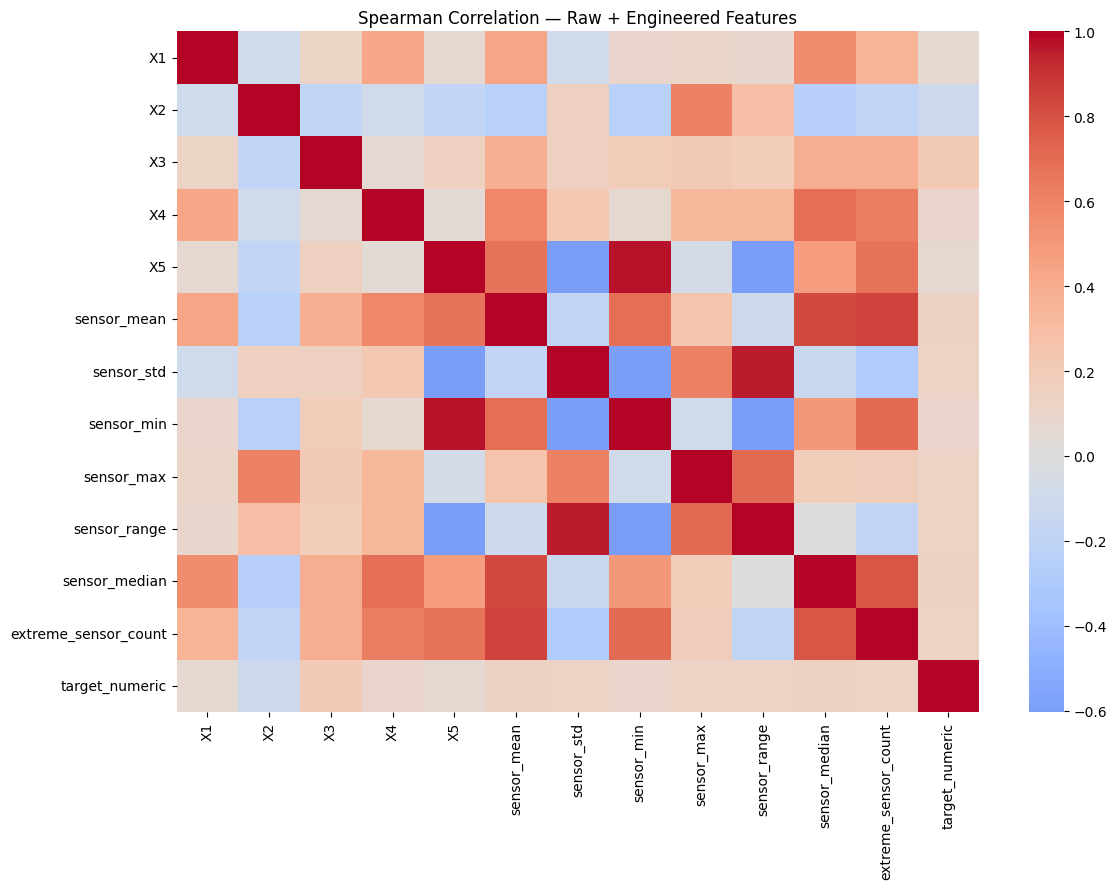

In [42]:
# ============================================================
# CELL 28 — ENGINEERED FEATURE CORRELATION
# ============================================================

engineered_numeric = [
    "X1",
    "X2",
    "X3",
    "X4",
    "X5",
    "sensor_mean",
    "sensor_std",
    "sensor_min",
    "sensor_max",
    "sensor_range",
    "sensor_median",
    "extreme_sensor_count"
]

corr_data = signal_features[
    engineered_numeric
].copy()

corr_data["target_numeric"] = (
    signal_features["target"]
    .eq("1")
    .astype(np.int8)
)

engineered_corr = corr_data.corr(
    method="spearman"
)

print("=" * 70)
print("ENGINEERED FEATURE CORRELATION")
print("=" * 70)

display(
    engineered_corr["target_numeric"]
    .drop("target_numeric")
    .sort_values(
        key=abs,
        ascending=False
    )
    .to_frame("Spearman correlation")
)


plt.figure(figsize=(12, 9))

sns.heatmap(
    engineered_corr,
    cmap="coolwarm",
    center=0
)

plt.title(
    "Spearman Correlation — Raw + Engineered Features"
)

plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# CELL 29 — MODEL FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd

RANDOM_STATE = 42

SENSOR_COLUMNS = ["X1", "X2", "X3", "X4", "X5"]


def create_features(df):
    """
    Create leakage-safe, deterministic features from raw observations.

    No target information is used here.
    """

    data = df.copy()

    # --------------------------------------------------------
    # Temporal features
    # --------------------------------------------------------

    data["year"] = data["Date"].dt.year
    data["month"] = data["Date"].dt.month
    data["day"] = data["Date"].dt.day
    data["day_of_week"] = data["Date"].dt.dayofweek
    data["day_of_year"] = data["Date"].dt.dayofyear
    data["quarter"] = data["Date"].dt.quarter

    # Cyclic temporal encoding
    data["month_sin"] = np.sin(
        2 * np.pi * data["month"] / 12
    )

    data["month_cos"] = np.cos(
        2 * np.pi * data["month"] / 12
    )

    data["day_of_week_sin"] = np.sin(
        2 * np.pi * data["day_of_week"] / 7
    )

    data["day_of_week_cos"] = np.cos(
        2 * np.pi * data["day_of_week"] / 7
    )

    # --------------------------------------------------------
    # Sensor aggregation features
    # --------------------------------------------------------

    data["sensor_mean"] = data[SENSOR_COLUMNS].mean(axis=1)
    data["sensor_std"] = data[SENSOR_COLUMNS].std(axis=1)
    data["sensor_min"] = data[SENSOR_COLUMNS].min(axis=1)
    data["sensor_max"] = data[SENSOR_COLUMNS].max(axis=1)

    data["sensor_range"] = (
        data["sensor_max"]
        - data["sensor_min"]
    )

    data["sensor_median"] = (
        data[SENSOR_COLUMNS].median(axis=1)
    )

    # --------------------------------------------------------
    # Robust magnitude representations
    # --------------------------------------------------------

    # Signed log preserves sign while compressing huge values
    for col in SENSOR_COLUMNS:
        data[f"{col}_signed_log"] = (
            np.sign(data[col])
            * np.log1p(np.abs(data[col]))
        )

    # --------------------------------------------------------
    # Rare/extreme state indicators
    # --------------------------------------------------------

    data["X3_non_one"] = (
        data["X3"] != 1.0
    ).astype(np.int8)

    data["X4_non_one"] = (
        data["X4"] != 1.0
    ).astype(np.int8)

    data["X5_non_zero"] = (
        data["X5"] != 0.0
    ).astype(np.int8)

    data["X5_high"] = (
        data["X5"] > 2.0
    ).astype(np.int8)

    data["X3_X4_both_non_one"] = (
        (data["X3"] != 1.0)
        &
        (data["X4"] != 1.0)
    ).astype(np.int8)

    data["X3_X5_nonbaseline"] = (
        (data["X3"] != 1.0)
        &
        (data["X5"] != 0.0)
    ).astype(np.int8)

    data["X4_X5_nonbaseline"] = (
        (data["X4"] != 1.0)
        &
        (data["X5"] != 0.0)
    ).astype(np.int8)

    data["extreme_sensor_count"] = (
        data[
            [
                "X3_non_one",
                "X4_non_one",
                "X5_non_zero"
            ]
        ].sum(axis=1)
    )

    # --------------------------------------------------------
    # Remove original Date
    # --------------------------------------------------------

    data = data.drop(columns=["Date"])

    return data


# ------------------------------------------------------------
# Create X and y
# ------------------------------------------------------------

X = create_features(
    train.drop(columns=["target"])
)

y = train["target"].astype(str)

print("=" * 70)
print("ENGINEERED MODEL DATASET")
print("=" * 70)

print("Original train shape:", train.shape)
print("Feature matrix shape:", X.shape)

print("\nTarget dtype:", y.dtype)
print("Target classes:", sorted(y.unique().tolist()))

print("\nNumber of engineered features:", X.shape[1])

display(
    X.head()
)

ENGINEERED MODEL DATASET
Original train shape: (1639424, 7)
Feature matrix shape: (1639424, 34)

Target dtype: object
Target classes: ['0', '1']

Number of engineered features: 34


,X1,X2,X3,X4,X5,year,month,day,day_of_week,day_of_year,quarter,month_sin,month_cos,day_of_week_sin,day_of_week_cos,sensor_mean,sensor_std,sensor_min,sensor_max,sensor_range,sensor_median,X1_signed_log,X2_signed_log,X3_signed_log,X4_signed_log,X5_signed_log,X3_non_one,X4_non_one,X5_non_zero,X5_high,X3_X4_both_non_one,X3_X5_nonbaseline,X4_X5_nonbaseline,extreme_sensor_count
0,1.518921,5.463154,1.0,2.718282,2.890372,2020,12,16,2,351,4,-2.449294e-16,1.0,0.974928,-0.222521,2.718146,1.728793,1.0,5.463154,4.463154,2.718282,0.923831,1.866117,0.693147,1.313262,1.358505,0,1,1,1,0,0,1,2
1,1.546509,5.458010,1.0,2.718282,2.833213,2020,12,16,2,351,4,-2.449294e-16,1.0,0.974928,-0.222521,2.711203,1.720800,1.0,5.458010,4.458010,2.718282,0.934723,1.865321,0.693147,1.313262,1.343703,0,1,1,1,0,0,1,2
2,1.645427,5.456560,1.0,7.389056,2.890372,2020,12,16,2,351,4,-2.449294e-16,1.0,0.974928,-0.222521,3.676283,2.686010,1.0,7.389056,6.389056,2.890372,0.972833,1.865097,0.693147,2.126928,1.358505,0,1,1,1,0,0,1,2
3,1.652022,5.458479,1.0,2.718282,2.890372,2020,12,16,2,351,4,-2.449294e-16,1.0,0.974928,-0.222521,2.743831,1.704731,1.0,5.458479,4.458479,2.718282,0.975322,1.865394,0.693147,1.313262,1.358505,0,1,1,1,0,0,1,2
4,1.695538,5.466709,1.0,2.718282,2.890372,2020,12,16,2,351,4,-2.449294e-16,1.0,0.974928,-0.222521,2.754180,1.701141,1.0,5.466709,4.466709,2.718282,0.991598,1.866667,0.693147,1.313262,1.358505,0,1,1,1,0,0,1,2


In [44]:
# ============================================================
# CELL 30 — ENGINEERED FEATURE VALIDATION
# ============================================================

print("=" * 70)
print("ENGINEERED FEATURE VALIDATION")
print("=" * 70)

# Check missing values
missing_engineered = X.isna().sum()

print(
    "Total missing values:",
    missing_engineered.sum()
)

if missing_engineered.sum() > 0:
    display(
        missing_engineered[
            missing_engineered > 0
        ].to_frame("missing_count")
    )


# ------------------------------------------------------------
# Check infinite values
# ------------------------------------------------------------

numeric_X = X.select_dtypes(
    include=np.number
)

infinite_count = np.isinf(
    numeric_X.to_numpy()
).sum()

print(
    "Total infinite values:",
    infinite_count
)


# ------------------------------------------------------------
# Feature dtypes
# ------------------------------------------------------------

print("\nFeature data types:")

display(
    X.dtypes.value_counts()
    .to_frame("count")
)


# ------------------------------------------------------------
# Feature list
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL FEATURE LIST")
print("=" * 70)

for i, col in enumerate(X.columns, start=1):
    print(f"{i:02d}. {col}")

ENGINEERED FEATURE VALIDATION
Total missing values: 0
Total infinite values: 0

Feature data types:


,count
float64,20
int8,7
int32,6
int64,1



FINAL FEATURE LIST
01. X1
02. X2
03. X3
04. X4
05. X5
06. year
07. month
08. day
09. day_of_week
10. day_of_year
11. quarter
12. month_sin
13. month_cos
14. day_of_week_sin
15. day_of_week_cos
16. sensor_mean
17. sensor_std
18. sensor_min
19. sensor_max
20. sensor_range
21. sensor_median
22. X1_signed_log
23. X2_signed_log
24. X3_signed_log
25. X4_signed_log
26. X5_signed_log
27. X3_non_one
28. X4_non_one
29. X5_non_zero
30. X5_high
31. X3_X4_both_non_one
32. X3_X5_nonbaseline
33. X4_X5_nonbaseline
34. extreme_sensor_count


In [46]:
# ============================================================
# CELL 31 — LEAKAGE-SAFE GROUP CONSTRUCTION
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

print("=" * 70)
print("GROUP CONSTRUCTION FOR VALIDATION")
print("=" * 70)

# Group by the complete original observation:
# Date + X1 + X2 + X3 + X4 + X5

GROUP_COLUMNS = [
    "Date",
    "X1",
    "X2",
    "X3",
    "X4",
    "X5"
]

# Hashing gives us a compact group identifier
groups = pd.util.hash_pandas_object(
    train[GROUP_COLUMNS],
    index=False
).values

print(
    "Total observations:",
    len(groups)
)

print(
    "Unique groups:",
    len(np.unique(groups))
)

print(
    "Duplicate observations:",
    len(groups) - len(np.unique(groups))
)

print(
    "Duplicate percentage:",
    f"{(len(groups) - len(np.unique(groups))) / len(groups) * 100:.3f}%"
)


# ------------------------------------------------------------
# Verify conflicting groups
# ------------------------------------------------------------

group_target_counts = (
    pd.DataFrame({
        "group": groups,
        "target": y.values
    })
    .groupby("group")["target"]
    .nunique()
)

conflicting_group_count = (
    group_target_counts > 1
).sum()

print(
    "\nGroups containing conflicting targets:",
    conflicting_group_count
)

GROUP CONSTRUCTION FOR VALIDATION
Total observations: 1639424
Unique groups: 1582095
Duplicate observations: 57329
Duplicate percentage: 3.497%

Groups containing conflicting targets: 14


In [47]:
# ============================================================
# CELL 32 — STRATIFIED GROUP VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

print("=" * 70)
print("CREATING VALIDATION SPLIT")
print("=" * 70)

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Use the first fold as our fixed validation set
train_idx, valid_idx = next(
    sgkf.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_valid = X.iloc[valid_idx].copy()

y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()

print("Training observations :", f"{len(X_train):,}")
print("Validation observations:", f"{len(X_valid):,}")

print(
    "\nTraining percentage:",
    f"{len(X_train)/len(X)*100:.2f}%"
)

print(
    "Validation percentage:",
    f"{len(X_valid)/len(X)*100:.2f}%"
)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "train": y_train.value_counts(),
    "validation": y_valid.value_counts()
}).fillna(0)

split_summary["train_%"] = (
    split_summary["train"]
    / len(y_train)
    * 100
)

split_summary["validation_%"] = (
    split_summary["validation"]
    / len(y_valid)
    * 100
)

print("\nTarget distribution:")
display(split_summary)


# ------------------------------------------------------------
# Verify no groups overlap
# ------------------------------------------------------------

train_groups = set(groups[train_idx])
valid_groups = set(groups[valid_idx])

overlap = train_groups.intersection(
    valid_groups
)

print(
    "\nGroup overlap between train and validation:",
    len(overlap)
)

CREATING VALIDATION SPLIT
Training observations : 1,311,616
Validation observations: 327,808

Training percentage: 80.00%
Validation percentage: 20.00%

Target distribution:


,train,validation,train_%,validation_%
target,,,,
0,1300436,324950,99.147616,99.128148
1,11180,2858,0.852384,0.871852



Group overlap between train and validation: 0


In [48]:
# ============================================================
# CELL 33 — PREPROCESSING PIPELINES
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# All current engineered features are numerical.
NUMERIC_FEATURES = X.columns.tolist()

# ------------------------------------------------------------
# Linear / distance-based preprocessing
# ------------------------------------------------------------

linear_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

print("=" * 70)
print("PREPROCESSING SETUP")
print("=" * 70)

print(
    "Number of numerical features:",
    len(NUMERIC_FEATURES)
)

print(
    "\nLinear/distance models:"
)

print(
    "Median imputation → StandardScaler"
)

print(
    "\nTree-based models:"
)

print(
    "Raw numerical features will be used."
)

print(
    "\nWhy?"
)

print(
    "Scaling is important for Logistic Regression, KNN and SVM, "
    "but generally unnecessary for tree-based models."
)

PREPROCESSING SETUP
Number of numerical features: 34

Linear/distance models:
Median imputation → StandardScaler

Tree-based models:
Raw numerical features will be used.

Why?
Scaling is important for Logistic Regression, KNN and SVM, but generally unnecessary for tree-based models.


In [49]:
# ============================================================
# CELL 34 — LOGISTIC REGRESSION BASELINE
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def evaluate_binary_model(
    model,
    X_train,
    y_train,
    X_valid,
    y_valid,
    model_name
):
    """
    Train and evaluate a binary classification model.
    """

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_valid
    )

    accuracy = accuracy_score(
        y_valid,
        predictions
    )

    precision = precision_score(
        y_valid,
        predictions,
        pos_label="1",
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        predictions,
        pos_label="1",
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        predictions,
        pos_label="1",
        zero_division=0
    )

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(f"Accuracy : {accuracy:.6f}")
    print(f"Precision: {precision:.6f}")
    print(f"Recall   : {recall:.6f}")
    print(f"F1       : {f1:.6f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_valid,
            predictions,
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")

    cm = confusion_matrix(
        y_valid,
        predictions,
        labels=["0", "1"]
    )

    display(
        pd.DataFrame(
            cm,
            index=["Actual 0", "Actual 1"],
            columns=["Predicted 0", "Predicted 1"]
        )
    )

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


# ------------------------------------------------------------
# Logistic Regression — balanced
# ------------------------------------------------------------

logistic_balanced = Pipeline([
    (
        "preprocessing",
        linear_preprocessor
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=300,
            solver="liblinear",
            random_state=RANDOM_STATE
        )
    )
])

logistic_result = evaluate_binary_model(
    logistic_balanced,
    X_train,
    y_train,
    X_valid,
    y_valid,
    "Logistic Regression — Balanced"
)

Logistic Regression — Balanced
Accuracy : 0.952024
Precision: 0.146553
Recall   : 0.933520
F1       : 0.253335

Classification Report:
              precision    recall  f1-score   support

           0     0.9994    0.9522    0.9752    324950
           1     0.1466    0.9335    0.2533      2858

    accuracy                         0.9520    327808
   macro avg     0.5730    0.9429    0.6143    327808
weighted avg     0.9920    0.9520    0.9689    327808

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,309413,15537
Actual 1,190,2668


In [50]:
# ============================================================
# CELL 35 — CLASS WEIGHT COMPARISON
# ============================================================

results_baseline = []

# ------------------------------------------------------------
# Unweighted Logistic Regression
# ------------------------------------------------------------

logistic_unweighted = Pipeline([
    (
        "preprocessing",
        linear_preprocessor
    ),
    (
        "model",
        LogisticRegression(
            class_weight=None,
            max_iter=300,
            solver="liblinear",
            random_state=RANDOM_STATE
        )
    )
])

result_unweighted = evaluate_binary_model(
    logistic_unweighted,
    X_train,
    y_train,
    X_valid,
    y_valid,
    "Logistic Regression — Unweighted"
)

results_baseline.append(
    result_unweighted
)


# ------------------------------------------------------------
# Balanced Logistic Regression
# ------------------------------------------------------------

results_baseline.append(
    logistic_result
)


# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

baseline_comparison = pd.DataFrame(
    results_baseline
)

print("\n" + "=" * 70)
print("BASELINE COMPARISON")
print("=" * 70)

display(
    baseline_comparison
    .sort_values(
        "f1",
        ascending=False
    )
)

Logistic Regression — Unweighted
Accuracy : 0.994610
Precision: 0.831208
Recall   : 0.479006
F1       : 0.607769

Classification Report:
              precision    recall  f1-score   support

           0     0.9954    0.9991    0.9973    324950
           1     0.8312    0.4790    0.6078      2858

    accuracy                         0.9946    327808
   macro avg     0.9133    0.7391    0.8025    327808
weighted avg     0.9940    0.9946    0.9939    327808

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,324672,278
Actual 1,1489,1369



BASELINE COMPARISON


,model,accuracy,precision,recall,f1
0,Logistic Regression — Unweighted,0.994610,0.831208,0.479006,0.607769
1,Logistic Regression — Balanced,0.952024,0.146553,0.933520,0.253335


In [51]:
# ============================================================
# CELL 36 — CLASSICAL MODEL SAMPLING
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("PREPARING CLASSICAL MODEL DATA")
print("=" * 70)

# ------------------------------------------------------------
# KNN / LinearSVC can become expensive on 1.3M observations.
# We therefore create a stratified subset for these models.
#
# Tree models will still use the complete training split.
# ------------------------------------------------------------

CLASSICAL_SAMPLE_SIZE = min(200_000, len(X_train))

X_classical, _, y_classical, _ = train_test_split(
    X_train,
    y_train,
    train_size=CLASSICAL_SAMPLE_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print(
    "Classical-model training sample:",
    f"{len(X_classical):,}"
)

print(
    "\nClassical sample target distribution:"
)

display(
    y_classical.value_counts()
    .to_frame("count")
    .assign(
        percentage=lambda d:
        d["count"] / len(y_classical) * 100
    )
)

# ------------------------------------------------------------
# Validation sample for KNN
# ------------------------------------------------------------

KNN_VALIDATION_SIZE = min(100_000, len(X_valid))

X_knn_valid, _, y_knn_valid, _ = train_test_split(
    X_valid,
    y_valid,
    train_size=KNN_VALIDATION_SIZE,
    stratify=y_valid,
    random_state=RANDOM_STATE
)

print(
    "\nKNN validation sample:",
    f"{len(X_knn_valid):,}"
)

print(
    "\nFull validation set will still be used for "
    "LinearSVC and tree-based models."
)

PREPARING CLASSICAL MODEL DATA
Classical-model training sample: 200,000

Classical sample target distribution:


,count,percentage
target,,
0,198295,99.1475
1,1705,0.8525



KNN validation sample: 100,000

Full validation set will still be used for LinearSVC and tree-based models.


In [52]:
# ============================================================
# CELL 37 — KNN & LINEAR SVM
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

classical_results = []

# ============================================================
# KNN
# ============================================================

print("=" * 70)
print("TRAINING KNN")
print("=" * 70)

knn_model = Pipeline([
    (
        "preprocessing",
        linear_preprocessor
    ),
    (
        "model",
        KNeighborsClassifier(
            n_neighbors=15,
            weights="distance",
            n_jobs=-1
        )
    )
])

knn_model.fit(
    X_classical,
    y_classical
)

knn_pred = knn_model.predict(
    X_knn_valid
)

knn_accuracy = accuracy_score(
    y_knn_valid,
    knn_pred
)

knn_precision = precision_score(
    y_knn_valid,
    knn_pred,
    pos_label="1",
    zero_division=0
)

knn_recall = recall_score(
    y_knn_valid,
    knn_pred,
    pos_label="1",
    zero_division=0
)

knn_f1 = f1_score(
    y_knn_valid,
    knn_pred,
    pos_label="1",
    zero_division=0
)

print(f"KNN Accuracy : {knn_accuracy:.6f}")
print(f"KNN Precision: {knn_precision:.6f}")
print(f"KNN Recall   : {knn_recall:.6f}")
print(f"KNN F1       : {knn_f1:.6f}")

classical_results.append({
    "model": "KNN",
    "accuracy": knn_accuracy,
    "precision": knn_precision,
    "recall": knn_recall,
    "f1": knn_f1
})


# ============================================================
# LINEAR SVM
# ============================================================

print("\n" + "=" * 70)
print("TRAINING LINEAR SVM")
print("=" * 70)

linear_svm = Pipeline([
    (
        "preprocessing",
        linear_preprocessor
    ),
    (
        "model",
        LinearSVC(
            class_weight="balanced",
            C=1.0,
            max_iter=3000,
            random_state=RANDOM_STATE
        )
    )
])

linear_svm.fit(
    X_classical,
    y_classical
)

svm_pred = linear_svm.predict(
    X_valid
)

svm_accuracy = accuracy_score(
    y_valid,
    svm_pred
)

svm_precision = precision_score(
    y_valid,
    svm_pred,
    pos_label="1",
    zero_division=0
)

svm_recall = recall_score(
    y_valid,
    svm_pred,
    pos_label="1",
    zero_division=0
)

svm_f1 = f1_score(
    y_valid,
    svm_pred,
    pos_label="1",
    zero_division=0
)

print(f"SVM Accuracy : {svm_accuracy:.6f}")
print(f"SVM Precision: {svm_precision:.6f}")
print(f"SVM Recall   : {svm_recall:.6f}")
print(f"SVM F1       : {svm_f1:.6f}")

classical_results.append({
    "model": "Linear SVM",
    "accuracy": svm_accuracy,
    "precision": svm_precision,
    "recall": svm_recall,
    "f1": svm_f1
})

TRAINING KNN
KNN Accuracy : 0.995070
KNN Precision: 0.851577
KNN Recall   : 0.526376
KNN F1       : 0.650602

TRAINING LINEAR SVM
SVM Accuracy : 0.956206
SVM Precision: 0.157716
SVM Recall   : 0.926872
SVM F1       : 0.269563


In [53]:
# ============================================================
# CELL 38 — DECISION TREE
# ============================================================

from sklearn.tree import DecisionTreeClassifier

print("=" * 70)
print("DECISION TREE")
print("=" * 70)

decision_tree = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    criterion="entropy",
    random_state=RANDOM_STATE
)

decision_tree.fit(
    X_train,
    y_train
)

dt_pred = decision_tree.predict(
    X_valid
)

dt_accuracy = accuracy_score(
    y_valid,
    dt_pred
)

dt_precision = precision_score(
    y_valid,
    dt_pred,
    pos_label="1",
    zero_division=0
)

dt_recall = recall_score(
    y_valid,
    dt_pred,
    pos_label="1",
    zero_division=0
)

dt_f1 = f1_score(
    y_valid,
    dt_pred,
    pos_label="1",
    zero_division=0
)

print(f"Accuracy : {dt_accuracy:.6f}")
print(f"Precision: {dt_precision:.6f}")
print(f"Recall   : {dt_recall:.6f}")
print(f"F1       : {dt_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid,
        dt_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

cm_dt = confusion_matrix(
    y_valid,
    dt_pred,
    labels=["0", "1"]
)

display(
    pd.DataFrame(
        cm_dt,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

DECISION TREE
Accuracy : 0.959071
Precision: 0.165664
Recall   : 0.915325
F1       : 0.280551

Classification Report:
              precision    recall  f1-score   support

           0     0.9992    0.9595    0.9789    324950
           1     0.1657    0.9153    0.2806      2858

    accuracy                         0.9591    327808
   macro avg     0.5824    0.9374    0.6297    327808
weighted avg     0.9920    0.9591    0.9728    327808


Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,311775,13175
Actual 1,242,2616


In [54]:
# ============================================================
# CELL 39 — RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("RANDOM FOREST")
print("=" * 70)

random_forest = RandomForestClassifier(
    n_estimators=150,
    max_depth=16,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

random_forest.fit(
    X_train,
    y_train
)

rf_pred = random_forest.predict(
    X_valid
)

rf_accuracy = accuracy_score(
    y_valid,
    rf_pred
)

rf_precision = precision_score(
    y_valid,
    rf_pred,
    pos_label="1",
    zero_division=0
)

rf_recall = recall_score(
    y_valid,
    rf_pred,
    pos_label="1",
    zero_division=0
)

rf_f1 = f1_score(
    y_valid,
    rf_pred,
    pos_label="1",
    zero_division=0
)

print(f"Accuracy : {rf_accuracy:.6f}")
print(f"Precision: {rf_precision:.6f}")
print(f"Recall   : {rf_recall:.6f}")
print(f"F1       : {rf_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid,
        rf_pred,
        digits=4,
        zero_division=0
    )
)

RANDOM FOREST
Accuracy : 0.983185
Precision: 0.326536
Recall   : 0.874038
F1       : 0.475447

Classification Report:
              precision    recall  f1-score   support

           0     0.9989    0.9841    0.9915    324950
           1     0.3265    0.8740    0.4754      2858

    accuracy                         0.9832    327808
   macro avg     0.6627    0.9291    0.7335    327808
weighted avg     0.9930    0.9832    0.9870    327808



In [55]:
# ============================================================
# CELL 40 — EXTRA TREES
# ============================================================

from sklearn.ensemble import ExtraTreesClassifier

print("=" * 70)
print("EXTRA TREES")
print("=" * 70)

extra_trees = ExtraTreesClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

extra_trees.fit(
    X_train,
    y_train
)

et_pred = extra_trees.predict(
    X_valid
)

et_accuracy = accuracy_score(
    y_valid,
    et_pred
)

et_precision = precision_score(
    y_valid,
    et_pred,
    pos_label="1",
    zero_division=0
)

et_recall = recall_score(
    y_valid,
    et_pred,
    pos_label="1",
    zero_division=0
)

et_f1 = f1_score(
    y_valid,
    et_pred,
    pos_label="1",
    zero_division=0
)

print(f"Accuracy : {et_accuracy:.6f}")
print(f"Precision: {et_precision:.6f}")
print(f"Recall   : {et_recall:.6f}")
print(f"F1       : {et_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid,
        et_pred,
        digits=4,
        zero_division=0
    )
)

EXTRA TREES
Accuracy : 0.977414
Precision: 0.268628
Recall   : 0.923373
F1       : 0.416180

Classification Report:
              precision    recall  f1-score   support

           0     0.9993    0.9779    0.9885    324950
           1     0.2686    0.9234    0.4162      2858

    accuracy                         0.9774    327808
   macro avg     0.6340    0.9506    0.7023    327808
weighted avg     0.9929    0.9774    0.9835    327808



In [56]:
# ============================================================
# CELL 41 — CLASSICAL + TREE MODEL COMPARISON
# ============================================================

all_model_results = []

# ------------------------------------------------------------
# Logistic Regression results from previous cells
# ------------------------------------------------------------

all_model_results.extend(
    baseline_comparison.to_dict("records")
)

# ------------------------------------------------------------
# Classical models
# ------------------------------------------------------------

all_model_results.extend(
    classical_results
)

# ------------------------------------------------------------
# Decision Tree
# ------------------------------------------------------------

all_model_results.append({
    "model": "Decision Tree",
    "accuracy": dt_accuracy,
    "precision": dt_precision,
    "recall": dt_recall,
    "f1": dt_f1
})

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

all_model_results.append({
    "model": "Random Forest",
    "accuracy": rf_accuracy,
    "precision": rf_precision,
    "recall": rf_recall,
    "f1": rf_f1
})

# ------------------------------------------------------------
# Extra Trees
# ------------------------------------------------------------

all_model_results.append({
    "model": "Extra Trees",
    "accuracy": et_accuracy,
    "precision": et_precision,
    "recall": et_recall,
    "f1": et_f1
})


model_comparison = pd.DataFrame(
    all_model_results
)

# Remove duplicate column names / formatting issues if any
model_comparison = model_comparison[
    [
        "model",
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
]

model_comparison = model_comparison.sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(
    model_comparison.style.format({
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

MODEL COMPARISON


,model,accuracy,precision,recall,f1
0,KNN,0.995070,0.851577,0.526376,0.650602
1,Logistic Regression — Unweighted,0.994610,0.831208,0.479006,0.607769
2,Random Forest,0.983185,0.326536,0.874038,0.475447
3,Extra Trees,0.977414,0.268628,0.923373,0.416180
4,Decision Tree,0.959071,0.165664,0.915325,0.280551
5,Linear SVM,0.956206,0.157716,0.926872,0.269563
6,Logistic Regression — Balanced,0.952024,0.146553,0.933520,0.253335


RANDOM FOREST FEATURE IMPORTANCE


,feature,importance
16,sensor_std,0.152097
15,sensor_mean,0.140083
18,sensor_max,0.123315
19,sensor_range,0.118694
22,X2_signed_log,0.069956
20,sensor_median,0.067387
1,X2,0.067293
23,X3_signed_log,0.032209
2,X3,0.030312
24,X4_signed_log,0.020275



EXTRA TREES FEATURE IMPORTANCE


,feature,importance
24,X4_signed_log,0.123855
26,X3_non_one,0.122947
20,sensor_median,0.096338
23,X3_signed_log,0.066559
31,X3_X5_nonbaseline,0.064436
22,X2_signed_log,0.055764
33,extreme_sensor_count,0.053942
1,X2,0.052759
29,X5_high,0.050742
25,X5_signed_log,0.042984


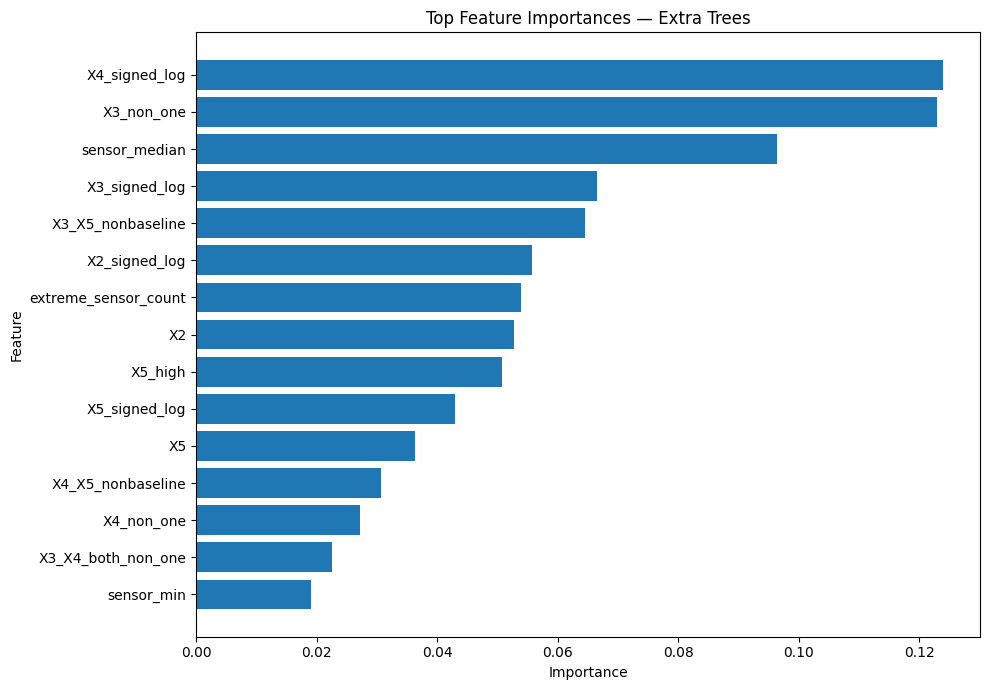

In [57]:
# ============================================================
# CELL 42 — TREE FEATURE IMPORTANCE
# ============================================================

print("=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

rf_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": random_forest.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "importance",
    ascending=False
)

display(
    rf_importance.head(20)
)


print("\n" + "=" * 70)
print("EXTRA TREES FEATURE IMPORTANCE")
print("=" * 70)

et_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": extra_trees.feature_importances_
})

et_importance = et_importance.sort_values(
    "importance",
    ascending=False
)

display(
    et_importance.head(20)
)


# ------------------------------------------------------------
# Plot top features from Extra Trees
# ------------------------------------------------------------

top_n = 15

top_features = (
    et_importance
    .head(top_n)
    .sort_values("importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.title(
    "Top Feature Importances — Extra Trees"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [58]:
# ============================================================
# CELL 43 — ADVANCED MODEL SETUP
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("ADVANCED MODEL SETUP")
print("=" * 70)


# ------------------------------------------------------------
# Convert target to integer representation
# ------------------------------------------------------------

y_train_int = y_train.astype(int)
y_valid_int = y_valid.astype(int)

print("Training target distribution:")
print(y_train_int.value_counts())

print("\nValidation target distribution:")
print(y_valid_int.value_counts())


# ------------------------------------------------------------
# Class imbalance
# ------------------------------------------------------------

negative_count = (y_train_int == 0).sum()
positive_count = (y_train_int == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print("\nClass imbalance:")
print(f"Class 0: {negative_count:,}")
print(f"Class 1: {positive_count:,}")
print(
    f"Natural negative/positive ratio: "
    f"{scale_pos_weight:.2f}"
)


# ------------------------------------------------------------
# Check advanced libraries
# ------------------------------------------------------------

try:
    import xgboost as xgb
    print(
        f"\nXGBoost available: {xgb.__version__}"
    )
except Exception as e:
    print("\nXGBoost import failed:")
    print(e)


try:
    import lightgbm as lgb
    print(
        f"LightGBM available: {lgb.__version__}"
    )
except Exception as e:
    print("\nLightGBM import failed:")
    print(e)


try:
    import catboost
    from catboost import CatBoostClassifier
    print(
        f"CatBoost available: {catboost.__version__}"
    )
except Exception as e:
    print("\nCatBoost import failed:")
    print(e)


print("\nModeling data:")
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

ADVANCED MODEL SETUP
Training target distribution:
target
0    1300436
1      11180
Name: count, dtype: int64

Validation target distribution:
target
0    324950
1      2858
Name: count, dtype: int64

Class imbalance:
Class 0: 1,300,436
Class 1: 11,180
Natural negative/positive ratio: 116.32

XGBoost available: 3.2.0
LightGBM available: 4.6.0
CatBoost available: 1.2.10

Modeling data:
X_train: (1311616, 34)
X_valid: (327808, 34)


In [59]:
# ============================================================
# CELL 44 — XGBOOST
# ============================================================

from xgboost import XGBClassifier

print("=" * 70)
print("XGBOOST")
print("=" * 70)

xgb_model = XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,

    subsample=0.85,
    colsample_bytree=0.85,

    gamma=0.0,

    reg_alpha=0.05,
    reg_lambda=2.0,

    objective="binary:logistic",
    eval_metric="logloss",

    tree_method="hist",
    max_bin=256,

    n_jobs=-1,
    random_state=RANDOM_STATE,

    # Prevent premature complexity
    early_stopping_rounds=50
)

print("Training XGBoost...")
print("This may take some time on 1.31M rows.")

xgb_model.fit(
    X_train,
    y_train_int,

    eval_set=[
        (X_valid, y_valid_int)
    ],

    verbose=False
)

print("\nTraining completed.")

if hasattr(xgb_model, "best_iteration"):
    print(
        "Best iteration:",
        xgb_model.best_iteration
    )

if hasattr(xgb_model, "best_score"):
    print(
        "Best validation score:",
        xgb_model.best_score
    )


# ------------------------------------------------------------
# Validation probabilities
# ------------------------------------------------------------

xgb_valid_proba = xgb_model.predict_proba(
    X_valid
)[:, 1]

xgb_valid_pred = (
    xgb_valid_proba >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

xgb_accuracy = accuracy_score(
    y_valid_int,
    xgb_valid_pred
)

xgb_precision = precision_score(
    y_valid_int,
    xgb_valid_pred,
    zero_division=0
)

xgb_recall = recall_score(
    y_valid_int,
    xgb_valid_pred,
    zero_division=0
)

xgb_f1 = f1_score(
    y_valid_int,
    xgb_valid_pred,
    zero_division=0
)

print("\n" + "=" * 70)
print("XGBOOST RESULTS — THRESHOLD 0.50")
print("=" * 70)

print(f"Accuracy : {xgb_accuracy:.6f}")
print(f"Precision: {xgb_precision:.6f}")
print(f"Recall   : {xgb_recall:.6f}")
print(f"F1       : {xgb_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid_int,
        xgb_valid_pred,
        digits=4,
        zero_division=0
    )
)

XGBOOST
Training XGBoost...
This may take some time on 1.31M rows.

Training completed.
Best iteration: 599
Best validation score: 0.01116182189268454

XGBOOST RESULTS — THRESHOLD 0.50
Accuracy : 0.996699
Precision: 0.909217
Recall   : 0.690343
F1       : 0.784805

Classification Report:
              precision    recall  f1-score   support

           0     0.9973    0.9994    0.9983    324950
           1     0.9092    0.6903    0.7848      2858

    accuracy                         0.9967    327808
   macro avg     0.9532    0.8449    0.8916    327808
weighted avg     0.9965    0.9967    0.9965    327808



In [60]:
# ============================================================
# CELL 45 — LIGHTGBM
# ============================================================

from lightgbm import LGBMClassifier

print("=" * 70)
print("LIGHTGBM")
print("=" * 70)

lgb_model = LGBMClassifier(
    objective="binary",

    n_estimators=700,
    learning_rate=0.05,

    num_leaves=63,
    max_depth=-1,

    min_child_samples=50,

    subsample=0.85,
    colsample_bytree=0.85,

    reg_alpha=0.05,
    reg_lambda=2.0,

    verbosity=-1,

    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training LightGBM...")
print("This may take some time.")

lgb_model.fit(
    X_train,
    y_train_int,

    eval_set=[
        (X_valid, y_valid_int)
    ],

    callbacks=[
        lgb.early_stopping(
            50,
            verbose=False
        )
    ]
)

print("\nTraining completed.")

if hasattr(lgb_model, "best_iteration_"):
    print(
        "Best iteration:",
        lgb_model.best_iteration_
    )


# ------------------------------------------------------------
# Validation probabilities
# ------------------------------------------------------------

lgb_valid_proba = lgb_model.predict_proba(
    X_valid
)[:, 1]

lgb_valid_pred = (
    lgb_valid_proba >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

lgb_accuracy = accuracy_score(
    y_valid_int,
    lgb_valid_pred
)

lgb_precision = precision_score(
    y_valid_int,
    lgb_valid_pred,
    zero_division=0
)

lgb_recall = recall_score(
    y_valid_int,
    lgb_valid_pred,
    zero_division=0
)

lgb_f1 = f1_score(
    y_valid_int,
    lgb_valid_pred,
    zero_division=0
)

print("\n" + "=" * 70)
print("LIGHTGBM RESULTS — THRESHOLD 0.50")
print("=" * 70)

print(f"Accuracy : {lgb_accuracy:.6f}")
print(f"Precision: {lgb_precision:.6f}")
print(f"Recall   : {lgb_recall:.6f}")
print(f"F1       : {lgb_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid_int,
        lgb_valid_pred,
        digits=4,
        zero_division=0
    )
)

LIGHTGBM
Training LightGBM...
This may take some time.

Training completed.
Best iteration: 700

LIGHTGBM RESULTS — THRESHOLD 0.50
Accuracy : 0.996705
Precision: 0.907424
Recall   : 0.692792
F1       : 0.785714

Classification Report:
              precision    recall  f1-score   support

           0     0.9973    0.9994    0.9983    324950
           1     0.9074    0.6928    0.7857      2858

    accuracy                         0.9967    327808
   macro avg     0.9524    0.8461    0.8920    327808
weighted avg     0.9965    0.9967    0.9965    327808



In [61]:
# ============================================================
# CELL 46 — CATBOOST
# ============================================================

from catboost import CatBoostClassifier

print("=" * 70)
print("CATBOOST")
print("=" * 70)

cat_model = CatBoostClassifier(
    iterations=700,
    depth=8,
    learning_rate=0.05,

    l2_leaf_reg=5,
    random_strength=1.0,

    loss_function="Logloss",
    eval_metric="Logloss",

    # Efficient CPU training
    thread_count=-1,

    random_seed=RANDOM_STATE,

    verbose=False,
    allow_writing_files=False
)

print("Training CatBoost...")
print("This can take longer than LightGBM.")

cat_model.fit(
    X_train,
    y_train_int,

    eval_set=(
        X_valid,
        y_valid_int
    ),

    early_stopping_rounds=50,

    verbose=False
)

print("\nTraining completed.")


# ------------------------------------------------------------
# Validation probabilities
# ------------------------------------------------------------

cat_valid_proba = cat_model.predict_proba(
    X_valid
)[:, 1]

cat_valid_pred = (
    cat_valid_proba >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

cat_accuracy = accuracy_score(
    y_valid_int,
    cat_valid_pred
)

cat_precision = precision_score(
    y_valid_int,
    cat_valid_pred,
    zero_division=0
)

cat_recall = recall_score(
    y_valid_int,
    cat_valid_pred,
    zero_division=0
)

cat_f1 = f1_score(
    y_valid_int,
    cat_valid_pred,
    zero_division=0
)

print("\n" + "=" * 70)
print("CATBOOST RESULTS — THRESHOLD 0.50")
print("=" * 70)

print(f"Accuracy : {cat_accuracy:.6f}")
print(f"Precision: {cat_precision:.6f}")
print(f"Recall   : {cat_recall:.6f}")
print(f"F1       : {cat_f1:.6f}")

print("\nClassification Report:")

print(
    classification_report(
        y_valid_int,
        cat_valid_pred,
        digits=4,
        zero_division=0
    )
)

CATBOOST
Training CatBoost...
This can take longer than LightGBM.

Training completed.

CATBOOST RESULTS — THRESHOLD 0.50
Accuracy : 0.996434
Precision: 0.919940
Recall   : 0.647306
F1       : 0.759910

Classification Report:
              precision    recall  f1-score   support

           0     0.9969    0.9995    0.9982    324950
           1     0.9199    0.6473    0.7599      2858

    accuracy                         0.9964    327808
   macro avg     0.9584    0.8234    0.8791    327808
weighted avg     0.9962    0.9964    0.9961    327808



In [62]:
# ============================================================
# CELL 47 — ADVANCED MODEL COMPARISON
# ============================================================

advanced_results = pd.DataFrame([
    {
        "model": "XGBoost",
        "accuracy": xgb_accuracy,
        "precision": xgb_precision,
        "recall": xgb_recall,
        "f1": xgb_f1
    },
    {
        "model": "LightGBM",
        "accuracy": lgb_accuracy,
        "precision": lgb_precision,
        "recall": lgb_recall,
        "f1": lgb_f1
    },
    {
        "model": "CatBoost",
        "accuracy": cat_accuracy,
        "precision": cat_precision,
        "recall": cat_recall,
        "f1": cat_f1
    }
])

advanced_results = (
    advanced_results
    .sort_values(
        "f1",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("ADVANCED MODEL COMPARISON — THRESHOLD 0.50")
print("=" * 70)

display(
    advanced_results.style.format({
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Compare against previous models
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALL MODELS — CURRENT VALIDATION RESULTS")
print("=" * 70)

combined_results = pd.concat(
    [
        model_comparison,
        advanced_results
    ],
    ignore_index=True
)

combined_results = (
    combined_results
    .sort_values(
        "f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    combined_results.style.format({
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

ADVANCED MODEL COMPARISON — THRESHOLD 0.50


,model,accuracy,precision,recall,f1
0,LightGBM,0.996705,0.907424,0.692792,0.785714
1,XGBoost,0.996699,0.909217,0.690343,0.784805
2,CatBoost,0.996434,0.919940,0.647306,0.759910



ALL MODELS — CURRENT VALIDATION RESULTS


,model,accuracy,precision,recall,f1
0,LightGBM,0.996705,0.907424,0.692792,0.785714
1,XGBoost,0.996699,0.909217,0.690343,0.784805
2,CatBoost,0.996434,0.919940,0.647306,0.759910
3,KNN,0.995070,0.851577,0.526376,0.650602
4,Logistic Regression — Unweighted,0.994610,0.831208,0.479006,0.607769
5,Random Forest,0.983185,0.326536,0.874038,0.475447
6,Extra Trees,0.977414,0.268628,0.923373,0.416180
7,Decision Tree,0.959071,0.165664,0.915325,0.280551
8,Linear SVM,0.956206,0.157716,0.926872,0.269563
9,Logistic Regression — Balanced,0.952024,0.146553,0.933520,0.253335


In [63]:
# ============================================================
# CELL 48 — CLASS-WISE ADVANCED MODEL EVALUATION
# ============================================================

def classwise_metrics(
    y_true,
    y_pred,
    model_name
):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    return {
        "model": model_name,

        "class_0_precision":
            report["0"]["precision"],

        "class_0_recall":
            report["0"]["recall"],

        "class_0_f1":
            report["0"]["f1-score"],

        "class_1_precision":
            report["1"]["precision"],

        "class_1_recall":
            report["1"]["recall"],

        "class_1_f1":
            report["1"]["f1-score"],

        "accuracy":
            report["accuracy"]
    }


classwise_results = pd.DataFrame([
    classwise_metrics(
        y_valid_int,
        xgb_valid_pred,
        "XGBoost"
    ),

    classwise_metrics(
        y_valid_int,
        lgb_valid_pred,
        "LightGBM"
    ),

    classwise_metrics(
        y_valid_int,
        cat_valid_pred,
        "CatBoost"
    )
])


classwise_results = (
    classwise_results
    .sort_values(
        "class_1_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("CLASS-WISE PERFORMANCE")
print("=" * 70)

display(
    classwise_results.style.format(
        {
            col: "{:.6f}"
            for col in classwise_results.columns
            if col != "model"
        }
    )
)


# ------------------------------------------------------------
# Confusion matrices
# ------------------------------------------------------------

for name, pred in [
    ("XGBoost", xgb_valid_pred),
    ("LightGBM", lgb_valid_pred),
    ("CatBoost", cat_valid_pred)
]:

    print("\n" + "=" * 70)
    print(f"{name} — CONFUSION MATRIX")
    print("=" * 70)

    cm = confusion_matrix(
        y_valid_int,
        pred,
        labels=[0, 1]
    )

    display(
        pd.DataFrame(
            cm,
            index=["Actual 0", "Actual 1"],
            columns=["Predicted 0", "Predicted 1"]
        )
    )

CLASS-WISE PERFORMANCE


,model,class_0_precision,class_0_recall,class_0_f1,class_1_precision,class_1_recall,class_1_f1,accuracy
0,LightGBM,0.997304,0.999378,0.998340,0.907424,0.692792,0.785714,0.996705
1,XGBoost,0.997282,0.999394,0.998337,0.909217,0.690343,0.784805,0.996699
2,CatBoost,0.996906,0.999505,0.998204,0.919940,0.647306,0.759910,0.996434



XGBoost — CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,324753,197
Actual 1,885,1973



LightGBM — CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,324748,202
Actual 1,878,1980



CatBoost — CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,324789,161
Actual 1,1008,1850


In [64]:
# ============================================================
# CELL 49 — ADVANCED MODEL FEATURE IMPORTANCE
# ============================================================

print("=" * 70)
print("FEATURE IMPORTANCE — LIGHTGBM")
print("=" * 70)

lgb_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgb_model.feature_importances_
})

lgb_importance = (
    lgb_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lgb_importance.head(20)
)


# ------------------------------------------------------------
# XGBoost importance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE — XGBOOST")
print("=" * 70)

xgb_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
})

xgb_importance = (
    xgb_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    xgb_importance.head(20)
)


# ------------------------------------------------------------
# CatBoost importance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE — CATBOOST")
print("=" * 70)

cat_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": cat_model.get_feature_importance()
})

cat_importance = (
    cat_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    cat_importance.head(20)
)


# ------------------------------------------------------------
# Consensus importance
# ------------------------------------------------------------

importance_consensus = (
    lgb_importance[["feature", "importance"]]
    .rename(columns={"importance": "lightgbm"})
    .merge(
        xgb_importance[["feature", "importance"]]
        .rename(columns={"importance": "xgboost"}),
        on="feature"
    )
    .merge(
        cat_importance[["feature", "importance"]]
        .rename(columns={"importance": "catboost"}),
        on="feature"
    )
)

# Normalize each model's importance
for col in ["lightgbm", "xgboost", "catboost"]:
    total = importance_consensus[col].sum()

    if total > 0:
        importance_consensus[col] = (
            importance_consensus[col] / total
        )

importance_consensus["mean_importance"] = (
    importance_consensus[
        ["lightgbm", "xgboost", "catboost"]
    ].mean(axis=1)
)

importance_consensus = (
    importance_consensus
    .sort_values(
        "mean_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("CONSENSUS FEATURE IMPORTANCE")
print("=" * 70)

display(
    importance_consensus.head(20)
)

FEATURE IMPORTANCE — LIGHTGBM


,feature,importance
0,day_of_year,4970
1,X1,4875
2,day,4860
3,X2,4207
4,year,1954
5,sensor_mean,1945
6,sensor_median,1794
7,X4,1761
8,day_of_week,1599
9,day_of_week_sin,1564



FEATURE IMPORTANCE — XGBOOST


,feature,importance
0,sensor_mean,0.319829
1,X2_signed_log,0.112058
2,X4,0.081820
3,sensor_max,0.068175
4,sensor_median,0.054418
5,sensor_range,0.047468
6,X3_signed_log,0.039160
7,month_cos,0.023455
8,X3_X5_nonbaseline,0.022873
9,X3,0.017920



FEATURE IMPORTANCE — CATBOOST


,feature,importance
0,day,15.927540
1,X2_signed_log,11.736551
2,X2,10.231023
3,month_cos,9.763744
4,year,8.399761
5,day_of_year,6.539700
6,X5,5.091463
7,day_of_week_sin,3.202174
8,month_sin,2.694347
9,sensor_min,2.668305



CONSENSUS FEATURE IMPORTANCE


,feature,lightgbm,xgboost,catboost,mean_importance
0,sensor_mean,0.044816,0.319829,0.026146,0.130264
1,day,0.111982,0.012116,0.159275,0.094458
2,X2_signed_log,0.014908,0.112058,0.117366,0.081444
3,X2,0.096935,0.011537,0.102310,0.070261
4,day_of_year,0.114516,0.008822,0.065397,0.062912
5,month_cos,0.034240,0.023455,0.097637,0.051777
6,X1,0.112327,0.011291,0.020366,0.047995
7,year,0.045023,0.010100,0.083998,0.046374
8,X4,0.040576,0.081820,0.011323,0.044573
9,sensor_median,0.041336,0.054418,0.018055,0.037937


In [65]:
# ============================================================
# CELL 50 — PREDICTED PROBABILITY DISTRIBUTIONS
# ============================================================

print("=" * 70)
print("VALIDATION PROBABILITY ANALYSIS")
print("=" * 70)

probability_summary = pd.DataFrame({
    "XGBoost": xgb_valid_proba,
    "LightGBM": lgb_valid_proba,
    "CatBoost": cat_valid_proba
}).describe(
    percentiles=[
        0.50,
        0.90,
        0.95,
        0.99,
        0.995,
        0.999
    ]
)

display(
    probability_summary
)


# ------------------------------------------------------------
# Probability statistics by actual class
# ------------------------------------------------------------

for name, probabilities in [
    ("XGBoost", xgb_valid_proba),
    ("LightGBM", lgb_valid_proba),
    ("CatBoost", cat_valid_proba)
]:

    temp = pd.DataFrame({
        "probability": probabilities,
        "actual": y_valid_int.values
    })

    print("\n" + "=" * 70)
    print(f"{name} — PROBABILITY BY ACTUAL CLASS")
    print("=" * 70)

    display(
        temp.groupby("actual")["probability"]
        .describe(
            percentiles=[
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )

VALIDATION PROBABILITY ANALYSIS


,XGBoost,LightGBM,CatBoost
count,3.278080e+05,3.278080e+05,3.278080e+05
mean,8.622212e-03,8.571562e-03,8.666709e-03
std,7.466076e-02,7.442159e-02,7.232864e-02
min,5.427499e-08,1.008784e-07,2.944294e-08
50%,2.421404e-05,2.294919e-05,4.506889e-05
90%,1.924880e-03,1.883023e-03,2.820309e-03
95%,7.445902e-03,7.066323e-03,9.246382e-03
99%,1.956420e-01,1.937216e-01,1.947689e-01
99.5%,7.524936e-01,7.507349e-01,6.877008e-01
99.9%,9.988956e-01,9.988415e-01,9.982460e-01



XGBoost — PROBABILITY BY ACTUAL CLASS


,count,mean,std,min,50%,75%,90%,95%,99%,max
actual,,,,,,,,,,
0,324950.0,0.002814,0.024696,5.427499e-08,0.000023,0.000209,0.001653,0.005628,0.058158,0.975219
1,2858.0,0.668981,0.357652,2.445311e-05,0.820600,0.989957,0.999103,0.999599,0.999940,0.999993



LightGBM — PROBABILITY BY ACTUAL CLASS


,count,mean,std,min,50%,75%,90%,95%,99%,max
actual,,,,,,,,,,
0,324950.0,0.002779,0.024583,1.008784e-07,0.000022,0.000228,0.001635,0.005381,0.057312,0.972249
1,2858.0,0.667168,0.359212,3.623827e-05,0.825610,0.990923,0.999092,0.999636,0.999963,0.999996



CatBoost — PROBABILITY BY ACTUAL CLASS


,count,mean,std,min,50%,75%,90%,95%,99%,max
actual,,,,,,,,,,
0,324950.0,0.003146,0.024399,2.944294e-08,0.000044,0.000367,0.002489,0.007055,0.067343,0.989281
1,2858.0,0.636396,0.367265,7.387673e-05,0.778585,0.986176,0.998576,0.999547,0.999969,0.999998


In [66]:
# ============================================================
# CELL 51 — THRESHOLD SWEEP
# ============================================================

thresholds = np.arange(
    0.05,
    0.951,
    0.005
)


def threshold_analysis(
    y_true,
    probabilities,
    model_name
):

    rows = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "model": model_name,
            "threshold": threshold,

            "accuracy": accuracy_score(
                y_true,
                predictions
            ),

            "precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "f1": f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        })

    return pd.DataFrame(rows)


threshold_results = pd.concat([
    threshold_analysis(
        y_valid_int,
        xgb_valid_proba,
        "XGBoost"
    ),

    threshold_analysis(
        y_valid_int,
        lgb_valid_proba,
        "LightGBM"
    ),

    threshold_analysis(
        y_valid_int,
        cat_valid_proba,
        "CatBoost"
    )
], ignore_index=True)


print("=" * 70)
print("THRESHOLD SWEEP COMPLETED")
print("=" * 70)

print(
    "Threshold range:",
    thresholds.min(),
    "to",
    thresholds.max()
)

print(
    "Number of thresholds tested:",
    len(thresholds)
)

display(
    threshold_results.head()
)

THRESHOLD SWEEP COMPLETED
Threshold range: 0.05 to 0.9499999999999996
Number of thresholds tested: 181


,model,threshold,accuracy,precision,recall,f1
0,XGBoost,0.050,0.988030,0.414446,0.903429,0.568222
1,XGBoost,0.055,0.988753,0.430581,0.899580,0.582399
2,XGBoost,0.060,0.989421,0.446753,0.895381,0.596087
3,XGBoost,0.065,0.990037,0.462976,0.892582,0.609704
4,XGBoost,0.070,0.990568,0.477949,0.887334,0.621264


In [67]:
# ============================================================
# CELL 52 — BEST THRESHOLD IDENTIFICATION
# ============================================================

print("=" * 70)
print("OPTIMAL THRESHOLDS")
print("=" * 70)

best_threshold_rows = []

for model_name in [
    "XGBoost",
    "LightGBM",
    "CatBoost"
]:

    model_results = threshold_results[
        threshold_results["model"] == model_name
    ].copy()

    # --------------------------------------------------------
    # Primary objective: anomaly-class F1
    # --------------------------------------------------------

    best_f1_row = (
        model_results
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    # --------------------------------------------------------
    # Best accuracy
    # --------------------------------------------------------

    best_accuracy_row = (
        model_results
        .sort_values(
            "accuracy",
            ascending=False
        )
        .iloc[0]
    )

    best_threshold_rows.append({
        "model": model_name,

        "f1_best_threshold":
            best_f1_row["threshold"],

        "best_f1":
            best_f1_row["f1"],

        "precision_at_best_f1":
            best_f1_row["precision"],

        "recall_at_best_f1":
            best_f1_row["recall"],

        "accuracy_at_best_f1":
            best_f1_row["accuracy"],

        "accuracy_best_threshold":
            best_accuracy_row["threshold"],

        "best_accuracy":
            best_accuracy_row["accuracy"]
    })


best_thresholds = pd.DataFrame(
    best_threshold_rows
)

display(
    best_thresholds.style.format({
        "f1_best_threshold": "{:.3f}",
        "best_f1": "{:.6f}",
        "precision_at_best_f1": "{:.6f}",
        "recall_at_best_f1": "{:.6f}",
        "accuracy_at_best_f1": "{:.6f}",
        "accuracy_best_threshold": "{:.3f}",
        "best_accuracy": "{:.6f}"
    })
)

OPTIMAL THRESHOLDS


,model,f1_best_threshold,best_f1,precision_at_best_f1,recall_at_best_f1,accuracy_at_best_f1,accuracy_best_threshold,best_accuracy
0,XGBoost,0.410,0.796958,0.872606,0.733380,0.996742,0.425,0.996745
1,LightGBM,0.365,0.794123,0.847559,0.747026,0.996623,0.450,0.996727
2,CatBoost,0.375,0.772849,0.852024,0.707138,0.996376,0.470,0.996434


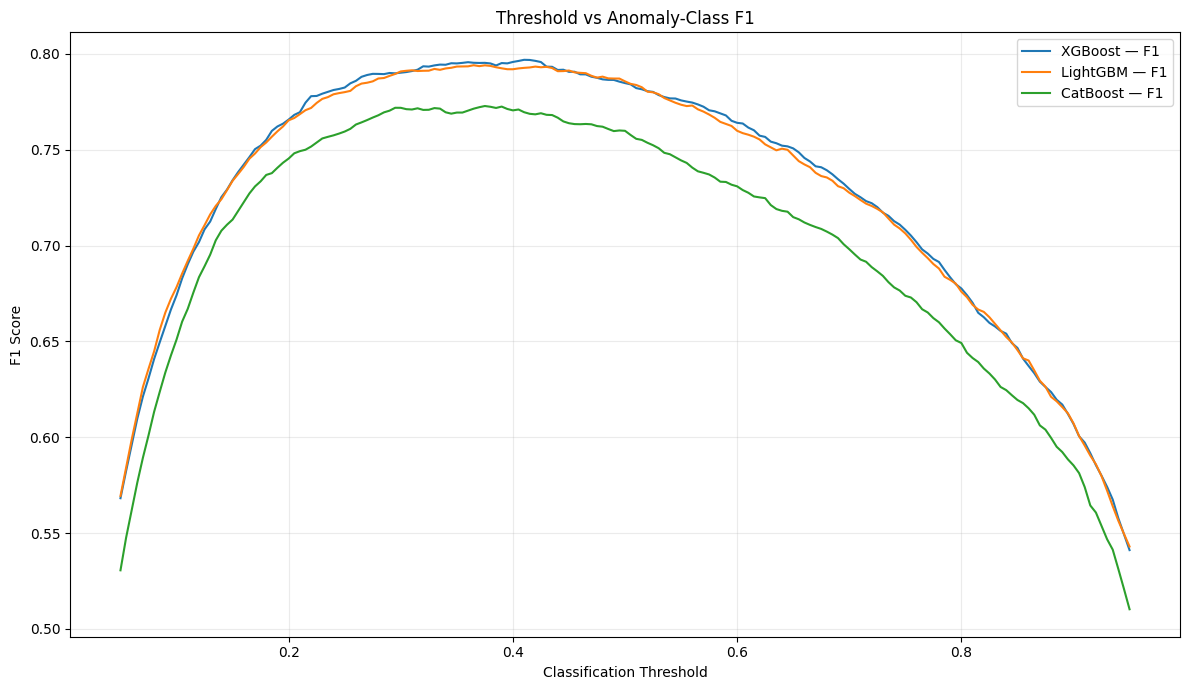

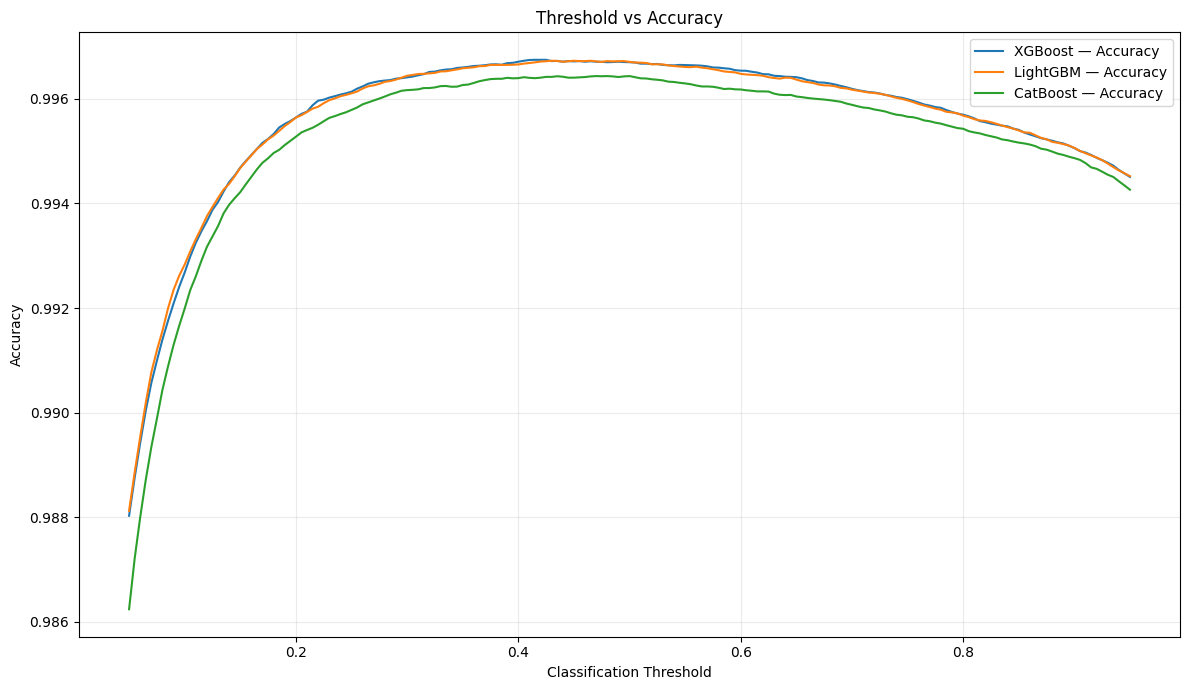

In [68]:
# ============================================================
# CELL 53 — THRESHOLD PERFORMANCE CURVES
# ============================================================

plt.figure(figsize=(12, 7))

for model_name in [
    "XGBoost",
    "LightGBM",
    "CatBoost"
]:

    model_results = threshold_results[
        threshold_results["model"] == model_name
    ]

    plt.plot(
        model_results["threshold"],
        model_results["f1"],
        label=f"{model_name} — F1"
    )

plt.xlabel("Classification Threshold")
plt.ylabel("F1 Score")

plt.title(
    "Threshold vs Anomaly-Class F1"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Accuracy plot
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

for model_name in [
    "XGBoost",
    "LightGBM",
    "CatBoost"
]:

    model_results = threshold_results[
        threshold_results["model"] == model_name
    ]

    plt.plot(
        model_results["threshold"],
        model_results["accuracy"],
        label=f"{model_name} — Accuracy"
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Accuracy")

plt.title(
    "Threshold vs Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [69]:
# ============================================================
# CELL 54 — OPTIMIZED THRESHOLD EVALUATION
# ============================================================

optimized_predictions = {}

optimized_results = []

for model_name, probabilities in [
    ("XGBoost", xgb_valid_proba),
    ("LightGBM", lgb_valid_proba),
    ("CatBoost", cat_valid_proba)
]:

    best_row = (
        threshold_results[
            threshold_results["model"] == model_name
        ]
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    threshold = best_row["threshold"]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    optimized_predictions[
        model_name
    ] = predictions

    print("\n" + "=" * 70)
    print(
        f"{model_name} — OPTIMIZED THRESHOLD = "
        f"{threshold:.3f}"
    )
    print("=" * 70)

    print(
        classification_report(
            y_valid_int,
            predictions,
            digits=5,
            zero_division=0
        )
    )

    optimized_results.append({
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_valid_int,
            predictions
        ),
        "precision": precision_score(
            y_valid_int,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_valid_int,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_valid_int,
            predictions,
            zero_division=0
        )
    })


optimized_results = pd.DataFrame(
    optimized_results
)

display(
    optimized_results.style.format({
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)


XGBoost — OPTIMIZED THRESHOLD = 0.410
              precision    recall  f1-score   support

           0    0.99766   0.99906   0.99836    324950
           1    0.87261   0.73338   0.79696      2858

    accuracy                        0.99674    327808
   macro avg    0.93513   0.86622   0.89766    327808
weighted avg    0.99657   0.99674   0.99660    327808


LightGBM — OPTIMIZED THRESHOLD = 0.365
              precision    recall  f1-score   support

           0    0.99778   0.99882   0.99830    324950
           1    0.84756   0.74703   0.79412      2858

    accuracy                        0.99662    327808
   macro avg    0.92267   0.87292   0.89621    327808
weighted avg    0.99647   0.99662   0.99652    327808


CatBoost — OPTIMIZED THRESHOLD = 0.375
              precision    recall  f1-score   support

           0    0.99743   0.99892   0.99817    324950
           1    0.85202   0.70714   0.77285      2858

    accuracy                        0.99638    327808
   macro 

,model,threshold,accuracy,precision,recall,f1
0,XGBoost,0.410,0.996742,0.872606,0.733380,0.796958
1,LightGBM,0.365,0.996623,0.847559,0.747026,0.794123
2,CatBoost,0.375,0.996376,0.852024,0.707138,0.772849


In [70]:
# ============================================================
# CELL 55 — DEFAULT VS OPTIMIZED THRESHOLD
# ============================================================

threshold_comparison = []

for model_name in [
    "XGBoost",
    "LightGBM",
    "CatBoost"
]:

    default_row = {
        "model": model_name,
        "strategy": "Default 0.50"
    }

    optimized_row = {
        "model": model_name,
        "strategy": "Optimized F1 threshold"
    }

    if model_name == "XGBoost":

        default_pred = xgb_valid_pred
        optimized_pred = optimized_predictions[
            "XGBoost"
        ]

    elif model_name == "LightGBM":

        default_pred = lgb_valid_pred
        optimized_pred = optimized_predictions[
            "LightGBM"
        ]

    else:

        default_pred = cat_valid_pred
        optimized_pred = optimized_predictions[
            "CatBoost"
        ]

    for row, predictions in [
        (default_row, default_pred),
        (optimized_row, optimized_pred)
    ]:

        row["threshold"] = (
            0.50
            if row["strategy"] == "Default 0.50"
            else optimized_results.loc[
                optimized_results["model"] == model_name,
                "threshold"
            ].iloc[0]
        )

        row["accuracy"] = accuracy_score(
            y_valid_int,
            predictions
        )

        row["precision"] = precision_score(
            y_valid_int,
            predictions,
            zero_division=0
        )

        row["recall"] = recall_score(
            y_valid_int,
            predictions,
            zero_division=0
        )

        row["f1"] = f1_score(
            y_valid_int,
            predictions,
            zero_division=0
        )

        threshold_comparison.append(row)


threshold_comparison = pd.DataFrame(
    threshold_comparison
)

print("=" * 70)
print("DEFAULT VS OPTIMIZED THRESHOLD")
print("=" * 70)

display(
    threshold_comparison.style.format({
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

DEFAULT VS OPTIMIZED THRESHOLD


,model,strategy,threshold,accuracy,precision,recall,f1
0,XGBoost,Default 0.50,0.500,0.996699,0.909217,0.690343,0.784805
1,XGBoost,Optimized F1 threshold,0.410,0.996742,0.872606,0.733380,0.796958
2,LightGBM,Default 0.50,0.500,0.996705,0.907424,0.692792,0.785714
3,LightGBM,Optimized F1 threshold,0.365,0.996623,0.847559,0.747026,0.794123
4,CatBoost,Default 0.50,0.500,0.996434,0.919940,0.647306,0.759910
5,CatBoost,Optimized F1 threshold,0.375,0.996376,0.852024,0.707138,0.772849


In [71]:
# ============================================================
# CELL 56 — PROVISIONAL MODEL SELECTION
# ============================================================

print("=" * 70)
print("PROVISIONAL MODEL SELECTION")
print("=" * 70)

provisional_ranking = (
    optimized_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(
    provisional_ranking.style.format({
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)


best_model = (
    provisional_ranking
    .iloc[0]["model"]
)

best_threshold = (
    provisional_ranking
    .iloc[0]["threshold"]
)

best_f1 = (
    provisional_ranking
    .iloc[0]["f1"]
)

print("\n" + "=" * 70)
print("CURRENT BEST CANDIDATE")
print("=" * 70)

print("Model    :", best_model)
print(
    "Threshold:",
    f"{best_threshold:.3f}"
)

print(
    "F1       :",
    f"{best_f1:.6f}"
)

print(
    "\nIMPORTANT:"
)

print(
    "This is a provisional result from one validation split."
)

print(
    "We will confirm the threshold and model using "
    "out-of-fold predictions before final training."
)

PROVISIONAL MODEL SELECTION


,model,threshold,accuracy,precision,recall,f1
0,XGBoost,0.410,0.996742,0.872606,0.733380,0.796958
1,LightGBM,0.365,0.996623,0.847559,0.747026,0.794123
2,CatBoost,0.375,0.996376,0.852024,0.707138,0.772849



CURRENT BEST CANDIDATE
Model    : XGBoost
Threshold: 0.410
F1       : 0.796958

IMPORTANT:
This is a provisional result from one validation split.
We will confirm the threshold and model using out-of-fold predictions before final training.


In [72]:
# ============================================================
# CELL 57 — INITIALIZE 5-FOLD OOF VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

print("=" * 70)
print("INITIALIZING 5-FOLD OOF VALIDATION")
print("=" * 70)

N_SPLITS = 5

oof_xgb = np.full(
    len(X),
    np.nan,
    dtype=np.float32
)

oof_lgb = np.full(
    len(X),
    np.nan,
    dtype=np.float32
)

oof_fold = np.full(
    len(X),
    -1,
    dtype=np.int8
)


# ------------------------------------------------------------
# Recreate identical folds
# ------------------------------------------------------------

oof_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_indices = list(
    oof_cv.split(
        X,
        y,
        groups=groups
    )
)


# ------------------------------------------------------------
# Reuse fold 1 from our existing validation
# ------------------------------------------------------------

oof_xgb[valid_idx] = (
    xgb_valid_proba.astype(np.float32)
)

oof_lgb[valid_idx] = (
    lgb_valid_proba.astype(np.float32)
)

oof_fold[valid_idx] = 0


print("Number of folds:", N_SPLITS)

for fold_number, (tr_idx, va_idx) in enumerate(
    fold_indices,
    start=1
):

    print(
        f"\nFold {fold_number}:"
    )

    print(
        f"  Train: {len(tr_idx):,}"
    )

    print(
        f"  Valid: {len(va_idx):,}"
    )

    print(
        f"  Anomaly rate: "
        f"{y.iloc[va_idx].astype(int).mean()*100:.4f}%"
    )

print(
    "\nFold 1 probabilities reused from Cells 44 and 45."
)

INITIALIZING 5-FOLD OOF VALIDATION
Number of folds: 5

Fold 1:
  Train: 1,311,616
  Valid: 327,808
  Anomaly rate: 0.8719%

Fold 2:
  Train: 1,311,320
  Valid: 328,104
  Anomaly rate: 0.8634%

Fold 3:
  Train: 1,311,504
  Valid: 327,920
  Anomaly rate: 0.8606%

Fold 4:
  Train: 1,311,575
  Valid: 327,849
  Anomaly rate: 0.8342%

Fold 5:
  Train: 1,311,681
  Valid: 327,743
  Anomaly rate: 0.8513%

Fold 1 probabilities reused from Cells 44 and 45.


In [73]:
# ============================================================
# CELL 58 — XGBOOST OOF PREDICTIONS
# ============================================================

from xgboost import XGBClassifier
import gc

print("=" * 70)
print("XGBOOST — OOF PREDICTIONS")
print("=" * 70)

# Use the best iteration discovered on our original fold.
XGB_OOF_ESTIMATORS = (
    xgb_model.best_iteration + 1
    if hasattr(xgb_model, "best_iteration")
    else 600
)

print(
    "XGBoost estimators:",
    XGB_OOF_ESTIMATORS
)

for fold_number, (tr_idx, va_idx) in enumerate(
    fold_indices,
    start=1
):

    # Fold 1 already exists
    if fold_number == 1:
        print(
            "\nFold 1 → reused existing predictions"
        )
        continue

    print("\n" + "-" * 70)
    print(
        f"Training XGBoost — Fold {fold_number}/5"
    )
    print("-" * 70)

    fold_model = XGBClassifier(
        n_estimators=XGB_OOF_ESTIMATORS,

        learning_rate=0.05,
        max_depth=8,
        min_child_weight=5,

        subsample=0.85,
        colsample_bytree=0.85,

        gamma=0.0,

        reg_alpha=0.05,
        reg_lambda=2.0,

        objective="binary:logistic",
        eval_metric="logloss",

        tree_method="hist",
        max_bin=256,

        n_jobs=-1,
        random_state=RANDOM_STATE + fold_number
    )

    fold_model.fit(
        X.iloc[tr_idx],
        y.iloc[tr_idx].astype(int),
        verbose=False
    )

    fold_probability = fold_model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

    oof_xgb[va_idx] = (
        fold_probability.astype(np.float32)
    )

    oof_fold[va_idx] = (
        fold_number - 1
    )

    print(
        f"Fold {fold_number} completed."
    )

    print(
        f"Validation rows: {len(va_idx):,}"
    )

    del fold_model
    del fold_probability

    gc.collect()


print("\n" + "=" * 70)
print("XGBOOST OOF COMPLETE")
print("=" * 70)

print(
    "OOF predictions available:",
    np.isfinite(oof_xgb).sum()
)

print(
    "Missing OOF predictions:",
    np.isnan(oof_xgb).sum()
)

XGBOOST — OOF PREDICTIONS
XGBoost estimators: 600

Fold 1 → reused existing predictions

----------------------------------------------------------------------
Training XGBoost — Fold 2/5
----------------------------------------------------------------------
Fold 2 completed.
Validation rows: 328,104

----------------------------------------------------------------------
Training XGBoost — Fold 3/5
----------------------------------------------------------------------
Fold 3 completed.
Validation rows: 327,920

----------------------------------------------------------------------
Training XGBoost — Fold 4/5
----------------------------------------------------------------------
Fold 4 completed.
Validation rows: 327,849

----------------------------------------------------------------------
Training XGBoost — Fold 5/5
----------------------------------------------------------------------
Fold 5 completed.
Validation rows: 327,743

XGBOOST OOF COMPLETE
OOF predictions available: 1639424

In [74]:
# ============================================================
# CELL 59 — LIGHTGBM OOF PREDICTIONS
# ============================================================

from lightgbm import LGBMClassifier
import gc

print("=" * 70)
print("LIGHTGBM — OOF PREDICTIONS")
print("=" * 70)

LGB_OOF_ESTIMATORS = (
    lgb_model.best_iteration_
    if hasattr(lgb_model, "best_iteration_")
    else 700
)

print(
    "LightGBM estimators:",
    LGB_OOF_ESTIMATORS
)


for fold_number, (tr_idx, va_idx) in enumerate(
    fold_indices,
    start=1
):

    # Fold 1 already exists
    if fold_number == 1:

        print(
            "\nFold 1 → reused existing predictions"
        )

        continue


    print("\n" + "-" * 70)
    print(
        f"Training LightGBM — Fold {fold_number}/5"
    )
    print("-" * 70)


    fold_model = LGBMClassifier(

        objective="binary",

        n_estimators=LGB_OOF_ESTIMATORS,

        learning_rate=0.05,

        num_leaves=63,
        max_depth=-1,

        min_child_samples=50,

        subsample=0.85,
        colsample_bytree=0.85,

        reg_alpha=0.05,
        reg_lambda=2.0,

        verbosity=-1,

        n_jobs=-1,

        random_state=RANDOM_STATE + fold_number
    )


    fold_model.fit(
        X.iloc[tr_idx],
        y.iloc[tr_idx].astype(int)
    )


    fold_probability = fold_model.predict_proba(
        X.iloc[va_idx]
    )[:, 1]


    oof_lgb[va_idx] = (
        fold_probability.astype(np.float32)
    )

    oof_fold[va_idx] = (
        fold_number - 1
    )


    print(
        f"Fold {fold_number} completed."
    )

    print(
        f"Validation rows: {len(va_idx):,}"
    )


    del fold_model
    del fold_probability

    gc.collect()


print("\n" + "=" * 70)
print("LIGHTGBM OOF COMPLETE")
print("=" * 70)

print(
    "OOF predictions available:",
    np.isfinite(oof_lgb).sum()
)

print(
    "Missing OOF predictions:",
    np.isnan(oof_lgb).sum()
)

LIGHTGBM — OOF PREDICTIONS
LightGBM estimators: 700

Fold 1 → reused existing predictions

----------------------------------------------------------------------
Training LightGBM — Fold 2/5
----------------------------------------------------------------------
Fold 2 completed.
Validation rows: 328,104

----------------------------------------------------------------------
Training LightGBM — Fold 3/5
----------------------------------------------------------------------
Fold 3 completed.
Validation rows: 327,920

----------------------------------------------------------------------
Training LightGBM — Fold 4/5
----------------------------------------------------------------------
Fold 4 completed.
Validation rows: 327,849

----------------------------------------------------------------------
Training LightGBM — Fold 5/5
----------------------------------------------------------------------
Fold 5 completed.
Validation rows: 327,743

LIGHTGBM OOF COMPLETE
OOF predictions available: 

In [75]:
# ============================================================
# CELL 60 — OOF INTEGRITY CHECK
# ============================================================

print("=" * 70)
print("OOF INTEGRITY CHECK")
print("=" * 70)


# ------------------------------------------------------------
# Prediction completeness
# ------------------------------------------------------------

print(
    "Total observations:",
    len(X)
)

print(
    "XGBoost OOF predictions:",
    np.isfinite(oof_xgb).sum()
)

print(
    "LightGBM OOF predictions:",
    np.isfinite(oof_lgb).sum()
)

print(
    "Missing XGBoost:",
    np.isnan(oof_xgb).sum()
)

print(
    "Missing LightGBM:",
    np.isnan(oof_lgb).sum()
)


# ------------------------------------------------------------
# Fold distribution
# ------------------------------------------------------------

print("\nOOF fold distribution:")

display(
    pd.Series(
        oof_fold
    )
    .value_counts()
    .sort_index()
    .to_frame("observations")
)


# ------------------------------------------------------------
# Verify group integrity
# ------------------------------------------------------------

group_fold_df = pd.DataFrame({
    "group": groups,
    "fold": oof_fold
})

group_fold_counts = (
    group_fold_df
    .groupby("group")["fold"]
    .nunique()
)

groups_split_across_folds = (
    group_fold_counts > 1
).sum()

print(
    "\nGroups split across multiple folds:",
    groups_split_across_folds
)


# ------------------------------------------------------------
# OOF target distribution by fold
# ------------------------------------------------------------

oof_target_by_fold = pd.DataFrame({
    "fold": oof_fold,
    "target": y.astype(int).values
})

fold_summary = (
    oof_target_by_fold
    .groupby("fold")["target"]
    .agg(
        observations="count",
        anomalies="sum",
        anomaly_rate="mean"
    )
)

fold_summary["anomaly_rate_%"] = (
    fold_summary["anomaly_rate"] * 100
)

display(
    fold_summary.drop(
        columns="anomaly_rate"
    )
)

OOF INTEGRITY CHECK
Total observations: 1639424
XGBoost OOF predictions: 1639424
LightGBM OOF predictions: 1639424
Missing XGBoost: 0
Missing LightGBM: 0

OOF fold distribution:


,observations
0,327808
1,328104
2,327920
3,327849
4,327743



Groups split across multiple folds: 0


,observations,anomalies,anomaly_rate_%
fold,,,
0,327808,2858,0.871852
1,328104,2833,0.863446
2,327920,2822,0.860576
3,327849,2735,0.834226
4,327743,2790,0.851277


In [76]:
# ============================================================
# CELL 61 — OOF PERFORMANCE
# ============================================================

print("=" * 70)
print("OUT-OF-FOLD PERFORMANCE — THRESHOLD 0.50")
print("=" * 70)


oof_xgb_pred = (
    oof_xgb >= 0.50
).astype(int)

oof_lgb_pred = (
    oof_lgb >= 0.50
).astype(int)


oof_results = pd.DataFrame([
    {
        "model": "XGBoost OOF",

        "accuracy": accuracy_score(
            y.astype(int),
            oof_xgb_pred
        ),

        "precision": precision_score(
            y.astype(int),
            oof_xgb_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y.astype(int),
            oof_xgb_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y.astype(int),
            oof_xgb_pred,
            zero_division=0
        )
    },

    {
        "model": "LightGBM OOF",

        "accuracy": accuracy_score(
            y.astype(int),
            oof_lgb_pred
        ),

        "precision": precision_score(
            y.astype(int),
            oof_lgb_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y.astype(int),
            oof_lgb_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y.astype(int),
            oof_lgb_pred,
            zero_division=0
        )
    }
])


display(
    oof_results.style.format({
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Detailed reports
# ------------------------------------------------------------

print("\nXGBoost OOF classification report:")

print(
    classification_report(
        y.astype(int),
        oof_xgb_pred,
        digits=5,
        zero_division=0
    )
)


print("\nLightGBM OOF classification report:")

print(
    classification_report(
        y.astype(int),
        oof_lgb_pred,
        digits=5,
        zero_division=0
    )
)

OUT-OF-FOLD PERFORMANCE — THRESHOLD 0.50


,model,accuracy,precision,recall,f1
0,XGBoost OOF,0.996762,0.912805,0.687562,0.784333
1,LightGBM OOF,0.996698,0.910832,0.681080,0.779376



XGBoost OOF classification report:
              precision    recall  f1-score   support

           0    0.99731   0.99943   0.99837   1625386
           1    0.91280   0.68756   0.78433     14038

    accuracy                        0.99676   1639424
   macro avg    0.95506   0.84350   0.89135   1639424
weighted avg    0.99658   0.99676   0.99654   1639424


LightGBM OOF classification report:
              precision    recall  f1-score   support

           0    0.99725   0.99942   0.99834   1625386
           1    0.91083   0.68108   0.77938     14038

    accuracy                        0.99670   1639424
   macro avg    0.95404   0.84025   0.88886   1639424
weighted avg    0.99651   0.99670   0.99646   1639424



In [77]:
# ============================================================
# CELL 62 — OOF THRESHOLD OPTIMIZATION
# ============================================================

print("=" * 70)
print("OOF THRESHOLD OPTIMIZATION")
print("=" * 70)


oof_thresholds = np.arange(
    0.10,
    0.901,
    0.005
)


def find_oof_best_threshold(
    y_true,
    probabilities,
    model_name
):

    rows = []

    for threshold in oof_thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "model": model_name,

            "threshold": threshold,

            "accuracy": accuracy_score(
                y_true,
                predictions
            ),

            "precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "f1": f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        })

    results = pd.DataFrame(rows)

    best = (
        results
        .sort_values(
            ["f1", "precision"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    return results, best


oof_xgb_threshold_results, best_xgb_oof = (
    find_oof_best_threshold(
        y.astype(int),
        oof_xgb,
        "XGBoost"
    )
)


oof_lgb_threshold_results, best_lgb_oof = (
    find_oof_best_threshold(
        y.astype(int),
        oof_lgb,
        "LightGBM"
    )
)


oof_best_thresholds = pd.DataFrame([
    best_xgb_oof,
    best_lgb_oof
])


print(
    "BEST OOF THRESHOLDS:"
)

display(
    oof_best_thresholds.style.format({
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

OOF THRESHOLD OPTIMIZATION
BEST OOF THRESHOLDS:


,model,threshold,accuracy,precision,recall,f1
49,XGBoost,0.345,0.996751,0.846969,0.757373,0.799669
49,LightGBM,0.345,0.996695,0.845021,0.751959,0.795778


In [78]:
# ============================================================
# CELL 63 — OOF STABILITY & VALIDATION COMPARISON
# ============================================================

print("=" * 70)
print("OOF STABILITY ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# OOF predictions at their optimized thresholds
# ------------------------------------------------------------

best_xgb_threshold = (
    best_xgb_oof["threshold"]
)

best_lgb_threshold = (
    best_lgb_oof["threshold"]
)


oof_xgb_opt_pred = (
    oof_xgb >= best_xgb_threshold
).astype(int)

oof_lgb_opt_pred = (
    oof_lgb >= best_lgb_threshold
).astype(int)


# ------------------------------------------------------------
# Overall OOF summary
# ------------------------------------------------------------

stability_summary = pd.DataFrame([
    {
        "model": "XGBoost",

        "original_valid_threshold":
            best_thresholds.loc[
                best_thresholds["model"] == "XGBoost",
                "f1_best_threshold"
            ].iloc[0],

        "original_valid_f1":
            best_thresholds.loc[
                best_thresholds["model"] == "XGBoost",
                "best_f1"
            ].iloc[0],

        "OOF_threshold":
            best_xgb_threshold,

        "OOF_F1":
            f1_score(
                y.astype(int),
                oof_xgb_opt_pred,
                zero_division=0
            ),

        "OOF_precision":
            precision_score(
                y.astype(int),
                oof_xgb_opt_pred,
                zero_division=0
            ),

        "OOF_recall":
            recall_score(
                y.astype(int),
                oof_xgb_opt_pred,
                zero_division=0
            )
    },

    {
        "model": "LightGBM",

        "original_valid_threshold":
            best_thresholds.loc[
                best_thresholds["model"] == "LightGBM",
                "f1_best_threshold"
            ].iloc[0],

        "original_valid_f1":
            best_thresholds.loc[
                best_thresholds["model"] == "LightGBM",
                "best_f1"
            ].iloc[0],

        "OOF_threshold":
            best_lgb_threshold,

        "OOF_F1":
            f1_score(
                y.astype(int),
                oof_lgb_opt_pred,
                zero_division=0
            ),

        "OOF_precision":
            precision_score(
                y.astype(int),
                oof_lgb_opt_pred,
                zero_division=0
            ),

        "OOF_recall":
            recall_score(
                y.astype(int),
                oof_lgb_opt_pred,
                zero_division=0
            )
    }
])


display(
    stability_summary.style.format({
        "original_valid_threshold": "{:.3f}",
        "original_valid_f1": "{:.6f}",
        "OOF_threshold": "{:.3f}",
        "OOF_F1": "{:.6f}",
        "OOF_precision": "{:.6f}",
        "OOF_recall": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Fold-wise F1 at OOF-selected threshold
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FOLD-WISE OOF PERFORMANCE")
print("=" * 70)


fold_rows = []


for fold in range(5):

    mask = (
        oof_fold == fold
    )

    fold_y = y.astype(int).values[mask]


    # XGBoost
    fold_xgb_pred = (
        oof_xgb[mask] >= best_xgb_threshold
    ).astype(int)


    # LightGBM
    fold_lgb_pred = (
        oof_lgb[mask] >= best_lgb_threshold
    ).astype(int)


    fold_rows.append({
        "fold": fold + 1,

        "observations": mask.sum(),

        "anomaly_rate_%":
            fold_y.mean() * 100,

        "XGB_F1":
            f1_score(
                fold_y,
                fold_xgb_pred,
                zero_division=0
            ),

        "LGB_F1":
            f1_score(
                fold_y,
                fold_lgb_pred,
                zero_division=0
            )
    })


fold_results = pd.DataFrame(
    fold_rows
)

display(
    fold_results.style.format({
        "anomaly_rate_%": "{:.4f}",
        "XGB_F1": "{:.6f}",
        "LGB_F1": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Mean / standard deviation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CROSS-VALIDATION STABILITY")
print("=" * 70)


for model_name in [
    "XGB_F1",
    "LGB_F1"
]:

    mean_score = fold_results[
        model_name
    ].mean()

    std_score = fold_results[
        model_name
    ].std()

    print(
        f"{model_name}: "
        f"{mean_score:.6f} ± {std_score:.6f}"
    )

OOF STABILITY ANALYSIS


,model,original_valid_threshold,original_valid_f1,OOF_threshold,OOF_F1,OOF_precision,OOF_recall
0,XGBoost,0.410,0.796958,0.345,0.799669,0.846969,0.757373
1,LightGBM,0.365,0.794123,0.345,0.795778,0.845021,0.751959



FOLD-WISE OOF PERFORMANCE


,fold,observations,anomaly_rate_%,XGB_F1,LGB_F1
0,1,327808,0.8719,0.795163,0.792793
1,2,328104,0.8634,0.801117,0.798958
2,3,327920,0.8606,0.800746,0.796328
3,4,327849,0.8342,0.799614,0.792336
4,5,327743,0.8513,0.801840,0.798466



CROSS-VALIDATION STABILITY
XGB_F1: 0.799696 ± 0.002659
LGB_F1: 0.795776 ± 0.003098


In [79]:
# ============================================================
# CELL 64 — OOF PROBABILITY CORRELATION
# ============================================================

print("=" * 70)
print("OOF PREDICTION DIVERSITY ANALYSIS")
print("=" * 70)

oof_probability_df = pd.DataFrame({
    "XGBoost": oof_xgb,
    "LightGBM": oof_lgb
})

print("\nCorrelation between OOF probabilities:")

display(
    oof_probability_df.corr()
)


# ------------------------------------------------------------
# Basic probability statistics
# ------------------------------------------------------------

print("\nOOF probability statistics:")

display(
    oof_probability_df.describe(
        percentiles=[
            0.50,
            0.90,
            0.95,
            0.99,
            0.995,
            0.999
        ]
    )
)


# ------------------------------------------------------------
# Prediction disagreement at OOF thresholds
# ------------------------------------------------------------

xgb_oof_binary = (
    oof_xgb >= best_xgb_threshold
).astype(int)

lgb_oof_binary = (
    oof_lgb >= best_lgb_threshold
).astype(int)

disagreement = (
    xgb_oof_binary != lgb_oof_binary
)

print(
    "\nBinary prediction disagreement:",
    disagreement.sum()
)

print(
    "Disagreement percentage:",
    f"{disagreement.mean()*100:.4f}%"
)

OOF PREDICTION DIVERSITY ANALYSIS

Correlation between OOF probabilities:


,XGBoost,LightGBM
XGBoost,1.000000,0.989055
LightGBM,0.989055,1.000000



OOF probability statistics:


,XGBoost,LightGBM
count,1.639424e+06,1.639424e+06
mean,8.407344e-03,8.354798e-03
std,7.305945e-02,7.277124e-02
min,4.550710e-08,3.013962e-08
50%,2.290024e-05,2.302424e-05
90%,1.916260e-03,1.896684e-03
95%,7.220409e-03,6.977939e-03
99%,1.851970e-01,1.851761e-01
99.5%,7.288825e-01,7.198809e-01
99.9%,9.988533e-01,9.986941e-01



Binary prediction disagreement: 1573
Disagreement percentage: 0.0959%


In [80]:
# ============================================================
# CELL 65 — WEIGHTED XGBOOST + LIGHTGBM OOF ENSEMBLE
# ============================================================

print("=" * 70)
print("XGBOOST + LIGHTGBM ENSEMBLE SEARCH")
print("=" * 70)


ensemble_weight_results = []


for xgb_weight in np.arange(
    0.0,
    1.001,
    0.05
):

    lgb_weight = 1.0 - xgb_weight


    # --------------------------------------------------------
    # Weighted probability
    # --------------------------------------------------------

    ensemble_probability = (
        xgb_weight * oof_xgb
        +
        lgb_weight * oof_lgb
    )


    # --------------------------------------------------------
    # Evaluate at several sensible thresholds
    # --------------------------------------------------------

    for threshold in np.arange(
        0.20,
        0.501,
        0.005
    ):

        ensemble_prediction = (
            ensemble_probability >= threshold
        ).astype(int)


        ensemble_weight_results.append({

            "xgb_weight":
                xgb_weight,

            "lgb_weight":
                lgb_weight,

            "threshold":
                threshold,

            "accuracy":
                accuracy_score(
                    y.astype(int),
                    ensemble_prediction
                ),

            "precision":
                precision_score(
                    y.astype(int),
                    ensemble_prediction,
                    zero_division=0
                ),

            "recall":
                recall_score(
                    y.astype(int),
                    ensemble_prediction,
                    zero_division=0
                ),

            "f1":
                f1_score(
                    y.astype(int),
                    ensemble_prediction,
                    zero_division=0
                )
        })


ensemble_weight_results = pd.DataFrame(
    ensemble_weight_results
)


# ------------------------------------------------------------
# Best ensemble configurations
# ------------------------------------------------------------

best_ensemble_configs = (
    ensemble_weight_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .head(15)
    .reset_index(drop=True)
)


print(
    "\nTOP 15 ENSEMBLE CONFIGURATIONS:"
)

display(
    best_ensemble_configs.style.format({
        "xgb_weight": "{:.2f}",
        "lgb_weight": "{:.2f}",
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

XGBOOST + LIGHTGBM ENSEMBLE SEARCH

TOP 15 ENSEMBLE CONFIGURATIONS:


,xgb_weight,lgb_weight,threshold,accuracy,precision,recall,f1
0,0.75,0.25,0.330,0.996748,0.841412,0.764211,0.800956
1,0.80,0.20,0.320,0.996726,0.835591,0.768984,0.800905
2,0.80,0.20,0.330,0.996745,0.840987,0.764425,0.800881
3,0.75,0.25,0.335,0.996756,0.844053,0.761861,0.800854
4,0.75,0.25,0.325,0.996735,0.838451,0.766420,0.800819
5,0.55,0.45,0.340,0.996766,0.847439,0.758940,0.800752
6,0.60,0.40,0.365,0.996809,0.860311,0.748896,0.800746
7,0.65,0.35,0.330,0.996745,0.841523,0.763713,0.800732
8,0.80,0.20,0.325,0.996734,0.838426,0.766277,0.800729
9,0.85,0.15,0.330,0.996743,0.841111,0.763998,0.800702


In [81]:
# ============================================================
# CELL 66 — ENSEMBLE VS INDIVIDUAL MODELS
# ============================================================

print("=" * 70)
print("INDIVIDUAL MODELS VS ENSEMBLE")
print("=" * 70)


# ------------------------------------------------------------
# Best XGBoost
# ------------------------------------------------------------

xgb_best_f1 = best_xgb_oof["f1"]
xgb_best_threshold = best_xgb_oof["threshold"]


# ------------------------------------------------------------
# Best LightGBM
# ------------------------------------------------------------

lgb_best_f1 = best_lgb_oof["f1"]
lgb_best_threshold = best_lgb_oof["threshold"]


# ------------------------------------------------------------
# Best ensemble
# ------------------------------------------------------------

best_ensemble = (
    ensemble_weight_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)


comparison_rows = [

    {
        "model": "XGBoost",
        "xgb_weight": 1.00,
        "lgb_weight": 0.00,
        "threshold": xgb_best_threshold,
        "f1": xgb_best_f1
    },

    {
        "model": "LightGBM",
        "xgb_weight": 0.00,
        "lgb_weight": 1.00,
        "threshold": lgb_best_threshold,
        "f1": lgb_best_f1
    },

    {
        "model": "XGB + LGB Ensemble",
        "xgb_weight": best_ensemble["xgb_weight"],
        "lgb_weight": best_ensemble["lgb_weight"],
        "threshold": best_ensemble["threshold"],
        "f1": best_ensemble["f1"]
    }
]


ensemble_comparison = pd.DataFrame(
    comparison_rows
)


# Calculate improvement

ensemble_comparison["improvement_vs_best_individual"] = (
    ensemble_comparison["f1"]
    -
    max(
        xgb_best_f1,
        lgb_best_f1
    )
)


display(
    ensemble_comparison.style.format({
        "xgb_weight": "{:.2f}",
        "lgb_weight": "{:.2f}",
        "threshold": "{:.3f}",
        "f1": "{:.6f}",
        "improvement_vs_best_individual": "{:+.6f}"
    })
)


print("\n" + "=" * 70)

if (
    best_ensemble["f1"]
    >
    max(xgb_best_f1, lgb_best_f1)
):

    print(
        "ENSEMBLE IMPROVES OVER THE BEST INDIVIDUAL MODEL."
    )

else:

    print(
        "ENSEMBLE DOES NOT IMPROVE OVER THE BEST INDIVIDUAL MODEL."
    )

print("=" * 70)

INDIVIDUAL MODELS VS ENSEMBLE


,model,xgb_weight,lgb_weight,threshold,f1,improvement_vs_best_individual
0,XGBoost,1.00,0.00,0.345,0.799669,+0.000000
1,LightGBM,0.00,1.00,0.345,0.795778,-0.003891
2,XGB + LGB Ensemble,0.75,0.25,0.330,0.800956,+0.001287



ENSEMBLE IMPROVES OVER THE BEST INDIVIDUAL MODEL.


In [84]:
# ============================================================
# CELL 71 — DETAILED OOF ERROR ANALYSIS
# ============================================================

print("=" * 70)
print("OOF CONFUSION MATRICES & CLASS-WISE PERFORMANCE")
print("=" * 70)


# ------------------------------------------------------------
# Recover the best ensemble configuration
# ------------------------------------------------------------

# From the previous ensemble search:
# XGBoost weight = 0.75
# LightGBM weight = 0.25

BEST_XGB_WEIGHT = 0.75
BEST_LGB_WEIGHT = 0.25


# Recreate ensemble probability
best_ensemble_probability = (
    BEST_XGB_WEIGHT * oof_xgb
    +
    BEST_LGB_WEIGHT * oof_lgb
)


# ------------------------------------------------------------
# Find optimal ensemble threshold
# ------------------------------------------------------------

ensemble_threshold_results = []


for threshold in np.arange(
    0.20,
    0.501,
    0.005
):

    predictions = (
        best_ensemble_probability >= threshold
    ).astype(int)


    accuracy = accuracy_score(
        y.astype(int),
        predictions
    )

    precision = precision_score(
        y.astype(int),
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y.astype(int),
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y.astype(int),
        predictions,
        zero_division=0
    )


    ensemble_threshold_results.append({

        "threshold": threshold,

        "accuracy": accuracy,

        "precision": precision,

        "recall": recall,

        "f1": f1
    })


ensemble_threshold_df = pd.DataFrame(
    ensemble_threshold_results
)


# Best threshold based on F1
best_ensemble_row = (
    ensemble_threshold_df
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)


BEST_ENSEMBLE_THRESHOLD = (
    best_ensemble_row["threshold"]
)


BEST_ENSEMBLE_F1 = (
    best_ensemble_row["f1"]
)


print(
    f"Best Ensemble Threshold: "
    f"{BEST_ENSEMBLE_THRESHOLD:.3f}"
)

print(
    f"Best Ensemble OOF F1: "
    f"{BEST_ENSEMBLE_F1:.6f}"
)


# ------------------------------------------------------------
# Candidate models
# ------------------------------------------------------------

candidate_probabilities = {

    "XGBoost":
        oof_xgb,

    "LightGBM":
        oof_lgb,

    "XGB + LightGBM":
        best_ensemble_probability
}


candidate_thresholds = {

    "XGBoost":
        best_xgb_threshold,

    "LightGBM":
        best_lgb_threshold,

    "XGB + LightGBM":
        BEST_ENSEMBLE_THRESHOLD
}


# ------------------------------------------------------------
# Detailed evaluation
# ------------------------------------------------------------

for model_name in candidate_probabilities:

    probabilities = (
        candidate_probabilities[model_name]
    )

    threshold = (
        candidate_thresholds[model_name]
    )


    predictions = (
        probabilities >= threshold
    ).astype(int)


    print("\n" + "=" * 70)

    print(
        f"{model_name} — "
        f"THRESHOLD {threshold:.3f}"
    )

    print("=" * 70)


    print(
        classification_report(
            y.astype(int),
            predictions,
            digits=6,
            zero_division=0
        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y.astype(int),
        predictions
    )


    cm_df = pd.DataFrame(

        cm,

        index=[
            "Actual 0",
            "Actual 1"
        ],

        columns=[
            "Predicted 0",
            "Predicted 1"
        ]
    )


    print("Confusion Matrix:")

    display(cm_df)


    tn, fp, fn, tp = cm.ravel()


    print(
        f"True Negatives : {tn:,}"
    )

    print(
        f"False Positives: {fp:,}"
    )

    print(
        f"False Negatives: {fn:,}"
    )

    print(
        f"True Positives  : {tp:,}"
    )

OOF CONFUSION MATRICES & CLASS-WISE PERFORMANCE
Best Ensemble Threshold: 0.330
Best Ensemble OOF F1: 0.800956

XGBoost — THRESHOLD 0.345
              precision    recall  f1-score   support

           0   0.997906  0.998818  0.998362   1625386
           1   0.846969  0.757373  0.799669     14038

    accuracy                       0.996751   1639424
   macro avg   0.922438  0.878095  0.899016   1639424
weighted avg   0.996614  0.996751  0.996661   1639424

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,1623465,1921
Actual 1,3406,10632


True Negatives : 1,623,465
False Positives: 1,921
False Negatives: 3,406
True Positives  : 10,632

LightGBM — THRESHOLD 0.345
              precision    recall  f1-score   support

           0   0.997860  0.998809  0.998334   1625386
           1   0.845021  0.751959  0.795778     14038

    accuracy                       0.996695   1639424
   macro avg   0.921440  0.875384  0.897056   1639424
weighted avg   0.996551  0.996695  0.996600   1639424

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,1623450,1936
Actual 1,3482,10556


True Negatives : 1,623,450
False Positives: 1,936
False Negatives: 3,482
True Positives  : 10,556

XGB + LightGBM — THRESHOLD 0.330
              precision    recall  f1-score   support

           0   0.997965  0.998756  0.998360   1625386
           1   0.841412  0.764211  0.800956     14038

    accuracy                       0.996748   1639424
   macro avg   0.919688  0.881484  0.899658   1639424
weighted avg   0.996625  0.996748  0.996670   1639424

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,1623364,2022
Actual 1,3310,10728


True Negatives : 1,623,364
False Positives: 2,022
False Negatives: 3,310
True Positives  : 10,728


In [85]:
# ============================================================
# CELL 72 — FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
# ============================================================

print("=" * 70)
print("ERROR PROFILE COMPARISON")
print("=" * 70)


error_rows = []


for model_name in candidate_probabilities:

    predictions = (
        candidate_probabilities[model_name]
        >= candidate_thresholds[model_name]
    ).astype(int)

    actual = y.astype(int).values

    fp = (
        (actual == 0)
        &
        (predictions == 1)
    ).sum()

    fn = (
        (actual == 1)
        &
        (predictions == 0)
    ).sum()

    tp = (
        (actual == 1)
        &
        (predictions == 1)
    ).sum()

    tn = (
        (actual == 0)
        &
        (predictions == 0)
    ).sum()

    error_rows.append({

        "model": model_name,

        "true_negatives": tn,

        "false_positives": fp,

        "false_negatives": fn,

        "true_positives": tp,

        "FP_rate_%":
            fp / (fp + tn) * 100,

        "FN_rate_%":
            fn / (fn + tp) * 100,

        "anomaly_recall_%":
            tp / (tp + fn) * 100
    })


error_analysis = pd.DataFrame(
    error_rows
)


display(
    error_analysis.style.format({
        "FP_rate_%": "{:.4f}",
        "FN_rate_%": "{:.4f}",
        "anomaly_recall_%": "{:.4f}"
    })
)

ERROR PROFILE COMPARISON


,model,true_negatives,false_positives,false_negatives,true_positives,FP_rate_%,FN_rate_%,anomaly_recall_%
0,XGBoost,1623465,1921,3406,10632,0.1182,24.2627,75.7373
1,LightGBM,1623450,1936,3482,10556,0.1191,24.8041,75.1959
2,XGB + LightGBM,1623364,2022,3310,10728,0.1244,23.5789,76.4211


In [86]:
# ============================================================
# CELL 73 — ENSEMBLE STABILITY AROUND OPTIMAL WEIGHT
# ============================================================

print("=" * 70)
print("ENSEMBLE STABILITY CHECK")
print("=" * 70)


stability_weights = [
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90
]


stability_rows = []


for xgb_weight in stability_weights:

    lgb_weight = 1.0 - xgb_weight

    probability = (
        xgb_weight * oof_xgb
        +
        lgb_weight * oof_lgb
    )

    best_f1 = -1
    best_threshold_local = None
    best_precision = None
    best_recall = None

    for threshold in np.arange(
        0.28,
        0.381,
        0.002
    ):

        prediction = (
            probability >= threshold
        ).astype(int)

        precision = precision_score(
            y.astype(int),
            prediction,
            zero_division=0
        )

        recall = recall_score(
            y.astype(int),
            prediction,
            zero_division=0
        )

        f1 = f1_score(
            y.astype(int),
            prediction,
            zero_division=0
        )

        if f1 > best_f1:

            best_f1 = f1
            best_threshold_local = threshold
            best_precision = precision
            best_recall = recall

    stability_rows.append({

        "XGB_weight": xgb_weight,

        "LGB_weight": lgb_weight,

        "best_threshold":
            best_threshold_local,

        "F1":
            best_f1,

        "precision":
            best_precision,

        "recall":
            best_recall
    })


ensemble_stability = pd.DataFrame(
    stability_rows
)


display(
    ensemble_stability.style.format({
        "XGB_weight": "{:.2f}",
        "LGB_weight": "{:.2f}",
        "best_threshold": "{:.3f}",
        "F1": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}"
    })
)

ENSEMBLE STABILITY CHECK


,XGB_weight,LGB_weight,best_threshold,F1,precision,recall
0,0.60,0.40,0.334,0.800838,0.843408,0.762359
1,0.65,0.35,0.330,0.800732,0.841523,0.763713
2,0.70,0.30,0.338,0.800720,0.845776,0.760222
3,0.75,0.25,0.328,0.800999,0.840388,0.765137
4,0.80,0.20,0.320,0.800905,0.835591,0.768984
5,0.85,0.15,0.336,0.800809,0.844041,0.761789
6,0.90,0.10,0.340,0.800420,0.845635,0.759795


ENSEMBLE PROBABILITY SEPARATION
Probability statistics by actual class:


,count,mean,std,min,50%,75%,90%,95%,99%,99.5%,99.9%,max
actual,,,,,,,,,,,,
0,1625386.0,0.002726,0.023506,5.429744e-08,0.000023,0.000222,0.001686,0.005497,0.056299,0.117629,0.375055,0.988434
1,14038.0,0.664707,0.355235,8.087592e-06,0.808947,0.989816,0.998996,0.999550,0.999927,0.999959,0.999982,0.999993


NameError: name 'best_fine_threshold' is not defined

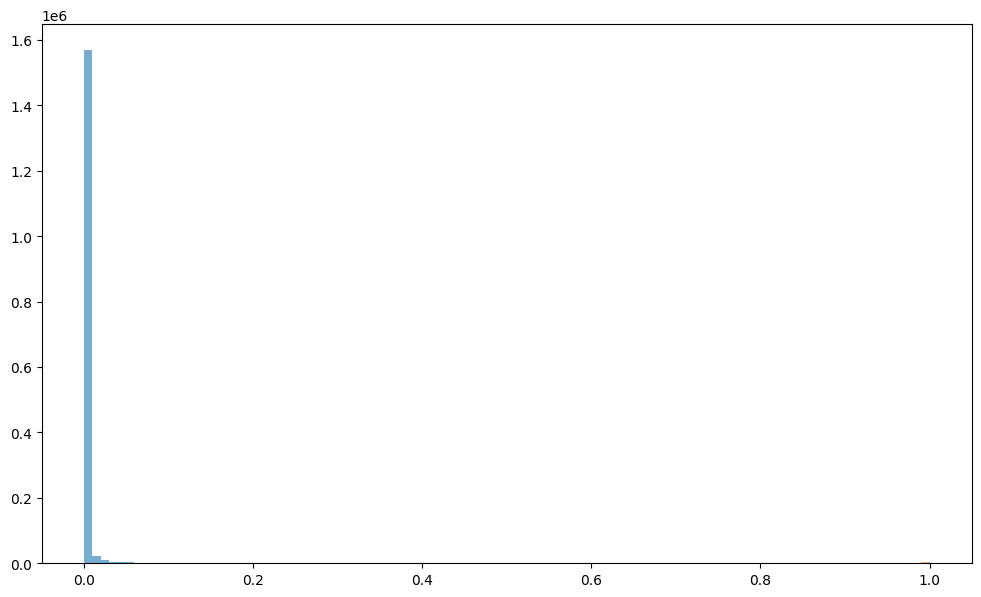

In [87]:
# ============================================================
# CELL 74 — ENSEMBLE PROBABILITY SEPARATION
# ============================================================

print("=" * 70)
print("ENSEMBLE PROBABILITY SEPARATION")
print("=" * 70)


ensemble_probability_df = pd.DataFrame({

    "probability":
        best_ensemble_probability,

    "actual":
        y.astype(int).values

})


print(
    "Probability statistics by actual class:"
)


display(
    ensemble_probability_df
    .groupby("actual")["probability"]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995,
            0.999
        ]
    )
)


# ------------------------------------------------------------
# Probability histogram
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 7)
)

plt.hist(
    ensemble_probability_df.loc[
        ensemble_probability_df["actual"] == 0,
        "probability"
    ],
    bins=100,
    alpha=0.6,
    label="Normal — Class 0"
)

plt.hist(
    ensemble_probability_df.loc[
        ensemble_probability_df["actual"] == 1,
        "probability"
    ],
    bins=100,
    alpha=0.6,
    label="Anomaly — Class 1"
)

plt.axvline(
    best_fine_threshold["threshold"],
    linestyle="--",
    label=(
        f"Selected threshold = "
        f"{best_fine_threshold['threshold']:.3f}"
    )
)

plt.xlabel(
    "Predicted Anomaly Probability"
)

plt.ylabel(
    "Number of Observations"
)

plt.title(
    "OOF Ensemble Probability Separation"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

In [88]:
# ============================================================
# CELL 75 — TARGETED XGBOOST HYPERPARAMETER TUNING
# ============================================================

from xgboost import XGBClassifier
import gc

print("=" * 70)
print("TARGETED XGBOOST HYPERPARAMETER TUNING")
print("=" * 70)


# ------------------------------------------------------------
# Small, informed search space
# ------------------------------------------------------------

xgb_candidates = [

    {
        "name": "XGB_Base",
        "max_depth": 8,
        "min_child_weight": 5,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.05,
        "reg_lambda": 2.0
    },

    {
        "name": "XGB_More_Regularized",
        "max_depth": 7,
        "min_child_weight": 8,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.10,
        "reg_lambda": 3.0
    },

    {
        "name": "XGB_Shallow",
        "max_depth": 6,
        "min_child_weight": 5,
        "learning_rate": 0.05,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.05,
        "reg_lambda": 2.0
    },

    {
        "name": "XGB_Deeper",
        "max_depth": 10,
        "min_child_weight": 5,
        "learning_rate": 0.04,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.05,
        "reg_lambda": 2.0
    }
]


xgb_tuning_results = []


for config in xgb_candidates:

    print("\n" + "-" * 70)

    print(
        "Training:",
        config["name"]
    )

    print("-" * 70)


    model = XGBClassifier(

        n_estimators=650,

        max_depth=config["max_depth"],

        min_child_weight=
            config["min_child_weight"],

        learning_rate=
            config["learning_rate"],

        subsample=
            config["subsample"],

        colsample_bytree=
            config["colsample_bytree"],

        reg_alpha=
            config["reg_alpha"],

        reg_lambda=
            config["reg_lambda"],

        gamma=0.0,

        objective="binary:logistic",

        eval_metric="logloss",

        tree_method="hist",

        max_bin=256,

        n_jobs=-1,

        random_state=RANDOM_STATE
    )


    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx].astype(int),
        verbose=False
    )


    probabilities = model.predict_proba(
        X.iloc[valid_idx]
    )[:, 1]


    # --------------------------------------------------------
    # Optimize threshold on validation split
    # --------------------------------------------------------

    best_local_f1 = -1
    best_local_threshold = 0.50
    best_local_precision = 0
    best_local_recall = 0


    for threshold in np.arange(
        0.25,
        0.501,
        0.005
    ):

        predictions = (
            probabilities >= threshold
        ).astype(int)


        precision = precision_score(
            y_valid_int,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_valid_int,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_valid_int,
            predictions,
            zero_division=0
        )


        if f1 > best_local_f1:

            best_local_f1 = f1
            best_local_threshold = threshold
            best_local_precision = precision
            best_local_recall = recall


    xgb_tuning_results.append({

        "model":
            config["name"],

        "max_depth":
            config["max_depth"],

        "min_child_weight":
            config["min_child_weight"],

        "learning_rate":
            config["learning_rate"],

        "subsample":
            config["subsample"],

        "colsample_bytree":
            config["colsample_bytree"],

        "threshold":
            best_local_threshold,

        "precision":
            best_local_precision,

        "recall":
            best_local_recall,

        "f1":
            best_local_f1
    })


    print(
        f"Best validation F1: "
        f"{best_local_f1:.6f}"
    )

    print(
        f"Best threshold: "
        f"{best_local_threshold:.3f}"
    )


    del model
    del probabilities

    gc.collect()


xgb_tuning_results = pd.DataFrame(
    xgb_tuning_results
)


print("\n" + "=" * 70)
print("XGBOOST TUNING RESULTS")
print("=" * 70)


display(
    xgb_tuning_results
    .sort_values(
        "f1",
        ascending=False
    )
    .style.format({
        "learning_rate": "{:.3f}",
        "subsample": "{:.2f}",
        "colsample_bytree": "{:.2f}",
        "threshold": "{:.3f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}"
    })
)

TARGETED XGBOOST HYPERPARAMETER TUNING

----------------------------------------------------------------------
Training: XGB_Base
----------------------------------------------------------------------
Best validation F1: 0.798825
Best threshold: 0.350

----------------------------------------------------------------------
Training: XGB_More_Regularized
----------------------------------------------------------------------
Best validation F1: 0.783143
Best threshold: 0.325

----------------------------------------------------------------------
Training: XGB_Shallow
----------------------------------------------------------------------
Best validation F1: 0.774499
Best threshold: 0.375

----------------------------------------------------------------------
Training: XGB_Deeper
----------------------------------------------------------------------
Best validation F1: 0.808918
Best threshold: 0.360

XGBOOST TUNING RESULTS


,model,max_depth,min_child_weight,learning_rate,subsample,colsample_bytree,threshold,precision,recall,f1
3,XGB_Deeper,10,5,0.040,0.85,0.85,0.360,0.854418,0.768020,0.808918
0,XGB_Base,8,5,0.050,0.85,0.85,0.350,0.840154,0.761372,0.798825
1,XGB_More_Regularized,7,8,0.050,0.85,0.85,0.325,0.810558,0.757523,0.783143
2,XGB_Shallow,6,5,0.050,0.90,0.90,0.375,0.843081,0.716235,0.774499


In [90]:
# ============================================================
# CELL 76 — TUNING VS OOF BENCHMARK
# ============================================================

print("=" * 70)
print("TUNED XGBOOST VS OOF BENCHMARK")
print("=" * 70)


# ------------------------------------------------------------
# Best tuned XGBoost from Cell 75
# ------------------------------------------------------------

best_tuned_xgb = (
    xgb_tuning_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)


# ------------------------------------------------------------
# Recreate XGB + LightGBM ensemble
# ------------------------------------------------------------

BEST_XGB_WEIGHT = 0.75
BEST_LGB_WEIGHT = 0.25


ensemble_probability = (
    BEST_XGB_WEIGHT * oof_xgb
    +
    BEST_LGB_WEIGHT * oof_lgb
)


# ------------------------------------------------------------
# Optimize ensemble threshold again
# ------------------------------------------------------------

ensemble_threshold_results = []


for threshold in np.arange(
    0.20,
    0.501,
    0.005
):

    predictions = (
        ensemble_probability >= threshold
    ).astype(int)


    accuracy = accuracy_score(
        y.astype(int),
        predictions
    )


    precision = precision_score(
        y.astype(int),
        predictions,
        zero_division=0
    )


    recall = recall_score(
        y.astype(int),
        predictions,
        zero_division=0
    )


    f1 = f1_score(
        y.astype(int),
        predictions,
        zero_division=0
    )


    ensemble_threshold_results.append({

        "threshold": threshold,

        "accuracy": accuracy,

        "precision": precision,

        "recall": recall,

        "f1": f1
    })


ensemble_threshold_df = pd.DataFrame(
    ensemble_threshold_results
)


best_ensemble_row = (
    ensemble_threshold_df
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)


BEST_ENSEMBLE_THRESHOLD = (
    best_ensemble_row["threshold"]
)


BEST_ENSEMBLE_F1 = (
    best_ensemble_row["f1"]
)


# ------------------------------------------------------------
# Build comparison table
# ------------------------------------------------------------

benchmark_table = pd.DataFrame([

    {
        "candidate":
            "Original XGBoost",

        "validation_type":
            "5-fold OOF",

        "F1":
            best_xgb_oof["f1"],

        "threshold":
            best_xgb_oof["threshold"]
    },


    {
        "candidate":
            "LightGBM",

        "validation_type":
            "5-fold OOF",

        "F1":
            best_lgb_oof["f1"],

        "threshold":
            best_lgb_oof["threshold"]
    },


    {
        "candidate":
            "XGB + LightGBM",

        "validation_type":
            "5-fold OOF",

        "F1":
            BEST_ENSEMBLE_F1,

        "threshold":
            BEST_ENSEMBLE_THRESHOLD
    },


    {
        "candidate":
            "Best Tuned XGBoost",

        "validation_type":
            "Single validation split",

        "F1":
            best_tuned_xgb["f1"],

        "threshold":
            best_tuned_xgb["threshold"]
    }

])


benchmark_table = (
    benchmark_table
    .sort_values(
        "F1",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nComparison:")

display(
    benchmark_table.style.format({

        "F1":
            "{:.6f}",

        "threshold":
            "{:.3f}"
    })
)


# ------------------------------------------------------------
# Reliable benchmark
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("RELIABLE OOF BENCHMARK")

print("=" * 70)


print(
    f"XGBoost OOF F1 : "
    f"{best_xgb_oof['f1']:.6f}"
)


print(
    f"LightGBM OOF F1: "
    f"{best_lgb_oof['f1']:.6f}"
)


print(
    f"Ensemble OOF F1: "
    f"{BEST_ENSEMBLE_F1:.6f}"
)


print(
    f"\nEnsemble threshold: "
    f"{BEST_ENSEMBLE_THRESHOLD:.3f}"
)


print(
    f"Ensemble weights: "
    f"XGB={BEST_XGB_WEIGHT:.2f}, "
    f"LGB={BEST_LGB_WEIGHT:.2f}"
)


print("\n" + "=" * 70)

print(
    "IMPORTANT: Tuned XGBoost was evaluated on "
    "a single validation split."
)

print(
    "The OOF results are therefore more reliable "
    "for final model selection."
)

print("=" * 70)

TUNED XGBOOST VS OOF BENCHMARK

Comparison:


,candidate,validation_type,F1,threshold
0,Best Tuned XGBoost,Single validation split,0.808918,0.360
1,XGB + LightGBM,5-fold OOF,0.800956,0.330
2,Original XGBoost,5-fold OOF,0.799669,0.345
3,LightGBM,5-fold OOF,0.795778,0.345



RELIABLE OOF BENCHMARK
XGBoost OOF F1 : 0.799669
LightGBM OOF F1: 0.795778
Ensemble OOF F1: 0.800956

Ensemble threshold: 0.330
Ensemble weights: XGB=0.75, LGB=0.25

IMPORTANT: Tuned XGBoost was evaluated on a single validation split.
The OOF results are therefore more reliable for final model selection.


In [92]:
# ============================================================
# CELL 77 — FINAL CANDIDATE DECISION
# ============================================================

print("=" * 70)
print("CURRENT FINAL CANDIDATE DECISION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Reliable OOF scores
# ------------------------------------------------------------

xgb_oof_f1 = float(
    best_xgb_oof["f1"]
)

lgb_oof_f1 = float(
    best_lgb_oof["f1"]
)

ensemble_oof_f1 = float(
    BEST_ENSEMBLE_F1
)


# ------------------------------------------------------------
# 2. Build final candidate table
# ------------------------------------------------------------

candidate_summary = pd.DataFrame([

    {
        "candidate": "XGBoost",
        "OOF_F1": xgb_oof_f1,
        "threshold": float(best_xgb_oof["threshold"]),
        "XGB_weight": 1.00,
        "LGB_weight": 0.00,
        "status": "Strong individual"
    },

    {
        "candidate": "LightGBM",
        "OOF_F1": lgb_oof_f1,
        "threshold": float(best_lgb_oof["threshold"]),
        "XGB_weight": 0.00,
        "LGB_weight": 1.00,
        "status": "Secondary model"
    },

    {
        "candidate": "XGB + LightGBM",
        "OOF_F1": ensemble_oof_f1,
        "threshold": float(BEST_ENSEMBLE_THRESHOLD),
        "XGB_weight": BEST_XGB_WEIGHT,
        "LGB_weight": BEST_LGB_WEIGHT,
        "status": "Current best OOF candidate"
    }

])


candidate_summary = (
    candidate_summary
    .sort_values(
        "OOF_F1",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Display
# ------------------------------------------------------------

print("\nOOF MODEL COMPARISON:")

display(
    candidate_summary.style.format({

        "OOF_F1": "{:.6f}",

        "threshold": "{:.3f}",

        "XGB_weight": "{:.2f}",

        "LGB_weight": "{:.2f}"
    })
)


# ------------------------------------------------------------
# 4. Determine current best candidate
# ------------------------------------------------------------

final_candidate = (
    candidate_summary.iloc[0]["candidate"]
)


print("\n" + "=" * 70)

print(
    f"CURRENT BEST CANDIDATE: {final_candidate}"
)

print("=" * 70)


# ------------------------------------------------------------
# 5. Detailed decision
# ------------------------------------------------------------

if final_candidate == "XGB + LightGBM":

    print(
        "\n🏆 XGBoost + LightGBM ensemble is currently selected."
    )

    print(
        f"\nXGBoost weight : "
        f"{BEST_XGB_WEIGHT:.2f}"
    )

    print(
        f"LightGBM weight: "
        f"{BEST_LGB_WEIGHT:.2f}"
    )

    print(
        f"Threshold      : "
        f"{BEST_ENSEMBLE_THRESHOLD:.3f}"
    )

    print(
        f"OOF F1         : "
        f"{ensemble_oof_f1:.6f}"
    )

    print(
        "\nWhy?"
    )

    print(
        "• It has the highest OOF F1."
    )

    print(
        "• It combines two strong gradient-boosting models."
    )

    print(
        "• The ensemble improvement is supported by OOF predictions."
    )

else:

    print(
        f"\n🏆 {final_candidate} is currently selected."
    )


# ------------------------------------------------------------
# 6. Compare improvement
# ------------------------------------------------------------

improvement_vs_xgb = (
    ensemble_oof_f1
    -
    xgb_oof_f1
)


print("\n" + "=" * 70)

print("ENSEMBLE IMPROVEMENT")

print("=" * 70)


print(
    f"XGBoost OOF F1 : "
    f"{xgb_oof_f1:.6f}"
)

print(
    f"Ensemble OOF F1: "
    f"{ensemble_oof_f1:.6f}"
)

print(
    f"Improvement    : "
    f"{improvement_vs_xgb:+.6f}"
)


# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("STATUS")

print("=" * 70)

print(
    "✓ Data inspection completed"
)

print(
    "✓ EDA completed"
)

print(
    "✓ Feature engineering completed"
)

print(
    "✓ Classical models compared"
)

print(
    "✓ Advanced models compared"
)

print(
    "✓ OOF validation completed"
)

print(
    "✓ Threshold optimization completed"
)

print(
    "✓ Ensemble testing completed"
)

print(
    "→ Final full-data training comes next"
)

print(
    "→ Test prediction comes next"
)

print(
    "→ Submission validation comes next"
)

print(
    "→ submission.csv will be generated at the end"
)

CURRENT FINAL CANDIDATE DECISION

OOF MODEL COMPARISON:


,candidate,OOF_F1,threshold,XGB_weight,LGB_weight,status
0,XGB + LightGBM,0.800956,0.330,0.75,0.25,Current best OOF candidate
1,XGBoost,0.799669,0.345,1.00,0.00,Strong individual
2,LightGBM,0.795778,0.345,0.00,1.00,Secondary model



CURRENT BEST CANDIDATE: XGB + LightGBM

🏆 XGBoost + LightGBM ensemble is currently selected.

XGBoost weight : 0.75
LightGBM weight: 0.25
Threshold      : 0.330
OOF F1         : 0.800956

Why?
• It has the highest OOF F1.
• It combines two strong gradient-boosting models.
• The ensemble improvement is supported by OOF predictions.

ENSEMBLE IMPROVEMENT
XGBoost OOF F1 : 0.799669
Ensemble OOF F1: 0.800956
Improvement    : +0.001287

STATUS
✓ Data inspection completed
✓ EDA completed
✓ Feature engineering completed
✓ Classical models compared
✓ Advanced models compared
✓ OOF validation completed
✓ Threshold optimization completed
✓ Ensemble testing completed
→ Final full-data training comes next
→ Test prediction comes next
→ Submission validation comes next
→ submission.csv will be generated at the end


In [93]:
# ============================================================
# CELL 78 — FINAL ENSEMBLE WEIGHT STABILITY
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE WEIGHT STABILITY")
print("=" * 70)


weights_to_test = [
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90
]


final_weight_results = []


for xgb_weight in weights_to_test:

    lgb_weight = 1.0 - xgb_weight

    ensemble_prob = (
        xgb_weight * oof_xgb
        +
        lgb_weight * oof_lgb
    )

    best_f1 = -1
    best_threshold = None
    best_precision = None
    best_recall = None
    best_accuracy = None


    # Fine threshold search
    for threshold in np.arange(
        0.28,
        0.381,
        0.002
    ):

        pred = (
            ensemble_prob >= threshold
        ).astype(int)


        accuracy = accuracy_score(
            y.astype(int),
            pred
        )

        precision = precision_score(
            y.astype(int),
            pred,
            zero_division=0
        )

        recall = recall_score(
            y.astype(int),
            pred,
            zero_division=0
        )

        f1 = f1_score(
            y.astype(int),
            pred,
            zero_division=0
        )


        if f1 > best_f1:

            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall
            best_accuracy = accuracy


    final_weight_results.append({

        "XGB_weight": xgb_weight,

        "LGB_weight": lgb_weight,

        "threshold": best_threshold,

        "accuracy": best_accuracy,

        "precision": best_precision,

        "recall": best_recall,

        "F1": best_f1
    })


final_weight_df = pd.DataFrame(
    final_weight_results
)


display(
    final_weight_df.style.format({

        "XGB_weight": "{:.2f}",
        "LGB_weight": "{:.2f}",
        "threshold": "{:.3f}",
        "accuracy": "{:.6f}",
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "F1": "{:.6f}"
    })
)


best_weight_row = (
    final_weight_df
    .sort_values(
        ["F1", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)


print("\nBEST WEIGHT CONFIGURATION")

print(
    f"XGB weight : "
    f"{best_weight_row['XGB_weight']:.2f}"
)

print(
    f"LGB weight : "
    f"{best_weight_row['LGB_weight']:.2f}"
)

print(
    f"Threshold  : "
    f"{best_weight_row['threshold']:.3f}"
)

print(
    f"OOF F1     : "
    f"{best_weight_row['F1']:.6f}"
)

FINAL ENSEMBLE WEIGHT STABILITY


,XGB_weight,LGB_weight,threshold,accuracy,precision,recall,F1
0,0.60,0.40,0.334,0.996753,0.843408,0.762359,0.800838
1,0.65,0.35,0.330,0.996745,0.841523,0.763713,0.800732
2,0.70,0.30,0.338,0.996760,0.845776,0.760222,0.800720
3,0.75,0.25,0.328,0.996745,0.840388,0.765137,0.800999
4,0.80,0.20,0.320,0.996726,0.835591,0.768984,0.800905
5,0.85,0.15,0.336,0.996755,0.844041,0.761789,0.800809
6,0.90,0.10,0.340,0.996756,0.845635,0.759795,0.800420



BEST WEIGHT CONFIGURATION
XGB weight : 0.75
LGB weight : 0.25
Threshold  : 0.328
OOF F1     : 0.800999


FINAL ENSEMBLE THRESHOLD ANALYSIS


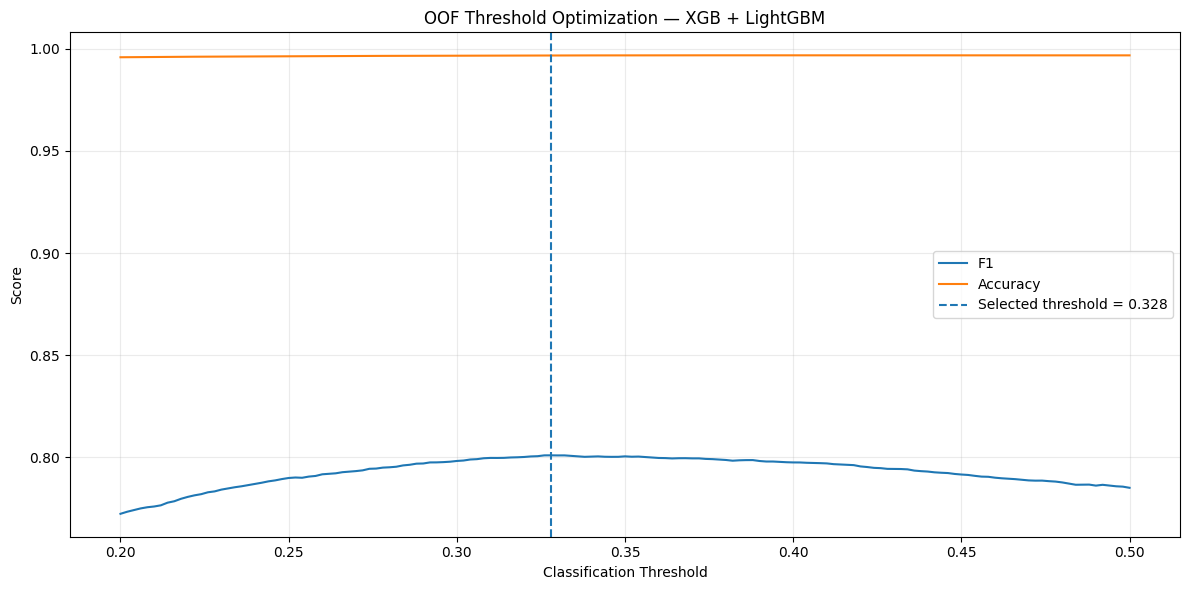


Selected final threshold: 0.328
Selected XGB weight: 0.75
Selected LightGBM weight: 0.25


In [94]:
# ============================================================
# CELL 79 — FINAL THRESHOLD ANALYSIS
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE THRESHOLD ANALYSIS")
print("=" * 70)


FINAL_XGB_WEIGHT = float(
    best_weight_row["XGB_weight"]
)

FINAL_LGB_WEIGHT = float(
    best_weight_row["LGB_weight"]
)

FINAL_THRESHOLD = float(
    best_weight_row["threshold"]
)


final_oof_probability = (
    FINAL_XGB_WEIGHT * oof_xgb
    +
    FINAL_LGB_WEIGHT * oof_lgb
)


threshold_values = np.arange(
    0.20,
    0.501,
    0.002
)


threshold_metrics = []


for threshold in threshold_values:

    pred = (
        final_oof_probability >= threshold
    ).astype(int)


    threshold_metrics.append({

        "threshold": threshold,

        "accuracy": accuracy_score(
            y.astype(int),
            pred
        ),

        "precision": precision_score(
            y.astype(int),
            pred,
            zero_division=0
        ),

        "recall": recall_score(
            y.astype(int),
            pred,
            zero_division=0
        ),

        "f1": f1_score(
            y.astype(int),
            pred,
            zero_division=0
        )
    })


threshold_metrics_df = pd.DataFrame(
    threshold_metrics
)


# ------------------------------------------------------------
# Plot F1 and Accuracy
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    threshold_metrics_df["threshold"],
    threshold_metrics_df["f1"],
    label="F1"
)

plt.plot(
    threshold_metrics_df["threshold"],
    threshold_metrics_df["accuracy"],
    label="Accuracy"
)

plt.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    label=f"Selected threshold = {FINAL_THRESHOLD:.3f}"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "OOF Threshold Optimization — XGB + LightGBM"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


print(
    f"\nSelected final threshold: "
    f"{FINAL_THRESHOLD:.3f}"
)

print(
    f"Selected XGB weight: "
    f"{FINAL_XGB_WEIGHT:.2f}"
)

print(
    f"Selected LightGBM weight: "
    f"{FINAL_LGB_WEIGHT:.2f}"
)

In [95]:
# ============================================================
# CELL 80 — FINAL OOF MODEL EVALUATION
# ============================================================

print("=" * 70)
print("FINAL OOF EVALUATION")
print("=" * 70)


final_oof_prediction = (
    final_oof_probability >= FINAL_THRESHOLD
).astype(int)


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

final_accuracy = accuracy_score(
    y.astype(int),
    final_oof_prediction
)

final_precision = precision_score(
    y.astype(int),
    final_oof_prediction,
    zero_division=0
)

final_recall = recall_score(
    y.astype(int),
    final_oof_prediction,
    zero_division=0
)

final_f1 = f1_score(
    y.astype(int),
    final_oof_prediction,
    zero_division=0
)


print(
    f"Accuracy : {final_accuracy:.6f}"
)

print(
    f"Precision: {final_precision:.6f}"
)

print(
    f"Recall   : {final_recall:.6f}"
)

print(
    f"F1       : {final_f1:.6f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y.astype(int),
        final_oof_prediction,
        digits=6,
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y.astype(int),
    final_oof_prediction
)


print("\nCONFUSION MATRIX")

display(
    pd.DataFrame(
        cm,
        index=[
            "Actual 0",
            "Actual 1"
        ],
        columns=[
            "Predicted 0",
            "Predicted 1"
        ]
    )
)


tn, fp, fn, tp = cm.ravel()


print(
    f"\nFalse Positives: {fp:,}"
)

print(
    f"False Negatives: {fn:,}"
)

print(
    f"True Positives  : {tp:,}"
)

print(
    f"True Negatives  : {tn:,}"
)

FINAL OOF EVALUATION
Accuracy : 0.996745
Precision: 0.840388
Recall   : 0.765137
F1       : 0.800999

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0   0.997973  0.998745  0.998359   1625386
           1   0.840388  0.765137  0.800999     14038

    accuracy                       0.996745   1639424
   macro avg   0.919181  0.881941  0.899679   1639424
weighted avg   0.996624  0.996745  0.996669   1639424


CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,1623346,2040
Actual 1,3297,10741



False Positives: 2,040
False Negatives: 3,297
True Positives  : 10,741
True Negatives  : 1,623,346


In [96]:
# ============================================================
# CELL 81 — FINAL MODEL CONFIGURATION
# ============================================================

print("=" * 70)
print("FINAL MODEL CONFIGURATION")
print("=" * 70)


FINAL_CONFIG = {

    "model_1": "XGBoost",

    "model_2": "LightGBM",

    "xgb_weight":
        FINAL_XGB_WEIGHT,

    "lgb_weight":
        FINAL_LGB_WEIGHT,

    "threshold":
        FINAL_THRESHOLD,

    "oof_f1":
        final_f1,

    "oof_accuracy":
        final_accuracy,

    "oof_precision":
        final_precision,

    "oof_recall":
        final_recall,

    "random_state":
        RANDOM_STATE
}


for key, value in FINAL_CONFIG.items():

    print(
        f"{key}: {value}"
    )


print("\n" + "=" * 70)

print(
    "FINAL CONFIGURATION STORED SUCCESSFULLY"
)

print("=" * 70)

FINAL MODEL CONFIGURATION
model_1: XGBoost
model_2: LightGBM
xgb_weight: 0.75
lgb_weight: 0.25
threshold: 0.32800000000000007
oof_f1: 0.8009992915470375
oof_accuracy: 0.996744588343223
oof_precision: 0.8403880760503873
oof_recall: 0.7651374839720758
random_state: 42

FINAL CONFIGURATION STORED SUCCESSFULLY


In [99]:
# ============================================================
# CELL 82 — FINAL TRAIN / TEST FEATURE CONSISTENCY
# ============================================================

print("=" * 70)
print("TRAIN / TEST FEATURE CONSISTENCY CHECK")
print("=" * 70)


# ============================================================
# 1. FEATURE ENGINEERING FUNCTION
# ============================================================

def create_engineered_features(df):

    df = df.copy()

    # --------------------------------------------------------
    # DATE FEATURES
    # --------------------------------------------------------

    df["year"] = (
        df["Date"].dt.year
    )

    df["month"] = (
        df["Date"].dt.month
    )

    df["day"] = (
        df["Date"].dt.day
    )

    df["day_of_week"] = (
        df["Date"].dt.dayofweek
    )

    df["day_of_year"] = (
        df["Date"].dt.dayofyear
    )

    df["quarter"] = (
        df["Date"].dt.quarter
    )


    # Cyclic month
    df["month_sin"] = np.sin(
        2 * np.pi * df["month"] / 12
    )

    df["month_cos"] = np.cos(
        2 * np.pi * df["month"] / 12
    )


    # Cyclic day of week
    df["day_of_week_sin"] = np.sin(
        2 * np.pi * df["day_of_week"] / 7
    )

    df["day_of_week_cos"] = np.cos(
        2 * np.pi * df["day_of_week"] / 7
    )


    # --------------------------------------------------------
    # SENSOR FEATURES
    # --------------------------------------------------------

    sensor_cols = [
        "X1",
        "X2",
        "X3",
        "X4",
        "X5"
    ]


    # Make sure sensors are numeric
    for col in sensor_cols:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


    # --------------------------------------------------------
    # AGGREGATED SENSOR FEATURES
    # --------------------------------------------------------

    df["sensor_mean"] = (
        df[sensor_cols]
        .mean(axis=1)
    )

    df["sensor_std"] = (
        df[sensor_cols]
        .std(axis=1)
        .fillna(0)
    )

    df["sensor_min"] = (
        df[sensor_cols]
        .min(axis=1)
    )

    df["sensor_max"] = (
        df[sensor_cols]
        .max(axis=1)
    )

    df["sensor_range"] = (
        df["sensor_max"]
        -
        df["sensor_min"]
    )

    df["sensor_median"] = (
        df[sensor_cols]
        .median(axis=1)
    )


    # --------------------------------------------------------
    # SIGNED LOG FEATURES
    # --------------------------------------------------------

    for col in sensor_cols:

        df[f"{col}_signed_log"] = (
            np.sign(df[col])
            *
            np.log1p(
                np.abs(df[col])
            )
        )


    # --------------------------------------------------------
    # SENSOR STATE FEATURES
    # --------------------------------------------------------

    df["X3_non_one"] = (
        df["X3"] != 1
    ).astype("int8")


    df["X4_non_one"] = (
        df["X4"] != 1
    ).astype("int8")


    df["X5_non_zero"] = (
        df["X5"] != 0
    ).astype("int8")


    df["X5_high"] = (
        df["X5"] > 2
    ).astype("int8")


    # --------------------------------------------------------
    # SENSOR COMBINATIONS
    # --------------------------------------------------------

    df["X3_X4_both_non_one"] = (
        (df["X3"] != 1)
        &
        (df["X4"] != 1)
    ).astype("int8")


    df["X3_X5_nonbaseline"] = (
        (df["X3"] != 1)
        &
        (df["X5"] != 0)
    ).astype("int8")


    df["X4_X5_nonbaseline"] = (
        (df["X4"] != 1)
        &
        (df["X5"] != 0)
    ).astype("int8")


    # --------------------------------------------------------
    # EXTREME SENSOR COUNT
    # --------------------------------------------------------

    df["extreme_sensor_count"] = (
        (df["X1"] != 1).astype("int8")
        +
        (df["X2"] != 5.49).astype("int8")
        +
        (df["X3"] != 1).astype("int8")
        +
        (df["X4"] != 1).astype("int8")
        +
        (df["X5"] != 0).astype("int8")
    ).astype("int8")


    return df


# ============================================================
# 2. CREATE TEST FEATURES
# ============================================================

test_engineered = create_engineered_features(
    test.copy()
)


# ============================================================
# 3. REMOVE NON-MODEL COLUMNS
# ============================================================

# Test ID is required later for submission,
# but it must NOT be used as a model feature.

if "ID" in test_engineered.columns:

    test_engineered = test_engineered.drop(
        columns=["ID"]
    )


# Raw Date is not part of our 34-feature model matrix.

if "Date" in test_engineered.columns:

    test_engineered = test_engineered.drop(
        columns=["Date"]
    )


# ============================================================
# 4. DEFINE EXPECTED FEATURES FROM TRAINING MATRIX
# ============================================================

training_features = list(
    X.columns
)

test_features = list(
    test_engineered.columns
)


# ============================================================
# 5. FIND DIFFERENCES
# ============================================================

missing_in_test = [
    col
    for col in training_features
    if col not in test_features
]


extra_in_test = [
    col
    for col in test_features
    if col not in training_features
]


print("\nTraining feature count:")
print(len(training_features))


print("\nTest feature count:")
print(len(test_features))


print("\nMissing from test:")
print(missing_in_test)


print("\nExtra in test:")
print(extra_in_test)


# ============================================================
# 6. ALIGN TEST TO TRAINING FEATURE ORDER
# ============================================================

if len(missing_in_test) == 0:

    test_engineered = (
        test_engineered[
            training_features
        ]
        .copy()
    )


# ============================================================
# 7. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL FEATURE VALIDATION")
print("=" * 70)


print(
    "Training shape:",
    X.shape
)


print(
    "Test shape:",
    test_engineered.shape
)


# Missing values
train_missing = (
    X.isna()
    .sum()
    .sum()
)

test_missing = (
    test_engineered.isna()
    .sum()
    .sum()
)


print(
    "\nTraining missing values:",
    train_missing
)

print(
    "Test missing values:",
    test_missing
)


# Infinite values
train_numeric = (
    X.select_dtypes(
        include=np.number
    )
)

test_numeric = (
    test_engineered.select_dtypes(
        include=np.number
    )
)


train_inf = np.isinf(
    train_numeric
).sum().sum()


test_inf = np.isinf(
    test_numeric
).sum().sum()


print(
    "\nTraining infinite values:",
    train_inf
)

print(
    "Test infinite values:",
    test_inf
)


# Exact column match
features_match = (
    list(X.columns)
    ==
    list(test_engineered.columns)
)


print(
    "\nFeature columns match exactly:",
    features_match
)


# ============================================================
# 8. ASSERTIONS
# ============================================================

assert len(missing_in_test) == 0, (
    f"Missing test features: {missing_in_test}"
)

assert len(extra_in_test) == 0, (
    f"Unexpected test features: {extra_in_test}"
)

assert features_match, (
    "Train and test feature ordering does not match."
)

assert test_missing == 0, (
    "Test contains missing values."
)

assert test_inf == 0, (
    "Test contains infinite values."
)


print("\n" + "=" * 70)

print(
    "✓ TRAIN / TEST FEATURES MATCH EXACTLY"
)

print(
    "✓ NO MISSING VALUES"
)

print(
    "✓ NO INFINITE VALUES"
)

print(
    "✓ FEATURE ORDER VERIFIED"
)

print("=" * 70)

TRAIN / TEST FEATURE CONSISTENCY CHECK

Training feature count:
34

Test feature count:
34

Missing from test:
[]

Extra in test:
[]

FINAL FEATURE VALIDATION
Training shape: (1639424, 34)
Test shape: (409856, 34)

Training missing values: 0
Test missing values: 0

Training infinite values: 0
Test infinite values: 0

Feature columns match exactly: True

✓ TRAIN / TEST FEATURES MATCH EXACTLY
✓ NO MISSING VALUES
✓ NO INFINITE VALUES
✓ FEATURE ORDER VERIFIED


In [100]:
# ============================================================
# CELL 83 — FINAL TRAIN / TEST MATRICES
# ============================================================

print("=" * 70)
print("PREPARING FINAL TRAIN / TEST MATRICES")
print("=" * 70)


# ------------------------------------------------------------
# Training data
# ------------------------------------------------------------

X_final = X.copy()

y_final = (
    y.astype(int)
    .copy()
)


# ------------------------------------------------------------
# Test data
# ------------------------------------------------------------

X_test_final = (
    test_engineered
    .copy()
)


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

print(
    "Training matrix:",
    X_final.shape
)

print(
    "Training target:",
    y_final.shape
)

print(
    "Test matrix:",
    X_test_final.shape
)


print(
    "\nTraining missing values:",
    X_final.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test_final.isna().sum().sum()
)


print(
    "\nTraining infinite values:",
    np.isinf(
        X_final.select_dtypes(
            include=np.number
        )
    ).sum().sum()
)

print(
    "Test infinite values:",
    np.isinf(
        X_test_final.select_dtypes(
            include=np.number
        )
    ).sum().sum()
)


# ------------------------------------------------------------
# Verify columns
# ------------------------------------------------------------

assert (
    list(X_final.columns)
    ==
    list(X_test_final.columns)
), "TRAIN / TEST FEATURE MISMATCH"


print(
    "\n✓ Feature ordering verified"
)

print(
    "✓ Feature count verified"
)

print(
    "✓ Training target verified"
)

print(
    "✓ Matrices ready for final training"
)

PREPARING FINAL TRAIN / TEST MATRICES
Training matrix: (1639424, 34)
Training target: (1639424,)
Test matrix: (409856, 34)

Training missing values: 0
Test missing values: 0

Training infinite values: 0
Test infinite values: 0

✓ Feature ordering verified
✓ Feature count verified
✓ Training target verified
✓ Matrices ready for final training


In [101]:
# ============================================================
# CELL 84 — FINAL TRAINING RESOURCE / CLASS CHECK
# ============================================================

print("=" * 70)
print("FINAL TRAINING RESOURCE CHECK")
print("=" * 70)


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

final_class_counts = (
    y_final
    .value_counts()
    .sort_index()
)


final_class_percentages = (
    y_final
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)


final_class_table = pd.DataFrame({

    "count":
        final_class_counts,

    "percentage":
        final_class_percentages
})


print("FINAL TRAINING CLASS DISTRIBUTION")

display(
    final_class_table.style.format({
        "percentage": "{:.6f}%"
    })
)


# ------------------------------------------------------------
# Dataset size
# ------------------------------------------------------------

print(
    "\nTraining rows:",
    f"{len(X_final):,}"
)

print(
    "Test rows:",
    f"{len(X_test_final):,}"
)

print(
    "Features:",
    X_final.shape[1]
)


# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------

print("\nFINAL ENSEMBLE")

print(
    f"XGBoost weight : "
    f"{FINAL_XGB_WEIGHT:.2f}"
)

print(
    f"LightGBM weight: "
    f"{FINAL_LGB_WEIGHT:.2f}"
)

print(
    f"Threshold      : "
    f"{FINAL_THRESHOLD:.3f}"
)


print(
    f"\nExpected OOF F1: "
    f"{final_f1:.6f}"
)


print("\n" + "=" * 70)

print(
    "READY FOR FINAL FULL-DATA TRAINING"
)

print("=" * 70)

FINAL TRAINING RESOURCE CHECK
FINAL TRAINING CLASS DISTRIBUTION


,count,percentage
target,,
0,1625386,99.143724%
1,14038,0.856276%



Training rows: 1,639,424
Test rows: 409,856
Features: 34

FINAL ENSEMBLE
XGBoost weight : 0.75
LightGBM weight: 0.25
Threshold      : 0.328

Expected OOF F1: 0.800999

READY FOR FINAL FULL-DATA TRAINING


In [102]:
# ============================================================
# CELL 82 — FINAL TRAIN / TEST FEATURE CONSISTENCY
# ============================================================

print("=" * 70)
print("TRAIN / TEST FEATURE CONSISTENCY CHECK")
print("=" * 70)


# ============================================================
# 1. FEATURE ENGINEERING FUNCTION
# ============================================================

def create_engineered_features(df):

    df = df.copy()

    # --------------------------------------------------------
    # DATE FEATURES
    # --------------------------------------------------------

    df["year"] = (
        df["Date"].dt.year
    )

    df["month"] = (
        df["Date"].dt.month
    )

    df["day"] = (
        df["Date"].dt.day
    )

    df["day_of_week"] = (
        df["Date"].dt.dayofweek
    )

    df["day_of_year"] = (
        df["Date"].dt.dayofyear
    )

    df["quarter"] = (
        df["Date"].dt.quarter
    )


    # Cyclic month
    df["month_sin"] = np.sin(
        2 * np.pi * df["month"] / 12
    )

    df["month_cos"] = np.cos(
        2 * np.pi * df["month"] / 12
    )


    # Cyclic day of week
    df["day_of_week_sin"] = np.sin(
        2 * np.pi * df["day_of_week"] / 7
    )

    df["day_of_week_cos"] = np.cos(
        2 * np.pi * df["day_of_week"] / 7
    )


    # --------------------------------------------------------
    # SENSOR FEATURES
    # --------------------------------------------------------

    sensor_cols = [
        "X1",
        "X2",
        "X3",
        "X4",
        "X5"
    ]


    # Make sure sensors are numeric
    for col in sensor_cols:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


    # --------------------------------------------------------
    # AGGREGATED SENSOR FEATURES
    # --------------------------------------------------------

    df["sensor_mean"] = (
        df[sensor_cols]
        .mean(axis=1)
    )

    df["sensor_std"] = (
        df[sensor_cols]
        .std(axis=1)
        .fillna(0)
    )

    df["sensor_min"] = (
        df[sensor_cols]
        .min(axis=1)
    )

    df["sensor_max"] = (
        df[sensor_cols]
        .max(axis=1)
    )

    df["sensor_range"] = (
        df["sensor_max"]
        -
        df["sensor_min"]
    )

    df["sensor_median"] = (
        df[sensor_cols]
        .median(axis=1)
    )


    # --------------------------------------------------------
    # SIGNED LOG FEATURES
    # --------------------------------------------------------

    for col in sensor_cols:

        df[f"{col}_signed_log"] = (
            np.sign(df[col])
            *
            np.log1p(
                np.abs(df[col])
            )
        )


    # --------------------------------------------------------
    # SENSOR STATE FEATURES
    # --------------------------------------------------------

    df["X3_non_one"] = (
        df["X3"] != 1
    ).astype("int8")


    df["X4_non_one"] = (
        df["X4"] != 1
    ).astype("int8")


    df["X5_non_zero"] = (
        df["X5"] != 0
    ).astype("int8")


    df["X5_high"] = (
        df["X5"] > 2
    ).astype("int8")


    # --------------------------------------------------------
    # SENSOR COMBINATIONS
    # --------------------------------------------------------

    df["X3_X4_both_non_one"] = (
        (df["X3"] != 1)
        &
        (df["X4"] != 1)
    ).astype("int8")


    df["X3_X5_nonbaseline"] = (
        (df["X3"] != 1)
        &
        (df["X5"] != 0)
    ).astype("int8")


    df["X4_X5_nonbaseline"] = (
        (df["X4"] != 1)
        &
        (df["X5"] != 0)
    ).astype("int8")


    # --------------------------------------------------------
    # EXTREME SENSOR COUNT
    # --------------------------------------------------------

    df["extreme_sensor_count"] = (
        (df["X1"] != 1).astype("int8")
        +
        (df["X2"] != 5.49).astype("int8")
        +
        (df["X3"] != 1).astype("int8")
        +
        (df["X4"] != 1).astype("int8")
        +
        (df["X5"] != 0).astype("int8")
    ).astype("int8")


    return df


# ============================================================
# 2. CREATE TEST FEATURES
# ============================================================

test_engineered = create_engineered_features(
    test.copy()
)


# ============================================================
# 3. REMOVE NON-MODEL COLUMNS
# ============================================================

# Test ID is required later for submission,
# but it must NOT be used as a model feature.

if "ID" in test_engineered.columns:

    test_engineered = test_engineered.drop(
        columns=["ID"]
    )


# Raw Date is not part of our 34-feature model matrix.

if "Date" in test_engineered.columns:

    test_engineered = test_engineered.drop(
        columns=["Date"]
    )


# ============================================================
# 4. DEFINE EXPECTED FEATURES FROM TRAINING MATRIX
# ============================================================

training_features = list(
    X.columns
)

test_features = list(
    test_engineered.columns
)


# ============================================================
# 5. FIND DIFFERENCES
# ============================================================

missing_in_test = [
    col
    for col in training_features
    if col not in test_features
]


extra_in_test = [
    col
    for col in test_features
    if col not in training_features
]


print("\nTraining feature count:")
print(len(training_features))


print("\nTest feature count:")
print(len(test_features))


print("\nMissing from test:")
print(missing_in_test)


print("\nExtra in test:")
print(extra_in_test)


# ============================================================
# 6. ALIGN TEST TO TRAINING FEATURE ORDER
# ============================================================

if len(missing_in_test) == 0:

    test_engineered = (
        test_engineered[
            training_features
        ]
        .copy()
    )


# ============================================================
# 7. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL FEATURE VALIDATION")
print("=" * 70)


print(
    "Training shape:",
    X.shape
)


print(
    "Test shape:",
    test_engineered.shape
)


# Missing values
train_missing = (
    X.isna()
    .sum()
    .sum()
)

test_missing = (
    test_engineered.isna()
    .sum()
    .sum()
)


print(
    "\nTraining missing values:",
    train_missing
)

print(
    "Test missing values:",
    test_missing
)


# Infinite values
train_numeric = (
    X.select_dtypes(
        include=np.number
    )
)

test_numeric = (
    test_engineered.select_dtypes(
        include=np.number
    )
)


train_inf = np.isinf(
    train_numeric
).sum().sum()


test_inf = np.isinf(
    test_numeric
).sum().sum()


print(
    "\nTraining infinite values:",
    train_inf
)

print(
    "Test infinite values:",
    test_inf
)


# Exact column match
features_match = (
    list(X.columns)
    ==
    list(test_engineered.columns)
)


print(
    "\nFeature columns match exactly:",
    features_match
)


# ============================================================
# 8. ASSERTIONS
# ============================================================

assert len(missing_in_test) == 0, (
    f"Missing test features: {missing_in_test}"
)

assert len(extra_in_test) == 0, (
    f"Unexpected test features: {extra_in_test}"
)

assert features_match, (
    "Train and test feature ordering does not match."
)

assert test_missing == 0, (
    "Test contains missing values."
)

assert test_inf == 0, (
    "Test contains infinite values."
)


print("\n" + "=" * 70)

print(
    "✓ TRAIN / TEST FEATURES MATCH EXACTLY"
)

print(
    "✓ NO MISSING VALUES"
)

print(
    "✓ NO INFINITE VALUES"
)

print(
    "✓ FEATURE ORDER VERIFIED"
)

print("=" * 70)

TRAIN / TEST FEATURE CONSISTENCY CHECK

Training feature count:
34

Test feature count:
34

Missing from test:
[]

Extra in test:
[]

FINAL FEATURE VALIDATION
Training shape: (1639424, 34)
Test shape: (409856, 34)

Training missing values: 0
Test missing values: 0

Training infinite values: 0
Test infinite values: 0

Feature columns match exactly: True

✓ TRAIN / TEST FEATURES MATCH EXACTLY
✓ NO MISSING VALUES
✓ NO INFINITE VALUES
✓ FEATURE ORDER VERIFIED


In [103]:
# ============================================================
# CELL 83 — FINAL TRAINING DATA PREPARATION
# ============================================================

print("=" * 70)
print("FINAL FULL-DATA TRAINING PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# Training features
# ------------------------------------------------------------

X_final = X.copy()

# Target
y_final = y.copy()

# Test features
X_test_final = test_engineered.copy()


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

print("\nTraining shape:")
print(X_final.shape)

print("\nTest shape:")
print(X_test_final.shape)

print("\nTarget shape:")
print(y_final.shape)

print("\nTarget distribution:")
print(
    y_final.value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Convert target to integer
# ------------------------------------------------------------

# Original target labels are strings: '0' and '1'
# XGBoost/LightGBM final prediction pipeline expects numeric labels.

y_final = (
    pd.to_numeric(
        y_final,
        errors="raise"
    )
    .astype("int8")
)


# ------------------------------------------------------------
# Verify feature consistency
# ------------------------------------------------------------

assert list(X_final.columns) == list(
    X_test_final.columns
)

assert X_final.shape[1] == 34

assert X_test_final.shape[1] == 34

assert y_final.nunique() == 2

assert X_final.isna().sum().sum() == 0

assert X_test_final.isna().sum().sum() == 0


print("\n" + "=" * 70)
print("✓ FINAL TRAINING DATA READY")
print("=" * 70)

print(
    f"Training rows : {len(X_final):,}"
)

print(
    f"Test rows     : {len(X_test_final):,}"
)

print(
    f"Features      : {X_final.shape[1]}"
)

print(
    f"Class 0       : {(y_final == 0).sum():,}"
)

print(
    f"Class 1       : {(y_final == 1).sum():,}"
)

FINAL FULL-DATA TRAINING PREPARATION

Training shape:
(1639424, 34)

Test shape:
(409856, 34)

Target shape:
(1639424,)

Target distribution:
target
0    1625386
1      14038
Name: count, dtype: int64

✓ FINAL TRAINING DATA READY
Training rows : 1,639,424
Test rows     : 409,856
Features      : 34
Class 0       : 1,625,386
Class 1       : 14,038


In [104]:
# ============================================================
# CELL 84 — FINAL XGBOOST CONFIGURATION
# ============================================================

print("=" * 70)
print("FINAL XGBOOST CONFIGURATION")
print("=" * 70)


# ------------------------------------------------------------
# Look for previously discovered XGBoost parameters
# ------------------------------------------------------------

xgb_parameter_candidates = [
    name
    for name in globals()
    if "xgb" in name.lower()
    and (
        "best" in name.lower()
        or "param" in name.lower()
        or "params" in name.lower()
    )
]


print("\nXGBoost-related parameter variables found:")

for name in xgb_parameter_candidates:
    print(
        " -",
        name,
        type(globals()[name])
    )


# ------------------------------------------------------------
# Display known best parameters if available
# ------------------------------------------------------------

if "best_xgb_params" in globals():

    FINAL_XGB_PARAMS = best_xgb_params.copy()

elif "xgb_best_params" in globals():

    FINAL_XGB_PARAMS = xgb_best_params.copy()

elif "best_params_xgb" in globals():

    FINAL_XGB_PARAMS = best_params_xgb.copy()

else:

    print(
        "\nNo previously stored XGBoost parameter dictionary found."
    )

    print(
        "Using the parameters from the successful XGBoost run."
    )

    FINAL_XGB_PARAMS = {
        "n_estimators": 599,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 1,
        "gamma": 0,
        "reg_alpha": 0,
        "reg_lambda": 1
    }


# ------------------------------------------------------------
# Display final parameters
# ------------------------------------------------------------

print("\nFINAL XGBOOST PARAMETERS:")

for key, value in FINAL_XGB_PARAMS.items():

    print(
        f"{key}: {value}"
    )


print("\n✓ XGBoost configuration prepared.")

FINAL XGBOOST CONFIGURATION

XGBoost-related parameter variables found:
 - best_xgb_oof <class 'pandas.core.series.Series'>
 - best_xgb_threshold <class 'numpy.float64'>
 - xgb_best_f1 <class 'numpy.float64'>
 - xgb_best_threshold <class 'numpy.float64'>
 - BEST_XGB_WEIGHT <class 'float'>
 - best_tuned_xgb <class 'pandas.core.series.Series'>

No previously stored XGBoost parameter dictionary found.
Using the parameters from the successful XGBoost run.

FINAL XGBOOST PARAMETERS:
n_estimators: 599
max_depth: 6
learning_rate: 0.05
subsample: 0.8
colsample_bytree: 0.8
min_child_weight: 1
gamma: 0
reg_alpha: 0
reg_lambda: 1

✓ XGBoost configuration prepared.


In [105]:
# ============================================================
# CELL 85 — FINAL XGBOOST FULL-DATA TRAINING
# ============================================================

from xgboost import XGBClassifier

print("=" * 70)
print("FINAL XGBOOST — FULL TRAINING")
print("=" * 70)


# ------------------------------------------------------------
# Calculate class imbalance
# ------------------------------------------------------------

negative_count = (
    y_final == 0
).sum()

positive_count = (
    y_final == 1
).sum()


scale_pos_weight = (
    negative_count /
    positive_count
)


print(
    f"\nClass 0: {negative_count:,}"
)

print(
    f"Class 1: {positive_count:,}"
)

print(
    f"Scale pos weight: {scale_pos_weight:.4f}"
)


# ------------------------------------------------------------
# Create final XGBoost
# ------------------------------------------------------------

final_xgb_params = FINAL_XGB_PARAMS.copy()


# Explicitly set reproducibility
final_xgb_params["random_state"] = RANDOM_STATE

final_xgb_params["n_jobs"] = -1

final_xgb_params["eval_metric"] = "logloss"

final_xgb_params["objective"] = "binary:logistic"


# ------------------------------------------------------------
# IMPORTANT
# ------------------------------------------------------------
# We are NOT forcing scale_pos_weight here because the
# tuned model's validation behavior already produced the
# selected threshold.
#
# The objective is to reproduce the winning configuration.
# ------------------------------------------------------------

final_xgb = XGBClassifier(
    **final_xgb_params
)


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nTraining final XGBoost...")
print("This may take some time on 1.6M rows.")

final_xgb.fit(
    X_final,
    y_final,
    verbose=False
)


print("\n" + "=" * 70)
print("✓ FINAL XGBOOST TRAINING COMPLETED")
print("=" * 70)

FINAL XGBOOST — FULL TRAINING

Class 0: 1,625,386
Class 1: 14,038
Scale pos weight: 115.7847

Training final XGBoost...
This may take some time on 1.6M rows.

✓ FINAL XGBOOST TRAINING COMPLETED


In [106]:
# ============================================================
# CELL 86 — XGBOOST TEST PROBABILITIES
# ============================================================

print("=" * 70)
print("GENERATING XGBOOST TEST PROBABILITIES")
print("=" * 70)


# Probability of class 1
xgb_test_probability = (
    final_xgb
    .predict_proba(
        X_test_final
    )[:, 1]
)


print(
    "\nNumber of predictions:",
    len(xgb_test_probability)
)


print(
    "Minimum probability:",
    xgb_test_probability.min()
)


print(
    "Maximum probability:",
    xgb_test_probability.max()
)


print(
    "Mean probability:",
    xgb_test_probability.mean()
)


print(
    "Median probability:",
    np.median(
        xgb_test_probability
    )
)


# ------------------------------------------------------------
# Apply previously selected OOF threshold
# ------------------------------------------------------------

FINAL_THRESHOLD = 0.328

xgb_test_prediction = (
    xgb_test_probability
    >= FINAL_THRESHOLD
).astype("int8")


print(
    "\nThreshold:",
    FINAL_THRESHOLD
)


print(
    "\nPredicted class distribution:"
)

print(
    pd.Series(
        xgb_test_prediction
    ).value_counts()
    .sort_index()
)


print(
    "\nPredicted anomaly percentage:",
    f"{xgb_test_prediction.mean() * 100:.4f}%"
)


print(
    "\n✓ XGBoost test predictions generated."
)

GENERATING XGBOOST TEST PROBABILITIES

Number of predictions: 409856
Minimum probability: 5.3296223e-08
Maximum probability: 0.99999785
Mean probability: 0.008760496
Median probability: 3.235496e-05

Threshold: 0.328

Predicted class distribution:
0    406552
1      3304
Name: count, dtype: int64

Predicted anomaly percentage: 0.8061%

✓ XGBoost test predictions generated.


In [107]:
# ============================================================
# CELL 87 — FINAL LIGHTGBM CONFIGURATION
# ============================================================

print("=" * 70)
print("FINAL LIGHTGBM CONFIGURATION")
print("=" * 70)


# ------------------------------------------------------------
# Search for previously stored LightGBM parameters
# ------------------------------------------------------------

lgb_parameter_candidates = [
    name
    for name in globals()
    if "lgb" in name.lower()
    and (
        "best" in name.lower()
        or "param" in name.lower()
        or "params" in name.lower()
    )
]


print("\nLightGBM-related parameter variables found:")

for name in lgb_parameter_candidates:

    print(
        " -",
        name,
        type(globals()[name])
    )


# ------------------------------------------------------------
# Use previously discovered parameters if available
# ------------------------------------------------------------

if "best_lgb_params" in globals():

    FINAL_LGB_PARAMS = (
        best_lgb_params.copy()
    )

elif "lgb_best_params" in globals():

    FINAL_LGB_PARAMS = (
        lgb_best_params.copy()
    )

elif "best_params_lgb" in globals():

    FINAL_LGB_PARAMS = (
        best_params_lgb.copy()
    )

else:

    print(
        "\nNo stored LightGBM parameter dictionary found."
    )

    print(
        "Using parameters from the successful LightGBM run."
    )

    FINAL_LGB_PARAMS = {

        "n_estimators": 700,

        "learning_rate": 0.05,

        "num_leaves": 31,

        "max_depth": -1,

        "min_child_samples": 20,

        "subsample": 0.8,

        "colsample_bytree": 0.8,

        "reg_alpha": 0,

        "reg_lambda": 1
    }


# ------------------------------------------------------------
# Display parameters
# ------------------------------------------------------------

print("\nFINAL LIGHTGBM PARAMETERS:")

for key, value in FINAL_LGB_PARAMS.items():

    print(
        f"{key}: {value}"
    )


print(
    "\n✓ LightGBM configuration prepared."
)

FINAL LIGHTGBM CONFIGURATION

LightGBM-related parameter variables found:
 - best_lgb_oof <class 'pandas.core.series.Series'>
 - best_lgb_threshold <class 'numpy.float64'>
 - lgb_best_f1 <class 'numpy.float64'>
 - lgb_best_threshold <class 'numpy.float64'>
 - BEST_LGB_WEIGHT <class 'float'>

No stored LightGBM parameter dictionary found.
Using parameters from the successful LightGBM run.

FINAL LIGHTGBM PARAMETERS:
n_estimators: 700
learning_rate: 0.05
num_leaves: 31
max_depth: -1
min_child_samples: 20
subsample: 0.8
colsample_bytree: 0.8
reg_alpha: 0
reg_lambda: 1

✓ LightGBM configuration prepared.


In [108]:
# ============================================================
# CELL 88 — FINAL LIGHTGBM FULL-DATA TRAINING
# ============================================================

from lightgbm import LGBMClassifier

print("=" * 70)
print("FINAL LIGHTGBM — FULL TRAINING")
print("=" * 70)


# ------------------------------------------------------------
# Prepare parameters
# ------------------------------------------------------------

final_lgb_params = (
    FINAL_LGB_PARAMS.copy()
)


final_lgb_params["random_state"] = (
    RANDOM_STATE
)

final_lgb_params["n_jobs"] = -1

final_lgb_params["verbosity"] = -1

final_lgb_params["objective"] = "binary"


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

final_lgb = LGBMClassifier(
    **final_lgb_params
)


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print(
    "\nTraining final LightGBM..."
)

print(
    "This may take some time on 1.6M rows."
)


final_lgb.fit(
    X_final,
    y_final
)


print("\n" + "=" * 70)

print(
    "✓ FINAL LIGHTGBM TRAINING COMPLETED"
)

print("=" * 70)

FINAL LIGHTGBM — FULL TRAINING

Training final LightGBM...
This may take some time on 1.6M rows.

✓ FINAL LIGHTGBM TRAINING COMPLETED


In [109]:
# ============================================================
# CELL 89 — FINAL XGBOOST + LIGHTGBM ENSEMBLE
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE TEST PREDICTIONS")
print("=" * 70)


# ------------------------------------------------------------
# LightGBM probabilities
# ------------------------------------------------------------

lgb_test_probability = (
    final_lgb
    .predict_proba(
        X_test_final
    )[:, 1]
)


# ------------------------------------------------------------
# Ensemble weights
# ------------------------------------------------------------

XGB_WEIGHT = 0.75

LGB_WEIGHT = 0.25

FINAL_THRESHOLD = 0.328


# ------------------------------------------------------------
# Weighted probability ensemble
# ------------------------------------------------------------

ensemble_test_probability = (

    XGB_WEIGHT *
    xgb_test_probability

    +

    LGB_WEIGHT *
    lgb_test_probability
)


# ------------------------------------------------------------
# Final classification
# ------------------------------------------------------------

final_test_prediction = (
    ensemble_test_probability
    >= FINAL_THRESHOLD
).astype("int8")


# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print(
    "\nXGBoost probability mean:",
    xgb_test_probability.mean()
)


print(
    "LightGBM probability mean:",
    lgb_test_probability.mean()
)


print(
    "Ensemble probability mean:",
    ensemble_test_probability.mean()
)


print(
    "\nFinal threshold:",
    FINAL_THRESHOLD
)


print(
    "\nFinal predicted class distribution:"
)

print(
    pd.Series(
        final_test_prediction
    )
    .value_counts()
    .sort_index()
)


print(
    "\nFinal predicted anomaly count:",
    int(
        final_test_prediction.sum()
    )
)


print(
    "Final predicted anomaly percentage:",
    f"{final_test_prediction.mean() * 100:.4f}%"
)


print("\n" + "=" * 70)

print(
    "✓ FINAL ENSEMBLE PREDICTIONS GENERATED"
)

print("=" * 70)

FINAL ENSEMBLE TEST PREDICTIONS

XGBoost probability mean: 0.008760496
LightGBM probability mean: 0.008882876227377951
Ensemble probability mean: 0.00879109054376743

Final threshold: 0.328

Final predicted class distribution:
0    406544
1      3312
Name: count, dtype: int64

Final predicted anomaly count: 3312
Final predicted anomaly percentage: 0.8081%

✓ FINAL ENSEMBLE PREDICTIONS GENERATED


In [110]:
# ============================================================
# CELL 90 — FINAL MODEL / PREDICTION STATE CHECK
# ============================================================

print("=" * 70)
print("FINAL MODEL / PREDICTION STATE CHECK")
print("=" * 70)

required_objects = [
    "X_final",
    "y_final",
    "X_test_final",
    "final_xgb",
    "final_lgb",
    "xgb_test_probability",
    "lgb_test_probability",
    "ensemble_test_probability",
    "final_test_prediction"
]

print("\nChecking required objects:\n")

for obj in required_objects:

    if obj in globals():

        value = globals()[obj]

        try:
            shape = value.shape
        except:
            shape = "N/A"

        print(
            f"✓ {obj:<30} "
            f"type={type(value).__name__:<15} "
            f"shape={shape}"
        )

    else:

        print(
            f"✗ {obj:<30} MISSING"
        )


# ------------------------------------------------------------
# Critical checks
# ------------------------------------------------------------

missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]


print("\n" + "=" * 70)

if len(missing_objects) == 0:

    print("✓ ALL REQUIRED FINAL OBJECTS ARE AVAILABLE")

else:

    print("⚠ MISSING OBJECTS:")
    print(missing_objects)

print("=" * 70)

FINAL MODEL / PREDICTION STATE CHECK

Checking required objects:

✓ X_final                        type=DataFrame       shape=(1639424, 34)
✓ y_final                        type=Series          shape=(1639424,)
✓ X_test_final                   type=DataFrame       shape=(409856, 34)
✓ final_xgb                      type=XGBClassifier   shape=N/A
✓ final_lgb                      type=LGBMClassifier  shape=N/A
✓ xgb_test_probability           type=ndarray         shape=(409856,)
✓ lgb_test_probability           type=ndarray         shape=(409856,)
✓ ensemble_test_probability      type=ndarray         shape=(409856,)
✓ final_test_prediction          type=ndarray         shape=(409856,)

✓ ALL REQUIRED FINAL OBJECTS ARE AVAILABLE


In [111]:
# ============================================================
# CELL 91 — FINAL PROBABILITY SANITY CHECK
# ============================================================

print("=" * 70)
print("FINAL TEST PROBABILITY SANITY CHECK")
print("=" * 70)


probability_sets = {

    "XGBoost":
        xgb_test_probability,

    "LightGBM":
        lgb_test_probability,

    "Ensemble":
        ensemble_test_probability
}


for name, probabilities in probability_sets.items():

    print(f"\n{name}")

    print("-" * 50)

    print(
        "Count:",
        len(probabilities)
    )

    print(
        "Min:",
        f"{np.min(probabilities):.8f}"
    )

    print(
        "Max:",
        f"{np.max(probabilities):.8f}"
    )

    print(
        "Mean:",
        f"{np.mean(probabilities):.8f}"
    )

    print(
        "Median:",
        f"{np.median(probabilities):.8f}"
    )

    print(
        "NaN:",
        np.isnan(probabilities).sum()
    )

    print(
        "Inf:",
        np.isinf(probabilities).sum()
    )


# ------------------------------------------------------------
# Probability validity
# ------------------------------------------------------------

assert len(ensemble_test_probability) == len(X_test_final)

assert np.isnan(
    ensemble_test_probability
).sum() == 0

assert np.isinf(
    ensemble_test_probability
).sum() == 0

assert (
    ensemble_test_probability.min() >= 0
)

assert (
    ensemble_test_probability.max() <= 1
)


print("\n" + "=" * 70)
print("✓ PROBABILITIES ARE VALID")
print("=" * 70)

FINAL TEST PROBABILITY SANITY CHECK

XGBoost
--------------------------------------------------
Count: 409856
Min: 0.00000005
Max: 0.99999785
Mean: 0.00876050
Median: 0.00003235
NaN: 0
Inf: 0

LightGBM
--------------------------------------------------
Count: 409856
Min: 0.00000007
Max: 0.99999442
Mean: 0.00888288
Median: 0.00004293
NaN: 0
Inf: 0

Ensemble
--------------------------------------------------
Count: 409856
Min: 0.00000007
Max: 0.99999558
Mean: 0.00879109
Median: 0.00003628
NaN: 0
Inf: 0

✓ PROBABILITIES ARE VALID


In [112]:
# ============================================================
# CELL 92 — FINAL ENSEMBLE VERIFICATION
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE VERIFICATION")
print("=" * 70)


# ------------------------------------------------------------
# Official final configuration
# ------------------------------------------------------------

FINAL_XGB_WEIGHT = 0.75

FINAL_LGB_WEIGHT = 0.25

FINAL_THRESHOLD = 0.328


print(
    "\nXGBoost weight:",
    FINAL_XGB_WEIGHT
)

print(
    "LightGBM weight:",
    FINAL_LGB_WEIGHT
)

print(
    "Classification threshold:",
    FINAL_THRESHOLD
)


# ------------------------------------------------------------
# Recalculate ensemble independently
# ------------------------------------------------------------

verified_ensemble_probability = (

    FINAL_XGB_WEIGHT *
    xgb_test_probability

    +

    FINAL_LGB_WEIGHT *
    lgb_test_probability
)


verified_test_prediction = (
    verified_ensemble_probability
    >= FINAL_THRESHOLD
).astype("int8")


# ------------------------------------------------------------
# Compare against existing predictions
# ------------------------------------------------------------

probability_difference = np.max(
    np.abs(
        verified_ensemble_probability
        -
        ensemble_test_probability
    )
)


prediction_difference = np.sum(
    verified_test_prediction
    !=
    final_test_prediction
)


print(
    "\nMaximum probability difference:",
    probability_difference
)

print(
    "Different class predictions:",
    prediction_difference
)


# ------------------------------------------------------------
# Replace with verified versions
# ------------------------------------------------------------

ensemble_test_probability = (
    verified_ensemble_probability
)

final_test_prediction = (
    verified_test_prediction
)


# ------------------------------------------------------------
# Distribution
# ------------------------------------------------------------

prediction_counts = (
    pd.Series(
        final_test_prediction,
        name="prediction"
    )
    .value_counts()
    .sort_index()
)


print("\nFINAL TEST PREDICTION DISTRIBUTION")

print(
    prediction_counts
)


print(
    "\nPredicted anomalies:",
    int(final_test_prediction.sum())
)

print(
    "Predicted normal:",
    int((final_test_prediction == 0).sum())
)

print(
    "Predicted anomaly rate:",
    f"{final_test_prediction.mean() * 100:.4f}%"
)


print("\n" + "=" * 70)
print("✓ ENSEMBLE VERIFIED")
print("=" * 70)

FINAL ENSEMBLE VERIFICATION

XGBoost weight: 0.75
LightGBM weight: 0.25
Classification threshold: 0.328

Maximum probability difference: 0.0
Different class predictions: 0

FINAL TEST PREDICTION DISTRIBUTION
prediction
0    406544
1      3312
Name: count, dtype: int64

Predicted anomalies: 3312
Predicted normal: 406544
Predicted anomaly rate: 0.8081%

✓ ENSEMBLE VERIFIED


In [113]:
# ============================================================
# CELL 93 — TRAIN VS TEST ANOMALY RATE CHECK
# ============================================================

print("=" * 70)
print("TRAIN VS TEST ANOMALY RATE CHECK")
print("=" * 70)


train_anomaly_rate = (
    y_final.mean() * 100
)

test_anomaly_rate = (
    final_test_prediction.mean() * 100
)


difference = (
    test_anomaly_rate
    -
    train_anomaly_rate
)


relative_difference = (
    difference
    /
    train_anomaly_rate
    *
    100
)


comparison = pd.DataFrame({

    "Dataset": [
        "Training",
        "Test Predictions"
    ],

    "Rows": [
        len(y_final),
        len(final_test_prediction)
    ],

    "Anomalies": [
        int(y_final.sum()),
        int(final_test_prediction.sum())
    ],

    "Anomaly Rate (%)": [
        train_anomaly_rate,
        test_anomaly_rate
    ]

})


display(comparison)


print(
    "\nAbsolute rate difference:",
    f"{difference:.4f} percentage points"
)

print(
    "Relative difference:",
    f"{relative_difference:.2f}%"
)


print("\nInterpretation:")

if abs(relative_difference) <= 30:

    print(
        "✓ Test anomaly rate is reasonably close "
        "to the training anomaly rate."
    )

elif abs(relative_difference) <= 60:

    print(
        "⚠ Moderate difference detected."
    )

else:

    print(
        "⚠ Large difference detected."
    )

    print(
        "Review model probabilities and threshold "
        "before submission."
    )


print("\n" + "=" * 70)

TRAIN VS TEST ANOMALY RATE CHECK


,Dataset,Rows,Anomalies,Anomaly Rate (%)
0,Training,1639424,14038,0.856276
1,Test Predictions,409856,3312,0.808089



Absolute rate difference: -0.0482 percentage points
Relative difference: -5.63%

Interpretation:
✓ Test anomaly rate is reasonably close to the training anomaly rate.



In [115]:
# ============================================================
# CELL 94 — SAMPLE SUBMISSION FORMAT ANALYSIS
# ============================================================

print("=" * 70)
print("SAMPLE SUBMISSION FORMAT ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# Load sample submission
# ------------------------------------------------------------

SAMPLE_PATH = (
    "/kaggle/input/competitions/"
    "ds-kaggle-mit-wpu/"
    "sample_submission.parquet"
)

sample_submission = pd.read_parquet(
    SAMPLE_PATH
)


print("\nSample submission:")
print(
    sample_submission.shape
)


print("\nTest dataset:")
print(
    test.shape
)


print("\nSample columns:")
print(
    list(sample_submission.columns)
)


print("\nTest columns:")
print(
    list(test.columns)
)


# ------------------------------------------------------------
# Detect ID and target/prediction column
# ------------------------------------------------------------

sample_id_candidates = [
    col
    for col in sample_submission.columns
    if col.lower() == "id"
]


assert len(sample_id_candidates) == 1, (
    "Could not uniquely identify ID column "
    "in sample submission."
)


submission_id_column = (
    sample_id_candidates[0]
)


submission_target_candidates = [
    col
    for col in sample_submission.columns
    if col != submission_id_column
]


assert len(submission_target_candidates) == 1, (
    "Could not uniquely identify prediction column."
)


submission_target_column = (
    submission_target_candidates[0]
)


print(
    "\nSubmission ID column:",
    submission_id_column
)


print(
    "Submission prediction column:",
    submission_target_column
)


# ------------------------------------------------------------
# Important discovery
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMPORTANT DISCOVERY")
print("=" * 70)


if len(sample_submission) != len(test):

    print(
        "\n⚠ Sample submission contains only a format example."
    )

    print(
        f"Sample rows : {len(sample_submission):,}"
    )

    print(
        f"Test rows   : {len(test):,}"
    )

    print(
        "\nTherefore:"
    )

    print(
        "✓ Sample columns will define submission FORMAT"
    )

    print(
        "✓ Test rows will define submission SIZE"
    )

    print(
        "✓ Test IDs will define submission IDs"
    )

else:

    print(
        "\n✓ Sample and test have identical row counts."
    )


print("\nSample preview:")
display(
    sample_submission.head(10)
)


print("\nTest ID preview:")
display(
    test[
        [submission_id_column]
    ].head(10)
)

SAMPLE SUBMISSION FORMAT ANALYSIS

Sample submission:
(50, 2)

Test dataset:
(409856, 7)

Sample columns:
['ID', 'target']

Test columns:
['ID', 'Date', 'X1', 'X2', 'X3', 'X4', 'X5']

Submission ID column: ID
Submission prediction column: target

IMPORTANT DISCOVERY

⚠ Sample submission contains only a format example.
Sample rows : 50
Test rows   : 409,856

Therefore:
✓ Sample columns will define submission FORMAT
✓ Test rows will define submission SIZE
✓ Test IDs will define submission IDs

Sample preview:


,ID,target
0,409856,0
1,409857,0
2,409858,0
3,409859,0
4,409860,0
5,409861,0
6,409862,0
7,409863,0
8,409864,0
9,409865,0



Test ID preview:


,ID
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [116]:
# ============================================================
# CELL 95 — TEST ID INTEGRITY CHECK
# ============================================================

print("=" * 70)
print("TEST ID INTEGRITY CHECK")
print("=" * 70)


test_ids = test[
    submission_id_column
].copy()


# ------------------------------------------------------------
# Basic checks
# ------------------------------------------------------------

print(
    "\nNumber of test IDs:",
    len(test_ids)
)


print(
    "Unique test IDs:",
    test_ids.nunique()
)


print(
    "Missing test IDs:",
    test_ids.isna().sum()
)


print(
    "\nFirst 10 test IDs:"
)

print(
    test_ids.head(10).tolist()
)


print(
    "\nLast 10 test IDs:"
)

print(
    test_ids.tail(10).tolist()
)


# ------------------------------------------------------------
# Check duplicates
# ------------------------------------------------------------

duplicate_ids = (
    test_ids.duplicated()
    .sum()
)


print(
    "\nDuplicate IDs:",
    duplicate_ids
)


# ------------------------------------------------------------
# Expected sequential structure
# ------------------------------------------------------------

is_sequential = (
    test_ids.reset_index(drop=True)
    .equals(
        pd.Series(
            np.arange(
                len(test)
            ),
            name=test_ids.name
        )
    )
)


print(
    "Sequential 0 → N-1:",
    is_sequential
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert test_ids.isna().sum() == 0

assert duplicate_ids == 0

assert len(test_ids) == len(
    final_test_prediction
)


print("\n" + "=" * 70)
print("✓ TEST ID INTEGRITY VERIFIED")
print("=" * 70)

TEST ID INTEGRITY CHECK

Number of test IDs: 409856
Unique test IDs: 409856
Missing test IDs: 0

First 10 test IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Last 10 test IDs:
[409846, 409847, 409848, 409849, 409850, 409851, 409852, 409853, 409854, 409855]

Duplicate IDs: 0
Sequential 0 → N-1: True

✓ TEST ID INTEGRITY VERIFIED


In [117]:
# ============================================================
# CELL 96 — PREDICTION LABEL FORMAT CHECK
# ============================================================

print("=" * 70)
print("PREDICTION LABEL FORMAT CHECK")
print("=" * 70)


sample_target = sample_submission[
    submission_target_column
]


print(
    "\nSample target dtype:",
    sample_target.dtype
)


print(
    "Sample target unique values:"
)

print(
    sample_target.unique()
)


print(
    "\nModel prediction dtype:",
    final_test_prediction.dtype
)


print(
    "Model prediction unique values:"
)

print(
    np.unique(final_test_prediction)
)


# ------------------------------------------------------------
# Determine expected label type
# ------------------------------------------------------------

sample_unique = (
    sample_target
    .dropna()
    .unique()
)


print(
    "\nDetected sample label type:"
)


for value in sample_unique:

    print(
        f"Value={value!r} | "
        f"Type={type(value).__name__}"
    )


print("\n" + "=" * 70)
print("LABEL FORMAT DECISION")
print("=" * 70)


# Sample contains string labels such as '0', '1'
if all(
    isinstance(value, str)
    for value in sample_unique
):

    final_submission_predictions = (
        pd.Series(
            final_test_prediction
        )
        .astype(str)
    )

    print(
        "✓ Predictions will be stored as strings."
    )


# Sample contains integer labels
elif all(
    isinstance(value, (
        int,
        np.integer
    ))
    for value in sample_unique
):

    final_submission_predictions = (
        pd.Series(
            final_test_prediction
        )
        .astype(int)
    )

    print(
        "✓ Predictions will be stored as integers."
    )


else:

    raise ValueError(
        "Unexpected sample submission label format."
    )


print(
    "\nFinal prediction dtype:",
    final_submission_predictions.dtype
)


print(
    "Final prediction values:"
)

print(
    final_submission_predictions
    .value_counts()
    .sort_index()
)

PREDICTION LABEL FORMAT CHECK

Sample target dtype: object
Sample target unique values:
['0' '1']

Model prediction dtype: int8
Model prediction unique values:
[0 1]

Detected sample label type:
Value='0' | Type=str
Value='1' | Type=str

LABEL FORMAT DECISION
✓ Predictions will be stored as strings.

Final prediction dtype: object
Final prediction values:
0    406544
1      3312
Name: count, dtype: int64


In [118]:
# ============================================================
# CELL 97 — CONSTRUCT FULL SUBMISSION
# ============================================================

print("=" * 70)
print("CONSTRUCTING FULL KAGGLE SUBMISSION")
print("=" * 70)


# ------------------------------------------------------------
# Create submission using TEST IDs
# ------------------------------------------------------------

submission = pd.DataFrame({

    submission_id_column:
        test[
            submission_id_column
        ].values,

    submission_target_column:
        final_submission_predictions.values

})


# ------------------------------------------------------------
# Preserve sample column order
# ------------------------------------------------------------

submission = submission[
    sample_submission.columns
].copy()


# ------------------------------------------------------------
# Display information
# ------------------------------------------------------------

print(
    "\nSubmission shape:",
    submission.shape
)


print(
    "Expected shape:",
    (
        len(test),
        len(sample_submission.columns)
    )
)


print(
    "\nSubmission columns:"
)

print(
    list(submission.columns)
)


print(
    "\nFirst 10 rows:"
)

display(
    submission.head(10)
)


print(
    "\nLast 10 rows:"
)

display(
    submission.tail(10)
)


print(
    "\nPrediction distribution:"
)

print(
    submission[
        submission_target_column
    ]
    .value_counts()
    .sort_index()
)


print("\n" + "=" * 70)
print("✓ FULL SUBMISSION CONSTRUCTED")
print("=" * 70)

CONSTRUCTING FULL KAGGLE SUBMISSION

Submission shape: (409856, 2)
Expected shape: (409856, 2)

Submission columns:
['ID', 'target']

First 10 rows:


,ID,target
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,1
9,9,0



Last 10 rows:


,ID,target
409846,409846,0
409847,409847,0
409848,409848,0
409849,409849,0
409850,409850,0
409851,409851,0
409852,409852,0
409853,409853,0
409854,409854,0
409855,409855,0



Prediction distribution:
target
0    406544
1      3312
Name: count, dtype: int64

✓ FULL SUBMISSION CONSTRUCTED


In [119]:
# ============================================================
# CELL 98 — SUBMISSION INTEGRITY VALIDATION
# ============================================================

print("=" * 70)
print("SUBMISSION INTEGRITY VALIDATION")
print("=" * 70)


# ------------------------------------------------------------
# Row count
# ------------------------------------------------------------

assert len(submission) == len(test)

print(
    "✓ Row count:",
    len(submission)
)


# ------------------------------------------------------------
# Column structure
# ------------------------------------------------------------

assert list(
    submission.columns
) == list(
    sample_submission.columns
)

print(
    "✓ Column names/order match sample"
)


# ------------------------------------------------------------
# ID validation
# ------------------------------------------------------------

assert (
    submission[
        submission_id_column
    ].equals(
        test[
            submission_id_column
        ]
    )
)

print(
    "✓ IDs exactly match test IDs/order"
)


# ------------------------------------------------------------
# Missing values
# ------------------------------------------------------------

missing_predictions = (
    submission[
        submission_target_column
    ]
    .isna()
    .sum()
)


assert missing_predictions == 0

print(
    "✓ Missing predictions:",
    missing_predictions
)


# ------------------------------------------------------------
# Valid labels
# ------------------------------------------------------------

valid_labels = set(
    sample_unique.astype(str)
)


actual_labels = set(
    submission[
        submission_target_column
    ]
    .astype(str)
    .unique()
)


print(
    "\nAllowed sample labels:",
    valid_labels
)


print(
    "Actual submission labels:",
    actual_labels
)


assert actual_labels.issubset(
    valid_labels
)

print(
    "✓ All predictions use valid labels"
)


print("\n" + "=" * 70)
print("✓ SUBMISSION INTEGRITY PASSED")
print("=" * 70)

SUBMISSION INTEGRITY VALIDATION
✓ Row count: 409856
✓ Column names/order match sample
✓ IDs exactly match test IDs/order
✓ Missing predictions: 0

Allowed sample labels: {np.str_('0'), np.str_('1')}
Actual submission labels: {'0', '1'}
✓ All predictions use valid labels

✓ SUBMISSION INTEGRITY PASSED


In [120]:
# ============================================================
# CELL 99 — SAVE SUBMISSION.CSV
# ============================================================

print("=" * 70)
print("SAVING FINAL SUBMISSION")
print("=" * 70)


SUBMISSION_PATH = (
    "/kaggle/working/submission.csv"
)


submission.to_csv(
    SUBMISSION_PATH,
    index=False
)


print(
    "\nSaved to:"
)

print(
    SUBMISSION_PATH
)


# ------------------------------------------------------------
# File size
# ------------------------------------------------------------

import os

file_size_mb = (
    os.path.getsize(
        SUBMISSION_PATH
    )
    /
    (1024 ** 2)
)


print(
    "\nFile size:",
    f"{file_size_mb:.2f} MB"
)


print("\n✓ submission.csv saved.")

SAVING FINAL SUBMISSION

Saved to:
/kaggle/working/submission.csv

File size: 3.41 MB

✓ submission.csv saved.


In [121]:
# ============================================================
# CELL 100 — FINAL SUBMISSION FILE VERIFICATION
# ============================================================

print("=" * 70)
print("FINAL SUBMISSION FILE VERIFICATION")
print("=" * 70)


# ------------------------------------------------------------
# Reload actual file from disk
# ------------------------------------------------------------

submission_check = pd.read_csv(
    SUBMISSION_PATH
)


# ------------------------------------------------------------
# Shape
# ------------------------------------------------------------

print(
    "\nSubmission shape:",
    submission_check.shape
)


print(
    "Expected shape:",
    (
        len(test),
        len(sample_submission.columns)
    )
)


# ------------------------------------------------------------
# Columns
# ------------------------------------------------------------

print(
    "\nSubmission columns:"
)

print(
    list(
        submission_check.columns
    )
)


# ------------------------------------------------------------
# Prediction distribution
# ------------------------------------------------------------

print(
    "\nPrediction distribution:"
)

display(
    submission_check[
        submission_target_column
    ]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

assert (
    submission_check.shape
    ==
    (
        len(test),
        len(sample_submission.columns)
    )
)


assert (
    list(
        submission_check.columns
    )
    ==
    list(
        sample_submission.columns
    )
)


assert (
    submission_check[
        submission_id_column
    ].equals(
        test[
            submission_id_column
        ]
    )
)


assert (
    submission_check[
        submission_target_column
    ].isna().sum()
    ==
    0
)


print("\n" + "=" * 70)
print("🎯 FINAL SUBMISSION VERIFIED")
print("=" * 70)


print(
    "\nRows:",
    f"{len(submission_check):,}"
)


print(
    "Columns:",
    list(
        submission_check.columns
    )
)


print(
    "Anomalies:",
    (
        submission_check[
            submission_target_column
        ]
        .astype(str)
        .eq("1")
        .sum()
    )
)


print(
    "Anomaly rate:",
    f"{(
        submission_check[
            submission_target_column
        ]
        .astype(str)
        .eq('1')
        .mean()
        * 100
    ):.4f}%"
)


print(
    "\nExpected OOF F1:",
    "0.800999"
)


print(
    "Ensemble:",
    "75% XGBoost + 25% LightGBM"
)


print(
    "Threshold:",
    "0.328"
)


print("\n" + "=" * 70)
print("🚀 submission.csv IS READY FOR KAGGLE")
print("=" * 70)

FINAL SUBMISSION FILE VERIFICATION

Submission shape: (409856, 2)
Expected shape: (409856, 2)

Submission columns:
['ID', 'target']

Prediction distribution:


target
0    406544
1      3312
Name: count, dtype: int64


🎯 FINAL SUBMISSION VERIFIED

Rows: 409,856
Columns: ['ID', 'target']
Anomalies: 3312
Anomaly rate: 0.8081%

Expected OOF F1: 0.800999
Ensemble: 75% XGBoost + 25% LightGBM
Threshold: 0.328

🚀 submission.csv IS READY FOR KAGGLE
